# MCS Time-Series Analysis: Worst-RX and p5-RX

Full time-domain analysis of adaptive-vs-fixed MCS=14 across all 7 scenarios.  
For every 5-second sliding window we compute two receiver-aggregation modes:

| Mode | Definition |
|---|---|
| **Worst-RX** | `min PRR` over all RX nodes — most pessimistic, single bottleneck |
| **p5-RX** | 5th-percentile PRR over all RX nodes — 95% of receivers are above this value |

For each mode we report:
- PRR vs time per MCS value  
- Optimal MCS step function  
- **ΔPRR** (pp), **ΔPIR** (ms), **Δtput** (kbps) — gain of optimal MCS over fixed MCS=14  
- Cross-scenario gain summary table and bar chart

In [ ]:
import sqlite3
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})

In [ ]:
# ── Paths ──────────────────────────────────────────────────────────────────────
NOTEBOOK_DIR = Path(".").resolve()
SWEEP_DIR    = NOTEBOOK_DIR / "results_mcs_sweep"
BASELINE_DIR = NOTEBOOK_DIR / "results_platoon_baseline"
TIDY_DIR     = SWEEP_DIR / "tidy"
PLOT_DIR     = SWEEP_DIR / "plots"
TIDY_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# ── Constants ─────────────────────────────────────────────────────────────────
WINDOW_SEC = 5.0
WARMUP_SEC = 2.0
TX_NODE_ID = 0
ALL_MCS    = [7, 10, 12, 14, 20]
MCS_COLORS = {7:'#ff7f0e', 10:'#2ca02c', 12:'#d62728', 14:'#9467bd', 20:'#8c564b'}
MCS_LS     = {7:'-', 10:'--', 12:'-.', 14:':', 20:(0,(3,1,1,1))}

SCENARIOS = [
    "shadowing_blockage",
    "high_density",
    "variable_packet_size",
    "ccam_platoon_overtake",
    "ccam_platoon_slinky",
    "ccam_platoon_gap_open",
    "ccam_platoon_merge",
]
SCENARIO_LABELS = {
    "shadowing_blockage":    "Shadow + Blockage",
    "high_density":          "High Density",
    "variable_packet_size":  "Variable Pkt Size",
    "ccam_platoon_overtake": "Truck Overtake (NLOSv)",
    "ccam_platoon_slinky":   "Scenario A — Slinky (3 cycles)",
    "ccam_platoon_gap_open": "Scenario B — Single Gap-Open",
    "ccam_platoon_merge":    "Scenario C — Platoon Merge",
}
SCENARIO_PHASE_LINES = {
    "ccam_platoon_overtake": [(25.0,"Ph2\n(blockage)"), (63.3,"Ph3\n(clear)")],
    "ccam_platoon_slinky":   [(7.5,"max\n296m"),(22.5,"min\n104m"),(37.5,"max\n296m"),
                               (52.5,"min\n104m"),(67.5,"max\n296m"),(82.5,"min\n104m")],
    "ccam_platoon_gap_open": [(22.0,"F1 opens"),(50.0,"F8 full\n400m"),(72.0,"F1 closes"),(100.0,"F8 closed\n160m")],
    "ccam_platoon_merge":    [(30.0,"~295m"),(55.0,"~208m"),(70.0,"merged\n165m")],
}
print("Configuration loaded.")

Configuration loaded.


## 1. Data Loading

In [ ]:
def window_metrics(db_path, window_sec=WINDOW_SEC):
    """Load pktTxRx and compute per-(window, rx_node) PRR, PIR, tput."""
    conn = sqlite3.connect(str(db_path))
    df = pd.read_sql_query(
        "SELECT timeSec, txRx, nodeId, pktSeqNum, pktSizeBytes FROM pktTxRx", conn)
    conn.close()
    t_max = df["timeSec"].max() if not df.empty else np.nan
    if df.empty or np.isnan(t_max) or t_max <= WARMUP_SEC:
        return pd.DataFrame()

    tx_df    = df[df["txRx"] == "tx"]
    rx_df    = df[df["txRx"] == "rx"]
    rx_nodes = sorted(rx_df["nodeId"].unique())
    wins     = np.arange(WARMUP_SEC, t_max, window_sec)
    rows = []
    for ws in wins:
        we      = ws + window_sec
        tx_seqs = set(tx_df.loc[(tx_df["timeSec"] >= ws) & (tx_df["timeSec"] < we), "pktSeqNum"])
        n_tx    = len(tx_seqs)
        if n_tx == 0:
            continue
        rx_win = rx_df[rx_df["pktSeqNum"].isin(tx_seqs)]
        for nid in rx_nodes:
            nid_rx = rx_win[rx_win["nodeId"] == nid]
            n_rx   = len(nid_rx)
            prr    = min(n_rx / n_tx, 1.0)
            times  = nid_rx["timeSec"].sort_values().values
            if len(times) >= 2:
                iats        = np.diff(times) * 1000.0
                max_pir_ms  = float(iats.max())
                mean_pir_ms = float(iats.mean())
            else:
                max_pir_ms = mean_pir_ms = window_sec * 1000.0
            total_bytes = int(nid_rx["pktSizeBytes"].sum())
            tput_kbps   = total_bytes * 8.0 / window_sec / 1000.0
            rows.append(dict(win_start=ws, win_end=we, rx_node_id=int(nid),
                             n_tx=n_tx, n_rx=n_rx, prr=prr,
                             max_pir_ms=max_pir_ms, mean_pir_ms=mean_pir_ms,
                             tput_kbps=tput_kbps))
    return pd.DataFrame(rows)


def collect_scenario(scenario):
    """Load all DBs for a scenario (sweep + optional MCS=14 baseline)."""
    all_rows = []
    scen_dir = SWEEP_DIR / scenario
    if scen_dir.is_dir():
        for db in sorted(scen_dir.glob(f"{scenario}_mcs*_seed*.db")):
            stem = db.stem
            try:
                _, rest  = stem.split("_mcs", 1)
                mcs_str, seed_str = rest.split("_seed", 1)
                mcs, seed = int(mcs_str), int(seed_str)
            except ValueError:
                continue
            df = window_metrics(db)
            if df.empty:
                continue
            df["mcs"] = mcs; df["seed"] = seed
            all_rows.append(df)
    has14 = any(14 in r["mcs"].values for r in all_rows if not r.empty)
    if not has14:
        base_dir = BASELINE_DIR / scenario
        if base_dir.is_dir():
            for db in sorted(base_dir.glob(f"{scenario}_seed*.db")):
                try:
                    seed = int(db.stem.rsplit("_seed", 1)[1])
                except (ValueError, IndexError):
                    continue
                df = window_metrics(db)
                if df.empty: continue
                df["mcs"] = 14; df["seed"] = seed
                all_rows.append(df)
    if not all_rows:
        return pd.DataFrame()
    return pd.concat(all_rows, ignore_index=True)

print("Data-loading helpers defined.")

Data-loading helpers defined.


## 2. Aggregation Functions

Both aggregation modes follow the same pipeline:
1. Per **(mcs, seed, win_start)**: reduce the 8 per-node values → one scalar
2. Average the scalar over seeds → `mean ± std` for plotting
3. Pick the optimal MCS per window; compute gain vs MCS=14

In [ ]:
def _aggregate_over_nodes(df, agg_mode):
    """
    agg_mode = 'worst'  → min PRR, max PIR, min tput over nodes
    agg_mode = 'p5'     → 5th-percentile PRR, 95th-percentile PIR, 5th-percentile tput
    """
    if agg_mode == 'worst':
        prr_agg  = df.groupby(["mcs","seed","win_start"])["prr"].min()
        pir_agg  = df.groupby(["mcs","seed","win_start"])["max_pir_ms"].max()
        tput_agg = df.groupby(["mcs","seed","win_start"])["tput_kbps"].min()
        def _node(sub): return int(sub.loc[sub["prr"].idxmin(), "rx_node_id"])
    else:  # p5
        prr_agg  = df.groupby(["mcs","seed","win_start"])["prr"].quantile(0.05)
        pir_agg  = df.groupby(["mcs","seed","win_start"])["max_pir_ms"].quantile(0.95)
        tput_agg = df.groupby(["mcs","seed","win_start"])["tput_kbps"].quantile(0.05)
        def _node(sub):
            p5_val = sub["prr"].quantile(0.05)
            return int(sub.loc[(sub["prr"]-p5_val).abs().idxmin(), "rx_node_id"])

    node_agg = df.groupby(["mcs","seed","win_start"]).apply(
        lambda sub: _node(sub), include_groups=False).rename("ref_node")

    per_seed = pd.concat([prr_agg.rename("agg_prr"),
                          pir_agg.rename("agg_pir"),
                          tput_agg.rename("agg_tput"),
                          node_agg], axis=1).reset_index()

    agg = (per_seed.groupby(["mcs","win_start"])
           .agg(mean_prr       =("agg_prr",  "mean"),
                std_prr        =("agg_prr",  "std"),
                mean_pir       =("agg_pir",  "mean"),
                std_pir        =("agg_pir",  "std"),
                mean_tput      =("agg_tput", "mean"),
                std_tput       =("agg_tput", "std"),
                n_seeds        =("agg_prr",  "count"),
                ref_node       =("ref_node", lambda s: int(s.mode().iloc[0])))
           .reset_index())
    agg["ci95"] = 1.96 * agg["std_prr"] / np.sqrt(agg["n_seeds"].clip(lower=1))
    agg["t_mid"] = agg["win_start"] + WINDOW_SEC / 2.0
    return agg


def optimal_mcs_series(ts):
    """Per window: optimal MCS (best mean_prr) and gains vs MCS=14."""
    rows = []
    for win, sub in ts.groupby("win_start"):
        best   = sub.loc[sub["mean_prr"].idxmax()]
        row14  = sub[sub["mcs"] == 14]
        prr14  = row14["mean_prr"].values[0]  if len(row14) else np.nan
        pir14  = row14["mean_pir"].values[0]  if len(row14) else np.nan
        tput14 = row14["mean_tput"].values[0] if len(row14) else np.nan
        rows.append(dict(
            win_start      = win,
            t_mid          = float(best["t_mid"]),
            optimal_mcs    = int(best["mcs"]),
            best_prr       = float(best["mean_prr"]),
            best_pir       = float(best["mean_pir"]),
            best_tput      = float(best["mean_tput"]),
            prr14          = float(prr14),
            pir14          = float(pir14),
            tput14         = float(tput14),
            delta_prr_pp   = (float(best["mean_prr"])  - float(prr14))  * 100,
            delta_pir_ms   = float(pir14)  - float(best["mean_pir"]),
            delta_tput_kbps= float(best["mean_tput"]) - float(tput14),
            ref_node       = int(best["ref_node"]),
        ))
    return pd.DataFrame(rows).sort_values("win_start").reset_index(drop=True)

print("Aggregation helpers defined.")

Aggregation helpers defined.


## 3. Load All Scenario Data

In [ ]:
RAW = {}   # scenario → raw per-(mcs,seed,win,node) DataFrame

for scenario in SCENARIOS:
    df = collect_scenario(scenario)
    if df.empty:
        print(f"  {scenario}: NO DATA — skipping")
        continue
    RAW[scenario] = df
    print(f"  {scenario}: {len(df):,} rows, "
          f"{df['seed'].nunique()} seeds × {df['mcs'].nunique()} MCS × "
          f"{df['rx_node_id'].nunique()} RX nodes")

print(f"\nLoaded {len(RAW)}/{len(SCENARIOS)} scenarios.")

  shadowing_blockage: 8,109 rows, 30 seeds × 5 MCS × 9 RX nodes


  high_density: 8,109 rows, 30 seeds × 5 MCS × 9 RX nodes


  variable_packet_size: 8,109 rows, 30 seeds × 5 MCS × 9 RX nodes


  ccam_platoon_overtake: 6,720 rows, 10 seeds × 5 MCS × 8 RX nodes


  ccam_platoon_slinky: 7,920 rows, 10 seeds × 5 MCS × 8 RX nodes


  ccam_platoon_gap_open: 9,600 rows, 10 seeds × 5 MCS × 8 RX nodes


  ccam_platoon_merge: 7,520 rows, 10 seeds × 5 MCS × 8 RX nodes

Loaded 7/7 scenarios.


In [ ]:
# Pre-compute both aggregation modes for every scenario
TS   = {}   # scenario → {mode: ts_df}
OPT  = {}   # scenario → {mode: opt_df}

for scenario, df_raw in RAW.items():
    TS[scenario]  = {}
    OPT[scenario] = {}
    for mode in ("worst", "p5"):
        ts  = _aggregate_over_nodes(df_raw, mode)
        opt = optimal_mcs_series(ts)
        TS[scenario][mode]  = ts
        OPT[scenario][mode] = opt

print("All aggregations done.")

All aggregations done.


## 4. Plot Helper

In [ ]:
def plot_scenario_mode(scenario, mode, ts, opt, ax_prr, ax_mcs, ax_gain, ax_node,
                       show_xlabel=True):
    """Fill the 4 axes for one (scenario, mode) combination."""
    mcs_vals = sorted(ts["mcs"].unique())
    t_min    = ts["win_start"].min()
    t_max    = ts["win_start"].max() + WINDOW_SEC
    mode_lbl = "Worst-RX" if mode == "worst" else "p5-RX"

    # ── PRR curves ─────────────────────────────────────────────────────────
    for mcs in mcs_vals:
        sub = ts[ts["mcs"] == mcs].sort_values("win_start")
        lw  = 2.5 if mcs == 14 else 1.6
        ax_prr.plot(sub["t_mid"], sub["mean_prr"],
                    color=MCS_COLORS[mcs], ls=MCS_LS.get(mcs,"-"),
                    lw=lw, label=f"MCS {mcs}")
        ax_prr.fill_between(sub["t_mid"],
                             sub["mean_prr"] - sub["ci95"],
                             sub["mean_prr"] + sub["ci95"],
                             color=MCS_COLORS[mcs], alpha=0.12)
    ax_prr.plot(opt["t_mid"], opt["best_prr"],
                color="black", lw=3, alpha=0.18, label="_")
    ax_prr.set_ylabel(f"{mode_lbl}\nPRR", fontsize=9)
    ax_prr.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
    ax_prr.set_ylim(0, 1.05)
    ax_prr.set_xlim(t_min, t_max)
    ax_prr.legend(loc="lower left", fontsize=7, ncol=len(mcs_vals))
    ax_prr.grid(True, alpha=0.25)
    ax_prr.set_title(f"{SCENARIO_LABELS[scenario]} — {mode_lbl}", fontsize=10, fontweight="bold")

    # Phase lines
    for t_mark, lbl in SCENARIO_PHASE_LINES.get(scenario, []):
        for ax_ph in [ax_prr, ax_mcs, ax_gain, ax_node]:
            ax_ph.axvline(t_mark, color="steelblue", ls=":", lw=1.1, alpha=0.7)
        ax_prr.text(t_mark + 0.3, 1.01, lbl, color="steelblue", fontsize=6, va="bottom")

    # ── Optimal MCS + ΔPRR twin axis ───────────────────────────────────────
    for _, row in opt.iterrows():
        ax_mcs.fill_between([row["win_start"], row["win_start"] + WINDOW_SEC],
                             [0,0],[1,1],
                             color=MCS_COLORS.get(row["optimal_mcs"],"grey"), alpha=0.26)
    ax_mcs.step(opt["t_mid"], opt["optimal_mcs"], where="mid",
                color="black", lw=1.8)
    ax_mcs.set_yticks(mcs_vals)
    ax_mcs.set_yticklabels([f"{m}" for m in mcs_vals], fontsize=7)
    ax_mcs.set_ylabel("Opt.\nMCS", fontsize=8)
    ax_mcs.set_ylim(min(mcs_vals)-1, max(mcs_vals)+1)
    ax_mcs.set_xlim(t_min, t_max)
    ax_mcs.grid(axis="x", alpha=0.25)
    ax_mcs2 = ax_mcs.twinx()
    ax_mcs2.plot(opt["t_mid"], opt["delta_prr_pp"],
                 color="navy", ls=":", lw=1.3, alpha=0.8)
    ax_mcs2.axhline(0, color="navy", lw=0.6, alpha=0.35)
    ax_mcs2.set_ylabel("ΔPRR\n(pp)", fontsize=7, color="navy")
    ax_mcs2.tick_params(axis="y", labelcolor="navy", labelsize=7)

    # ── Gain panel (PIR + tput) ─────────────────────────────────────────────
    ax_gain.fill_between(opt["t_mid"], 0, opt["delta_pir_ms"],
                         where=opt["delta_pir_ms"] >= 0,
                         color="teal", alpha=0.25)
    ax_gain.fill_between(opt["t_mid"], 0, opt["delta_pir_ms"],
                         where=opt["delta_pir_ms"] < 0,
                         color="salmon", alpha=0.25)
    ax_gain.plot(opt["t_mid"], opt["delta_pir_ms"],
                 color="teal", lw=1.4, alpha=0.9)
    ax_gain.axhline(0, color="grey", lw=0.7, alpha=0.5)
    ax_gain.set_ylabel("ΔPIR\n(ms)", fontsize=8, color="teal")
    ax_gain.tick_params(axis="y", labelcolor="teal", labelsize=7)
    ax_gain.set_xlim(t_min, t_max)
    ax_gain.grid(axis="x", alpha=0.25)
    ax_g2 = ax_gain.twinx()
    ax_g2.plot(opt["t_mid"], opt["delta_tput_kbps"],
               color="darkorange", lw=1.4, ls="--", alpha=0.9)
    ax_g2.axhline(0, color="grey", lw=0.5, alpha=0.4)
    ax_g2.set_ylabel("Δtput\n(kbps)", fontsize=7, color="darkorange")
    ax_g2.tick_params(axis="y", labelcolor="darkorange", labelsize=7)

    # ── Bottleneck node ─────────────────────────────────────────────────────
    ax_node.step(opt["t_mid"], opt["ref_node"], where="mid",
                 color="darkorange", lw=1.8)
    ax_node.set_yticks(sorted(opt["ref_node"].unique()))
    ax_node.set_ylabel("Ref\nnode", fontsize=8)
    ax_node.set_xlim(t_min, t_max)
    ax_node.grid(True, alpha=0.25)
    if show_xlabel:
        ax_node.set_xlabel("Simulation time (s)", fontsize=9)

print("Plot helper defined.")

Plot helper defined.


---
## 5. Per-Scenario Time-Series: Worst-RX

4-panel per scenario: (1) PRR per MCS · (2) Optimal MCS + ΔPRR · (3) ΔPIR & Δtput · (4) Bottleneck node

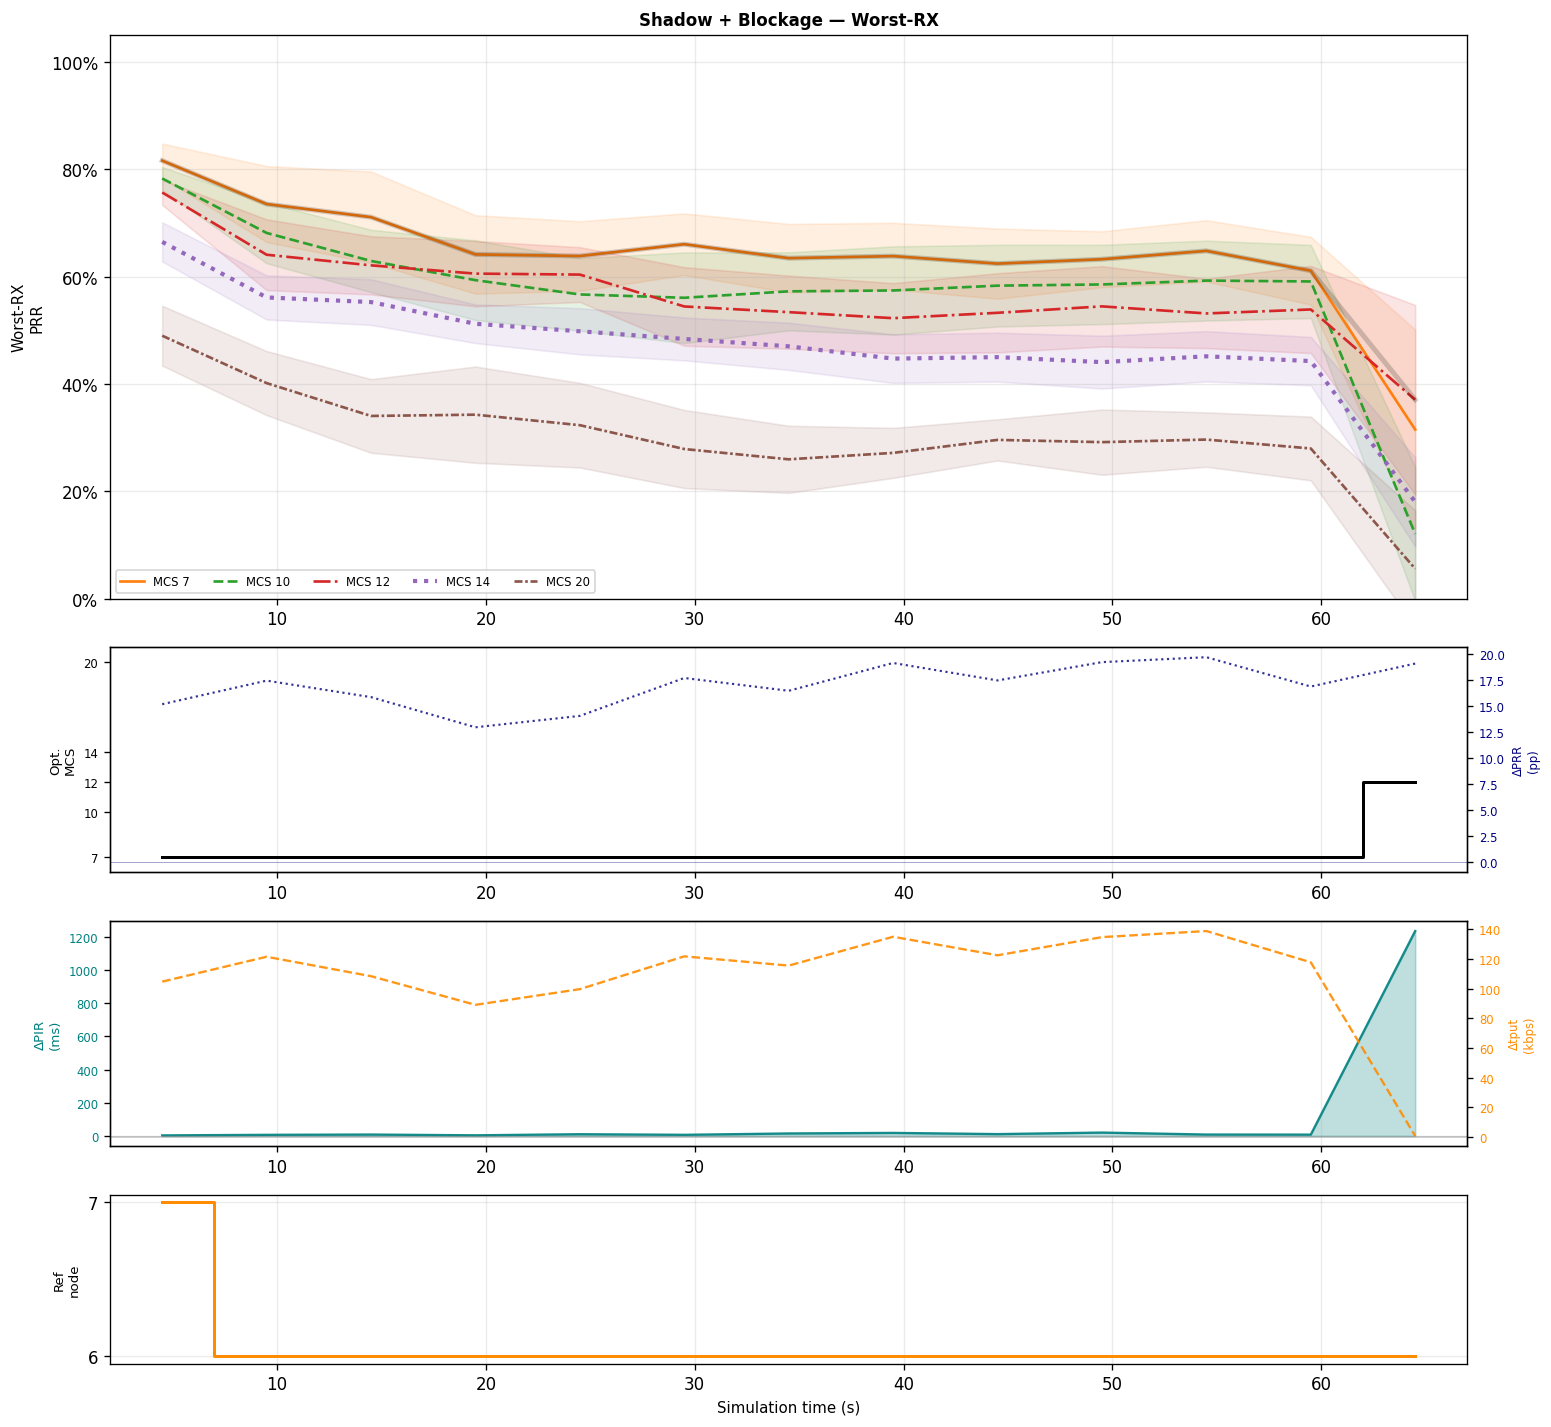

  saved → nb_worst_shadowing_blockage.png


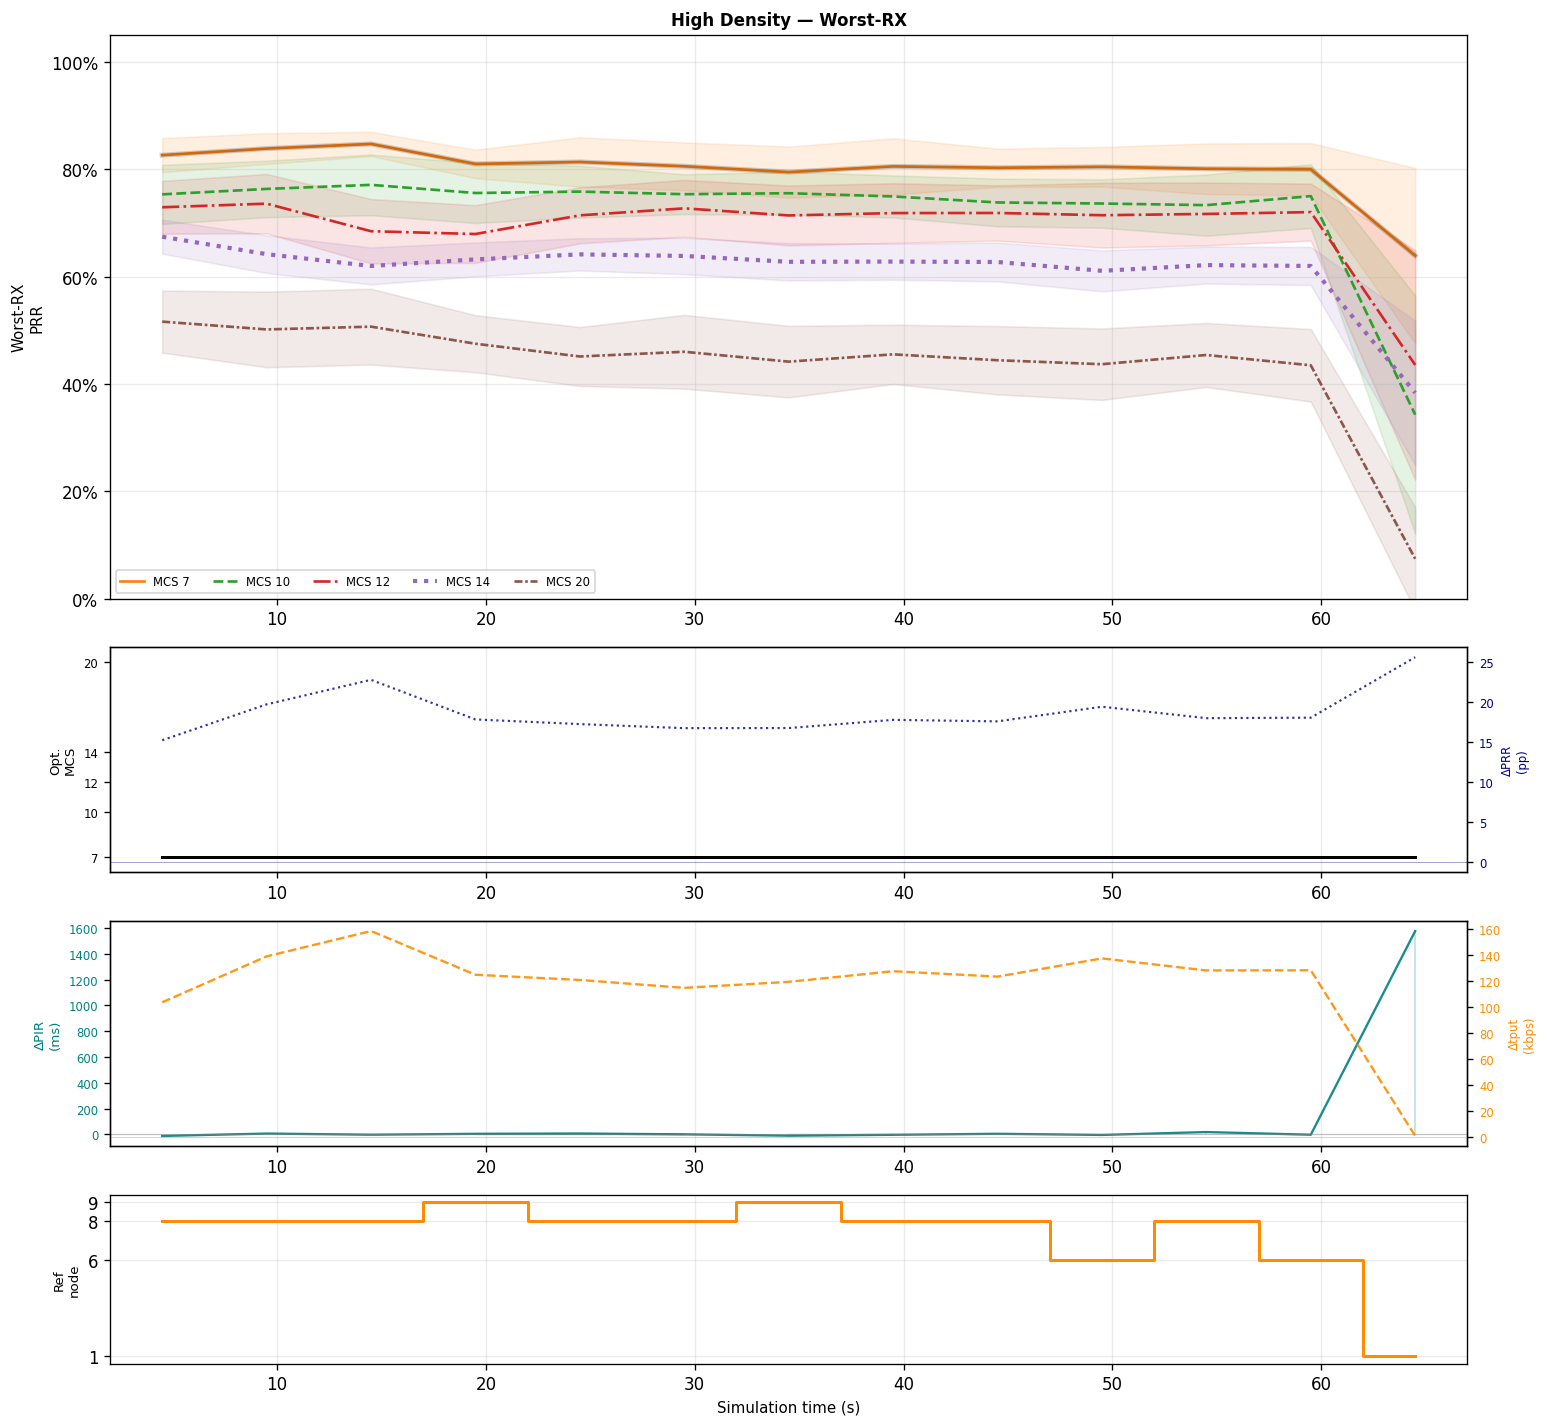

  saved → nb_worst_high_density.png


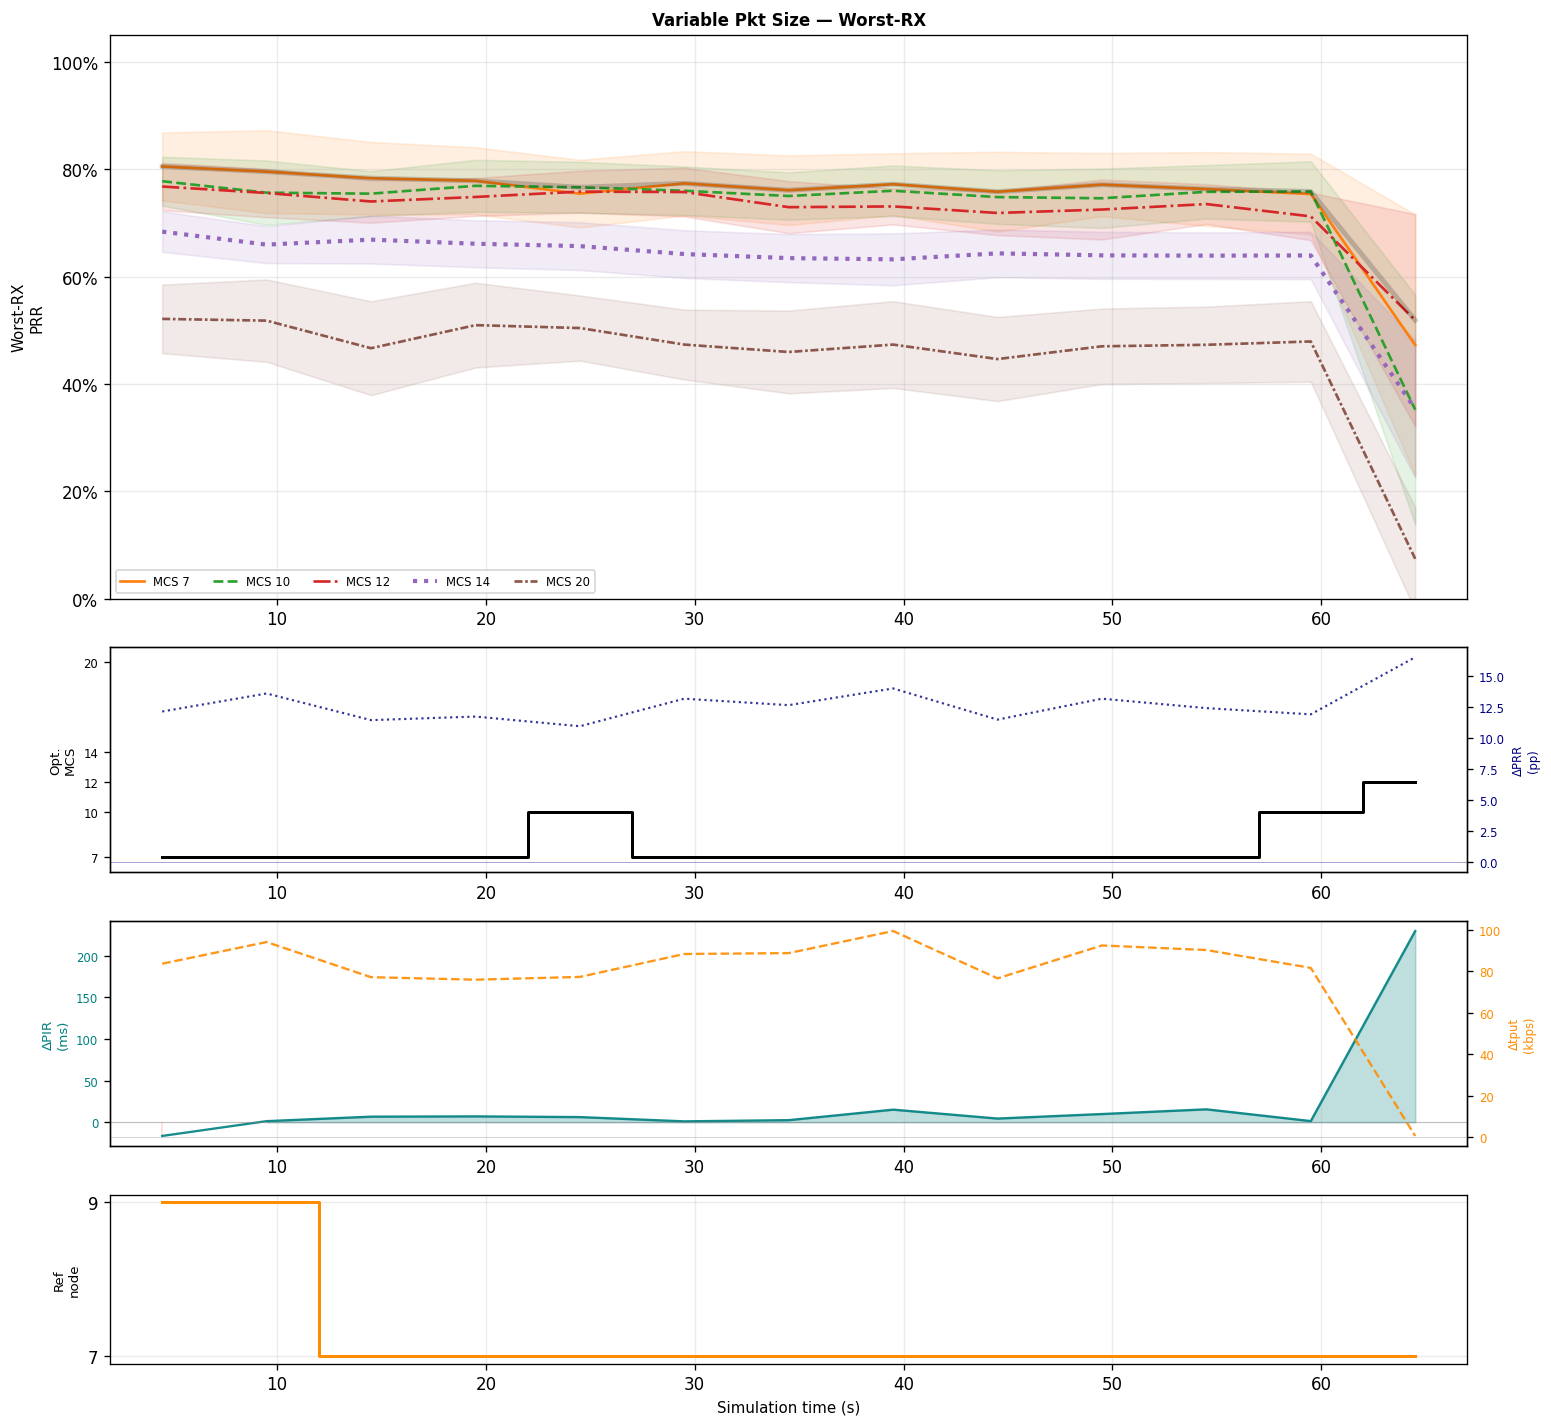

  saved → nb_worst_variable_packet_size.png


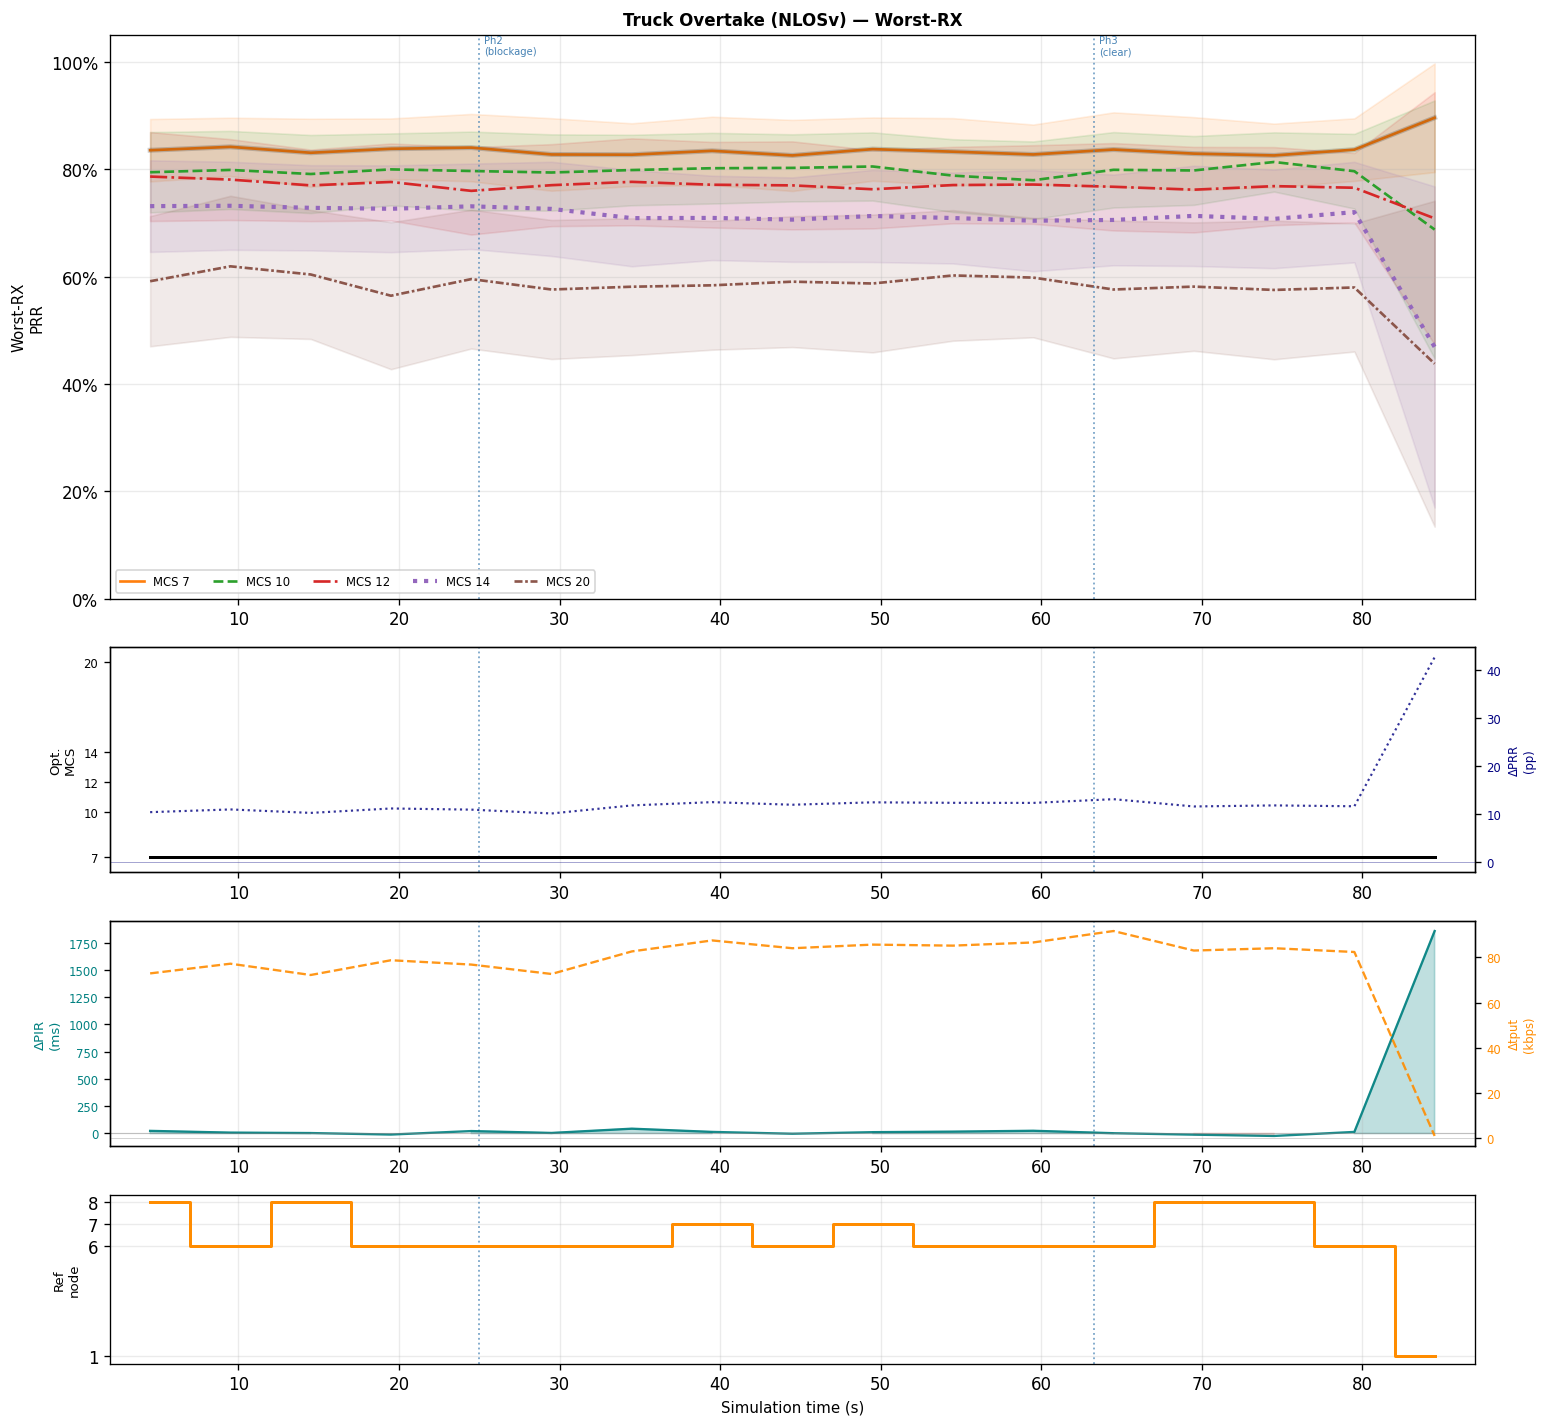

  saved → nb_worst_ccam_platoon_overtake.png


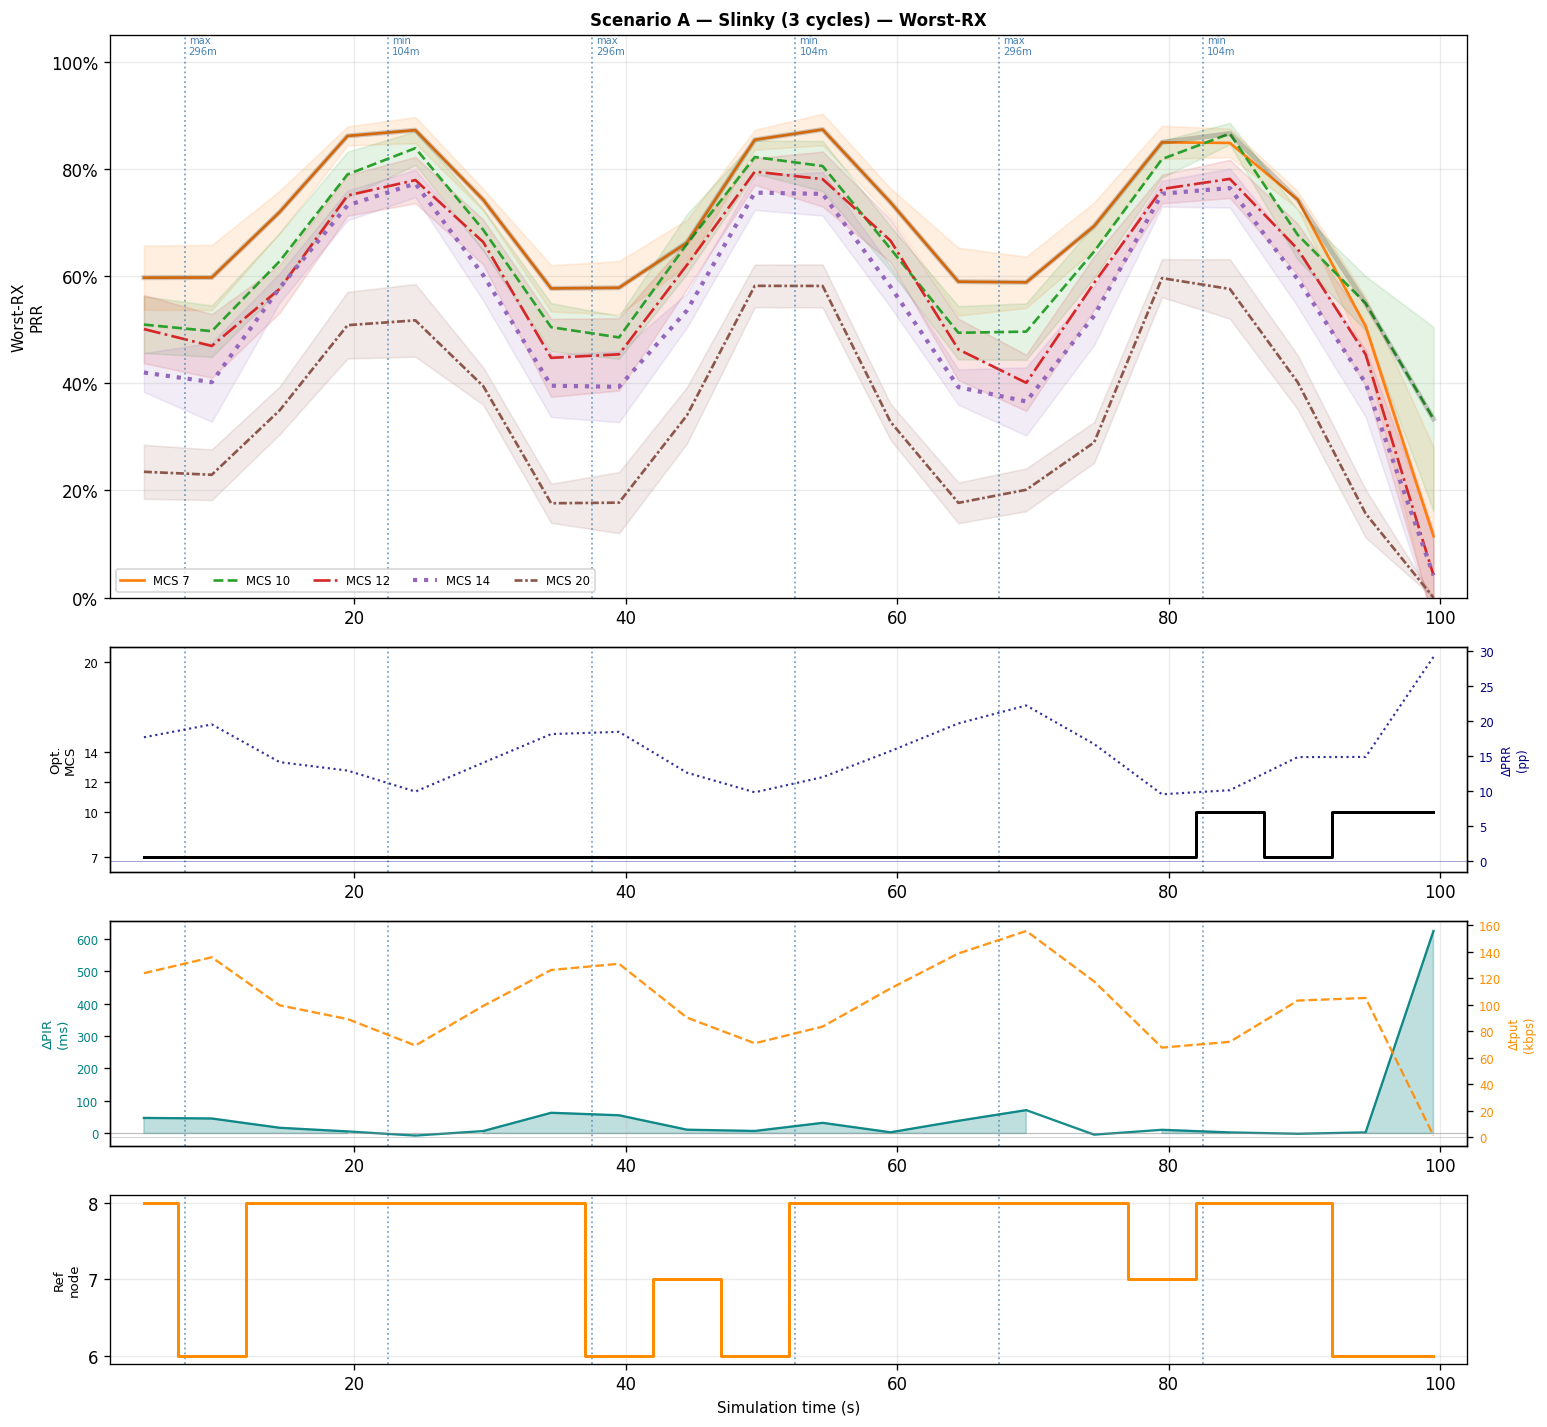

  saved → nb_worst_ccam_platoon_slinky.png


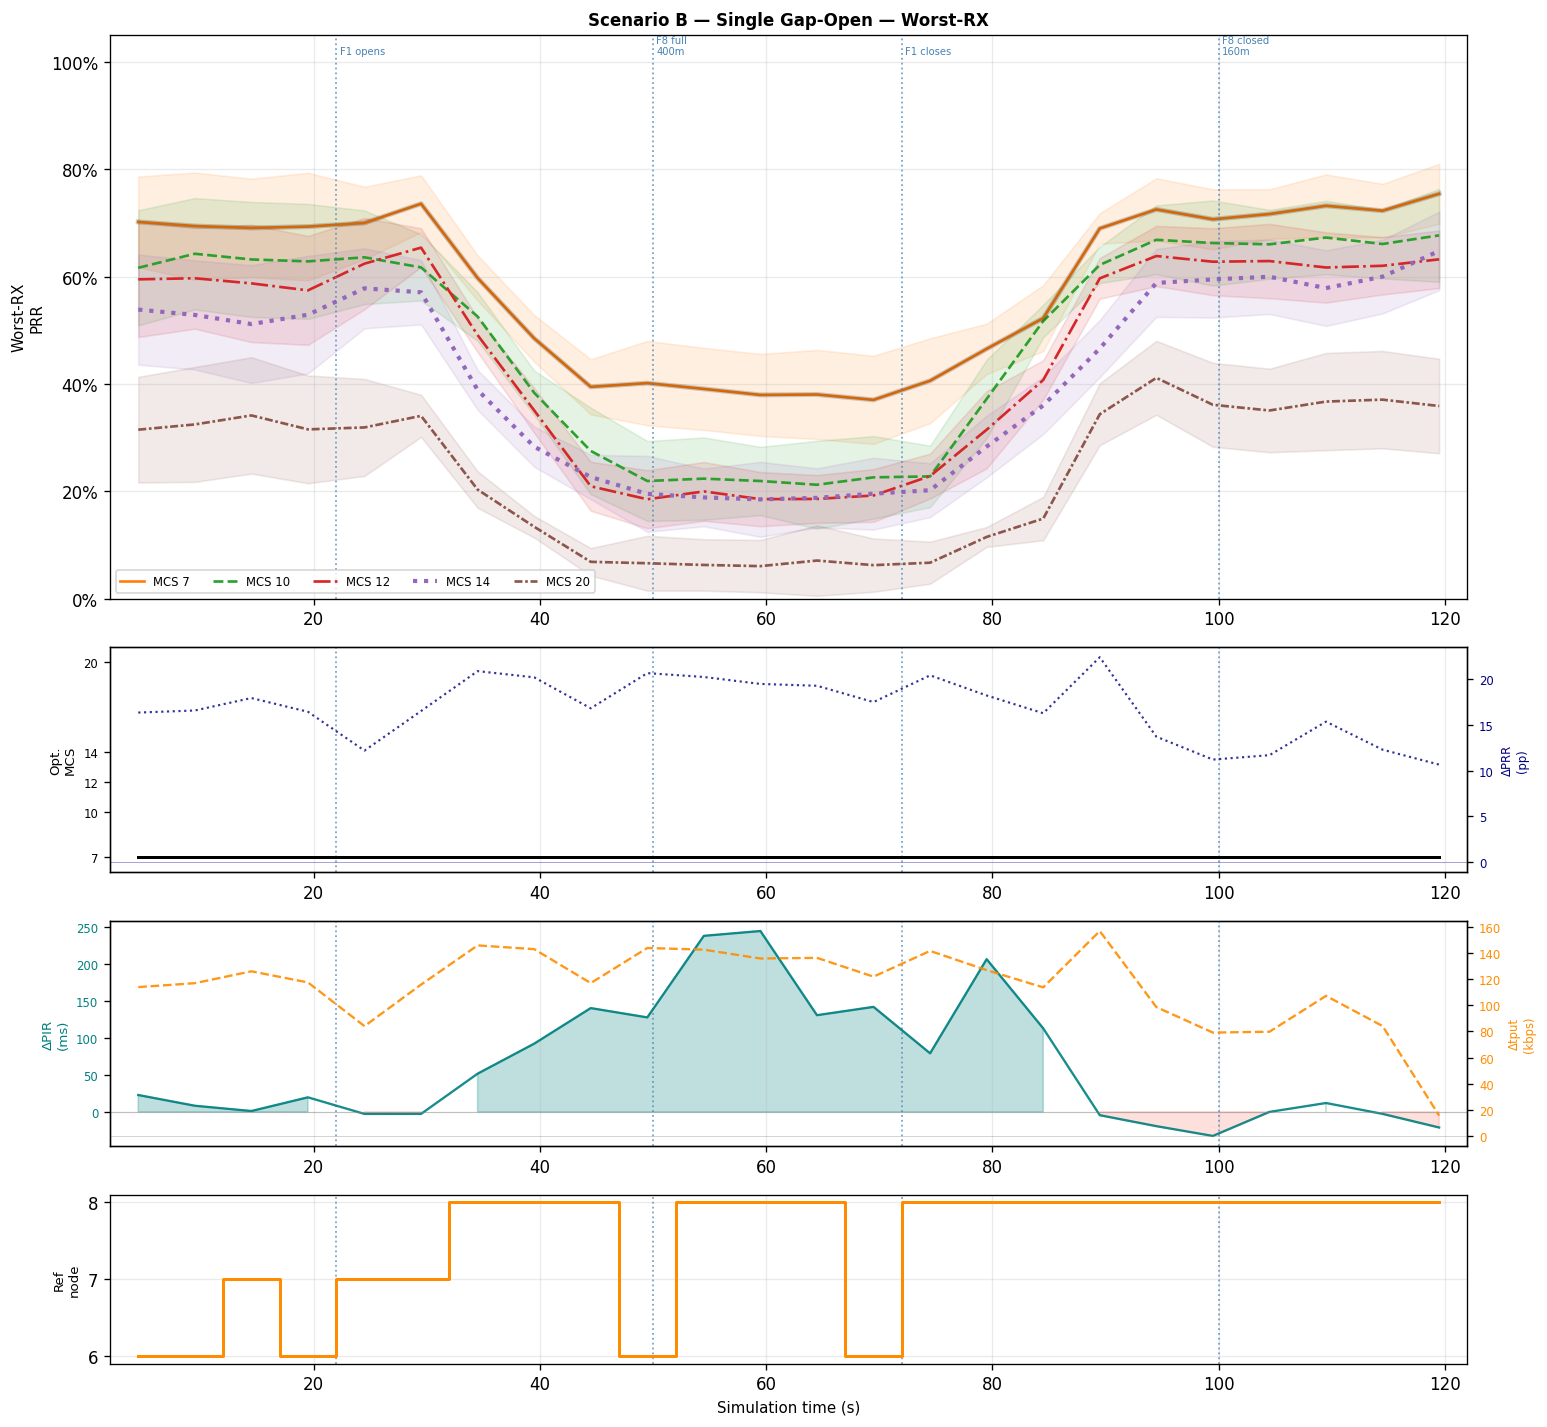

  saved → nb_worst_ccam_platoon_gap_open.png


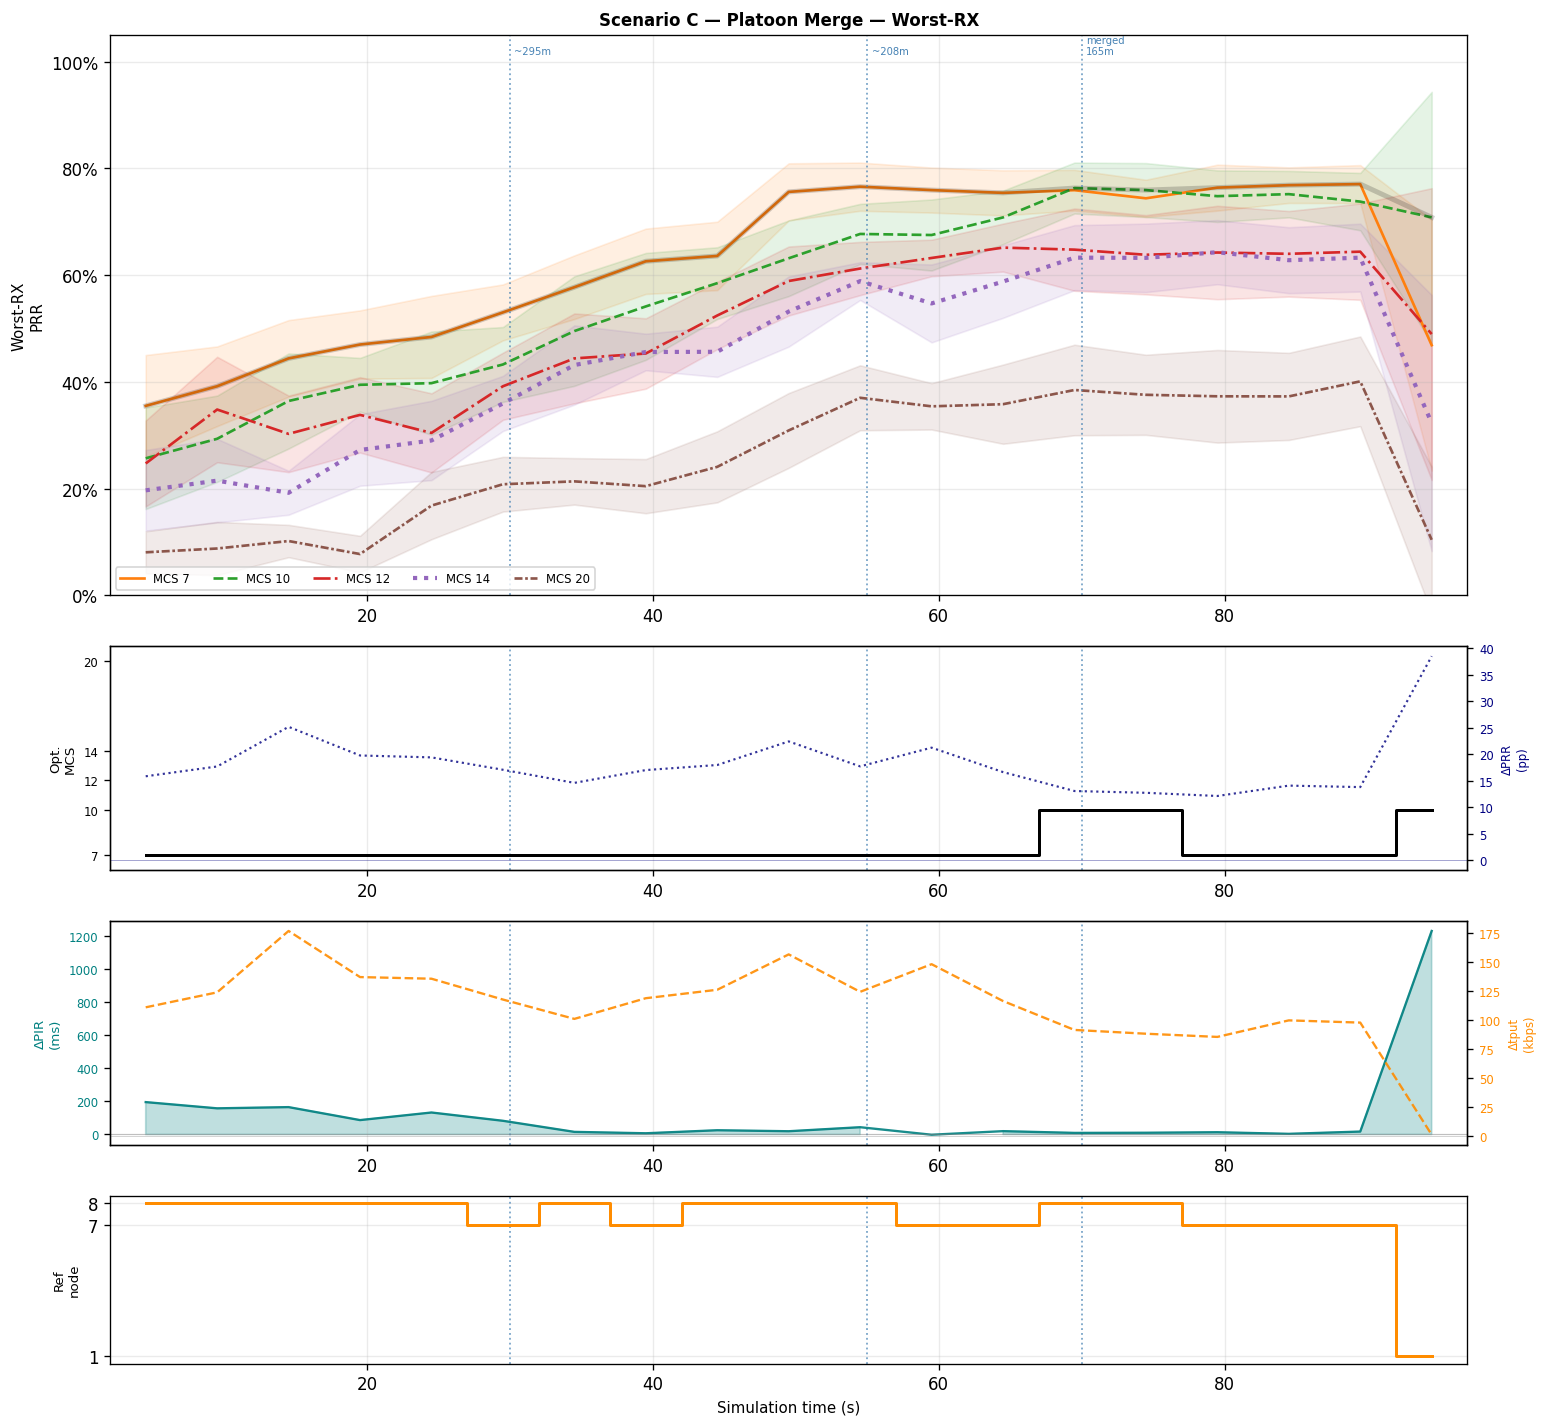

  saved → nb_worst_ccam_platoon_merge.png


In [ ]:
for scenario in RAW:
    ts  = TS[scenario]["worst"]
    opt = OPT[scenario]["worst"]

    fig, axes = plt.subplots(4, 1, figsize=(13, 12),
                              gridspec_kw={"height_ratios":[3,1.2,1.2,0.9]})
    plot_scenario_mode(scenario, "worst", ts, opt, *axes)
    plt.tight_layout()
    out = PLOT_DIR / f"nb_worst_{scenario}.png"
    fig.savefig(out, dpi=130, bbox_inches="tight")
    plt.show()
    print(f"  saved → {out.name}")

---
## 6. Per-Scenario Time-Series: p5-RX

Same 4-panel layout. p5 PRR = 5th-percentile PRR over all 8 RX nodes per window per seed.

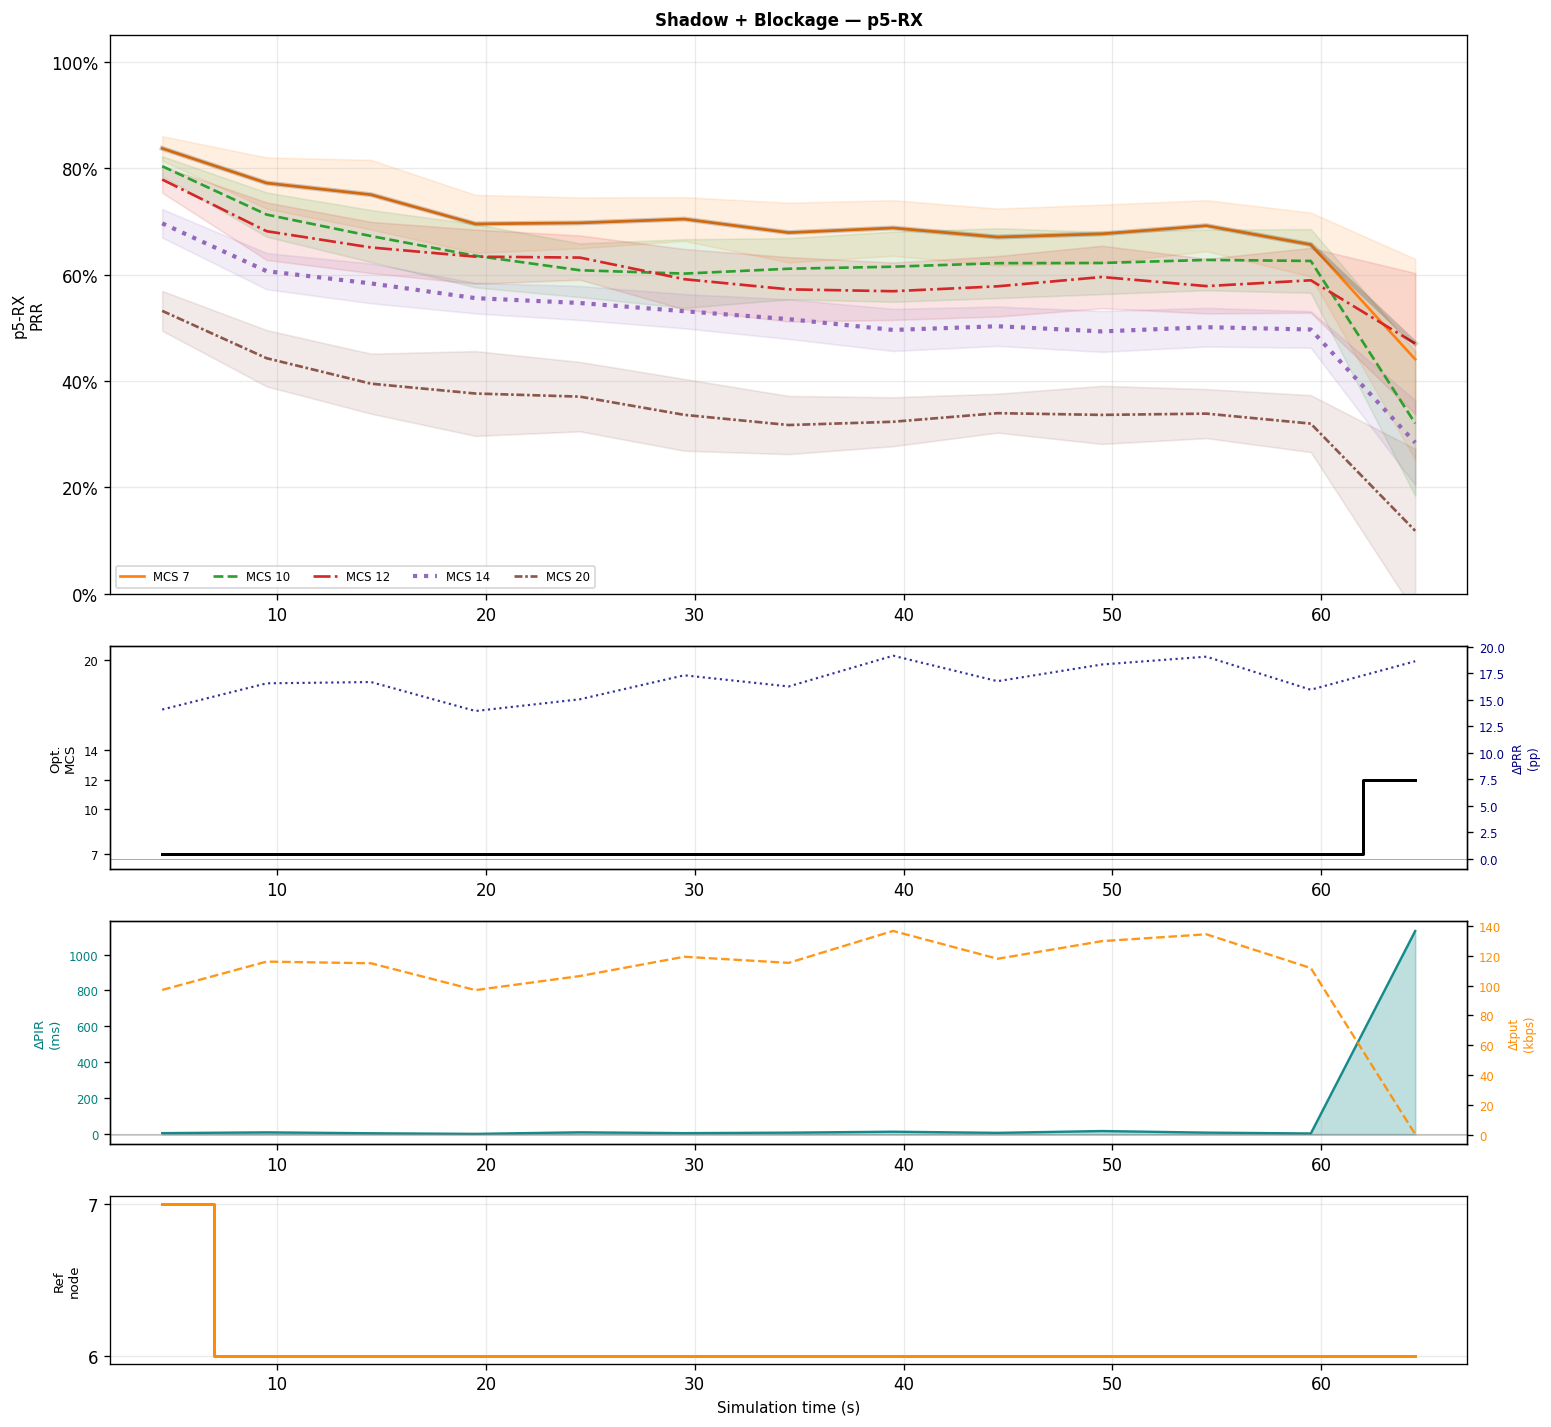

  saved → nb_p5_shadowing_blockage.png


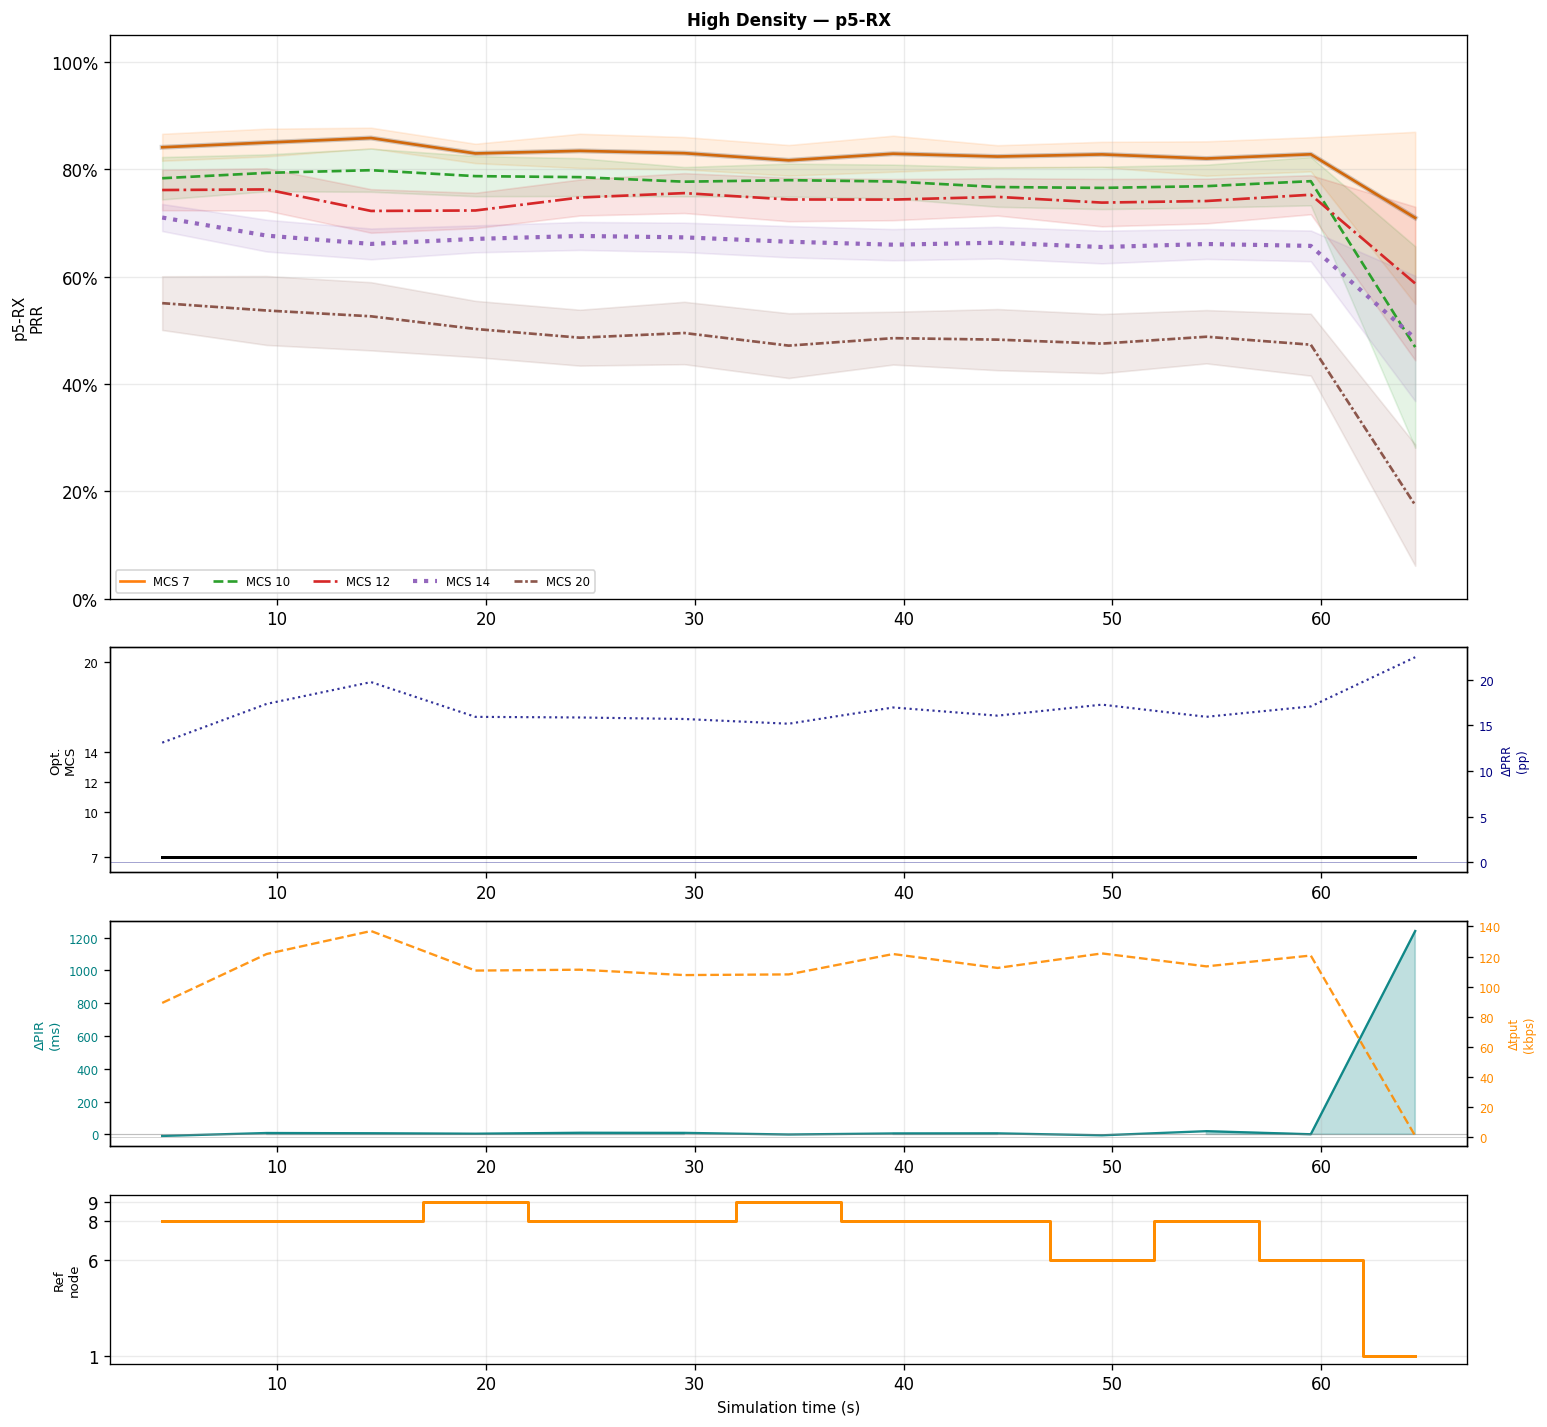

  saved → nb_p5_high_density.png


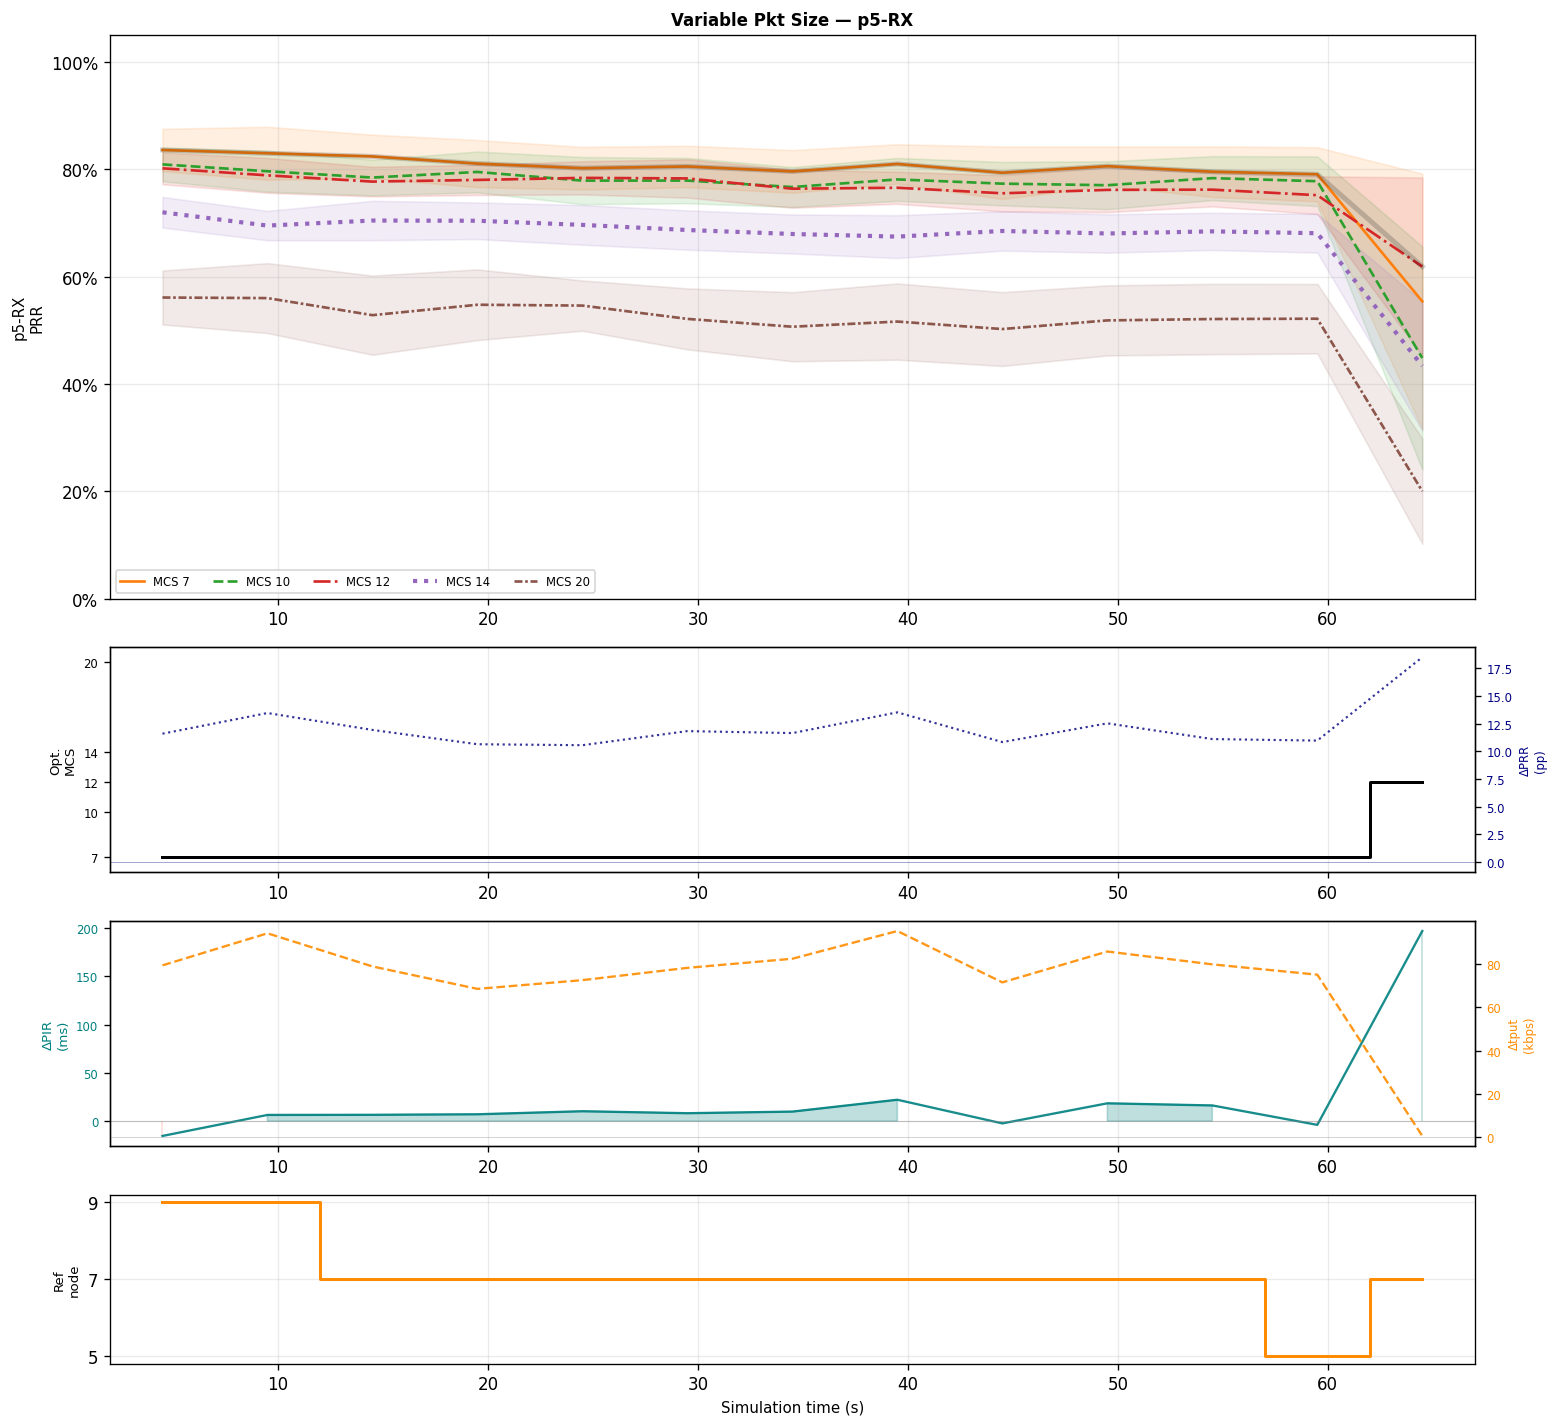

  saved → nb_p5_variable_packet_size.png


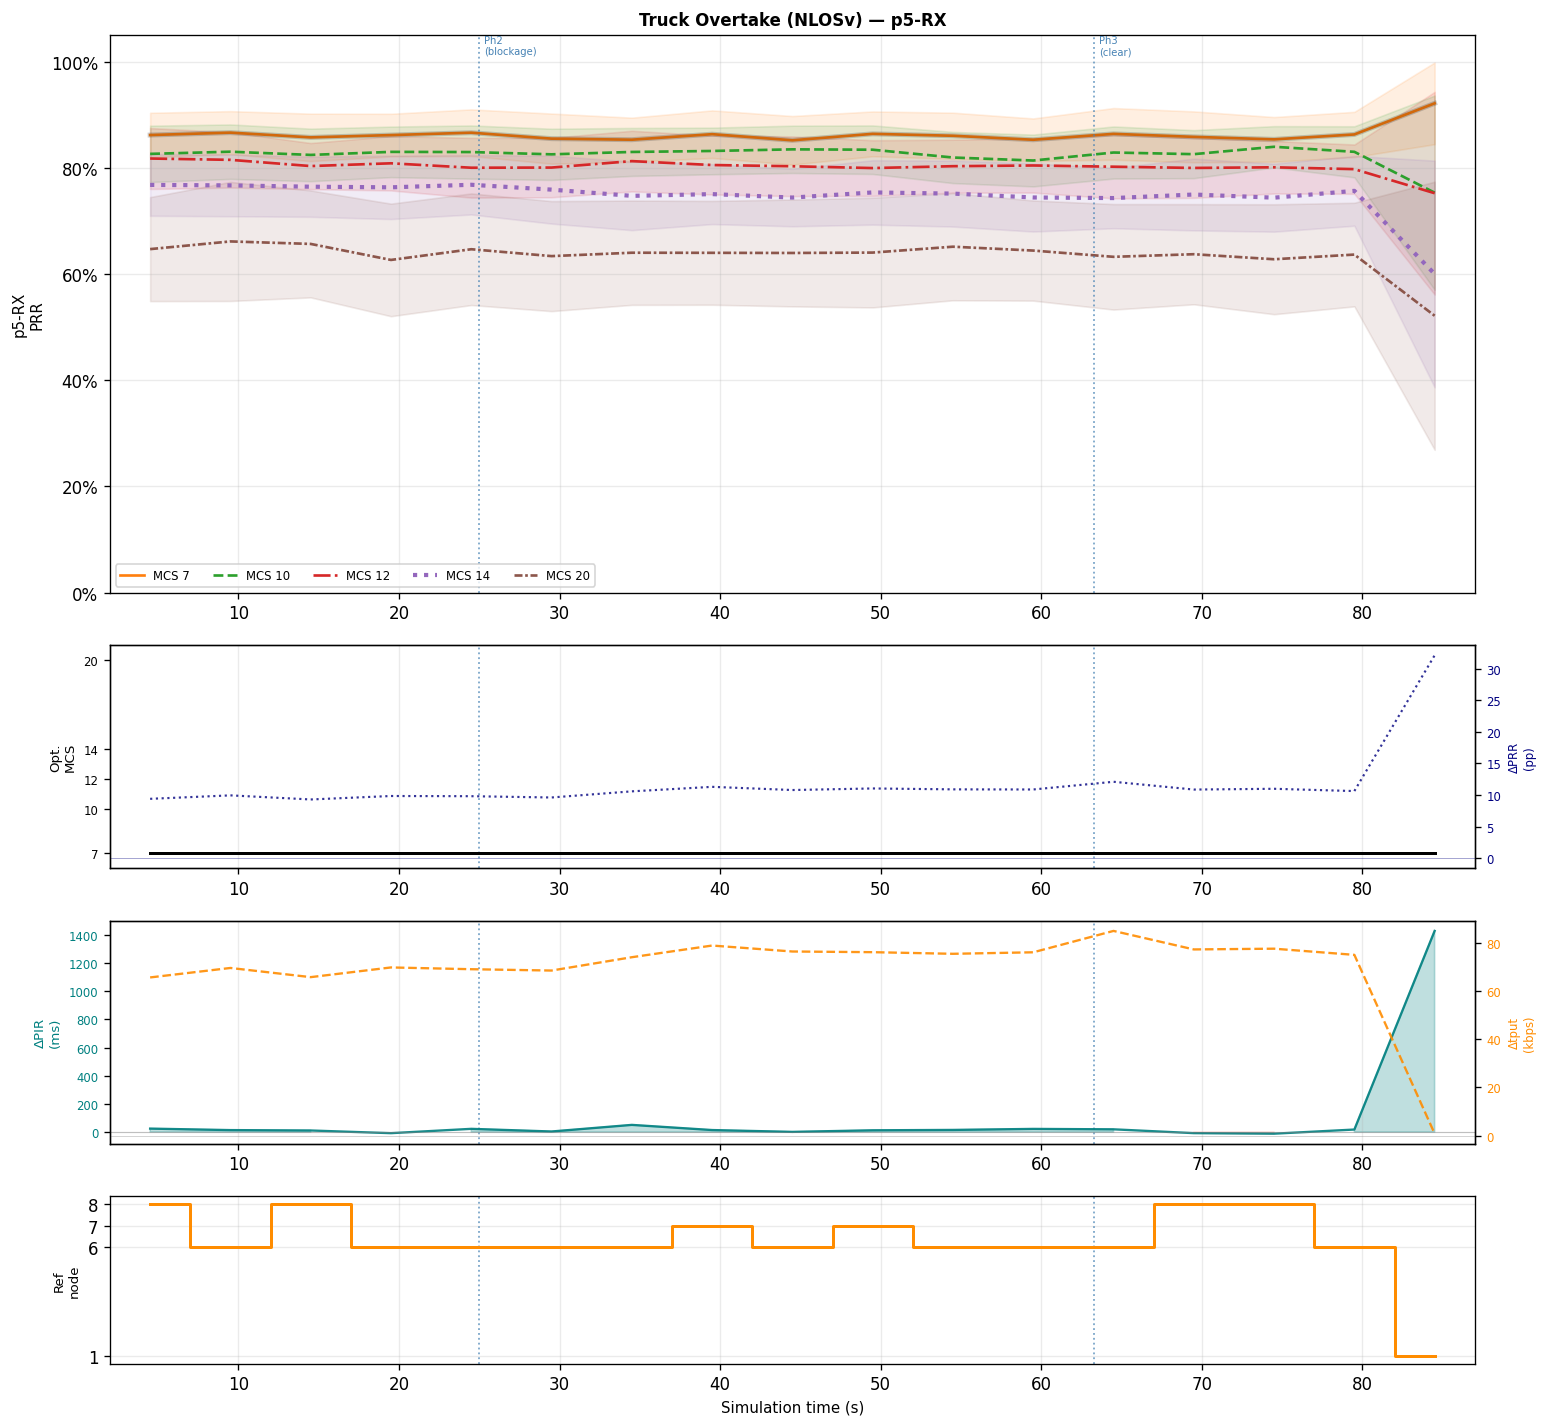

  saved → nb_p5_ccam_platoon_overtake.png


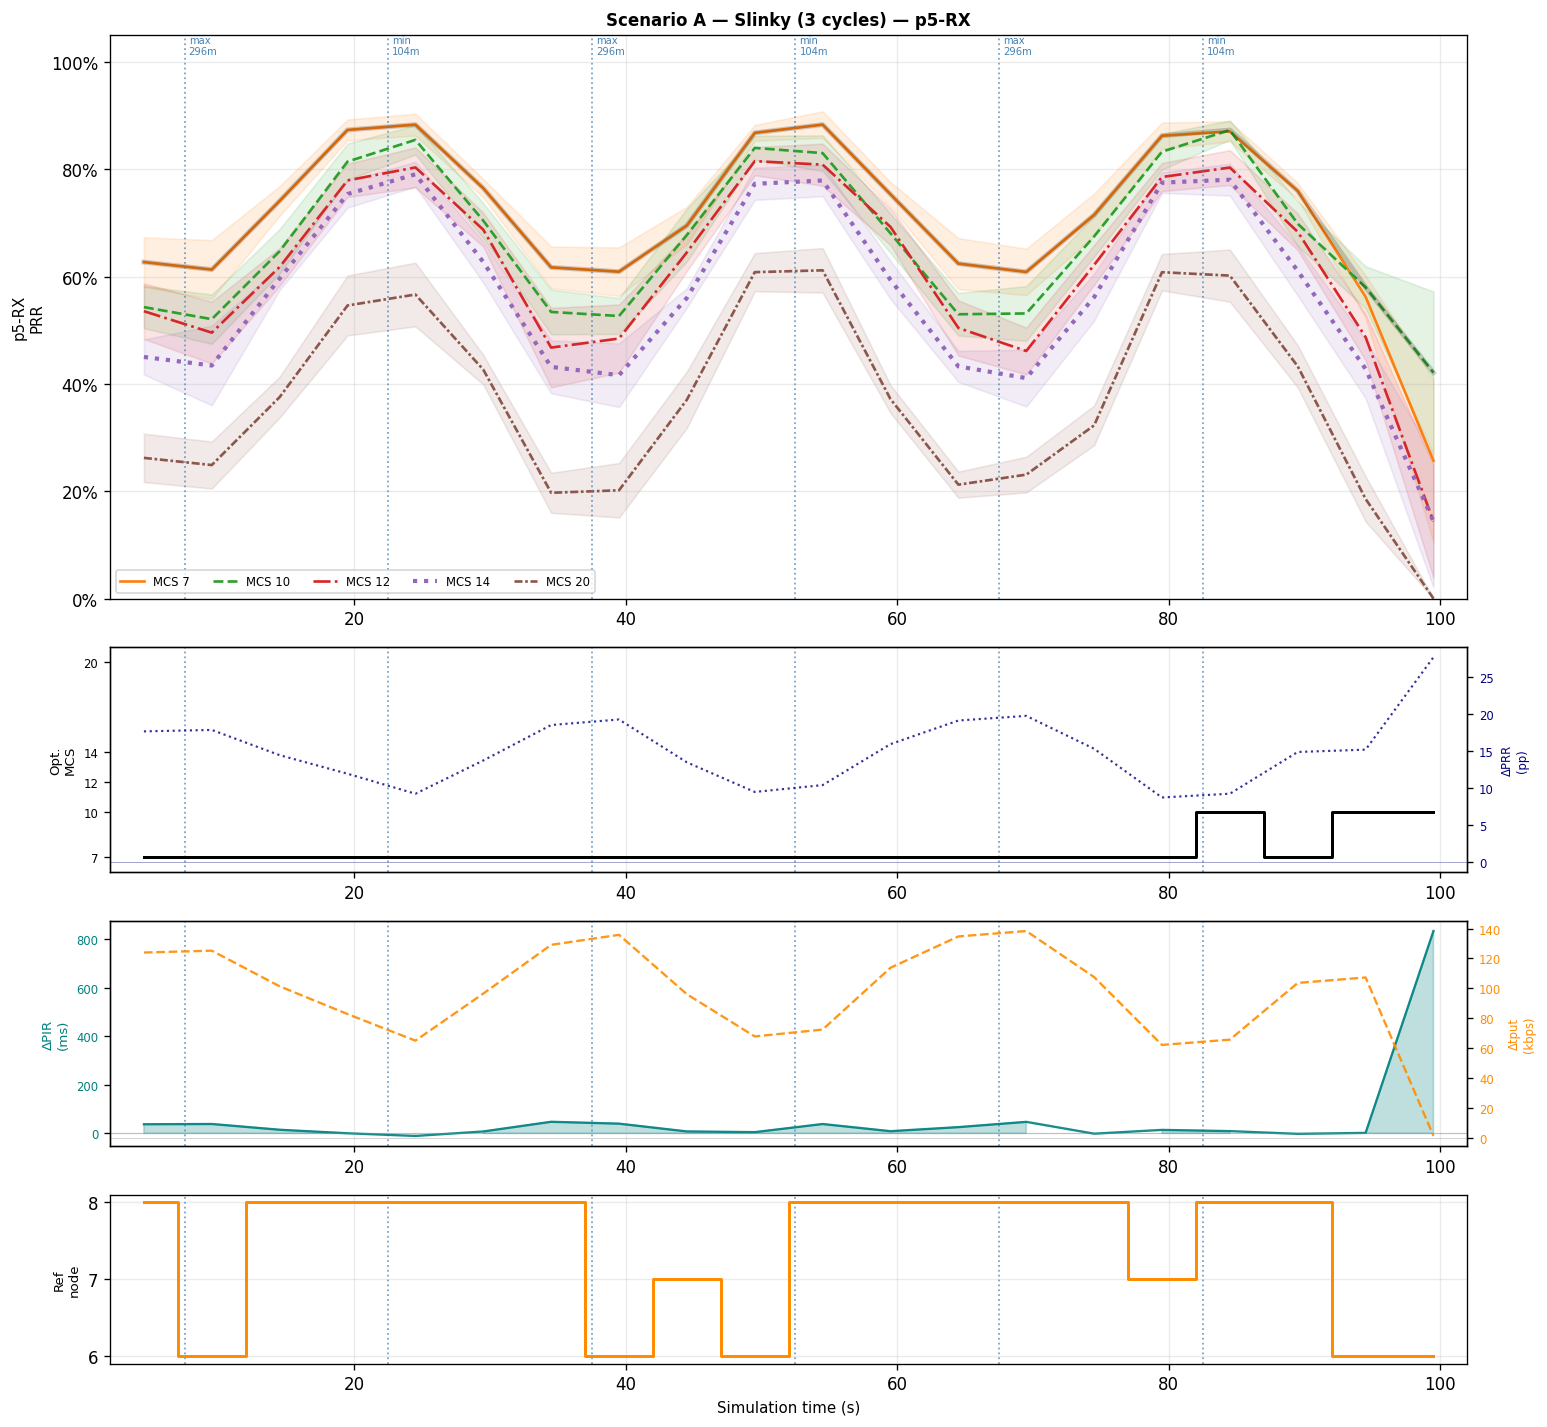

  saved → nb_p5_ccam_platoon_slinky.png


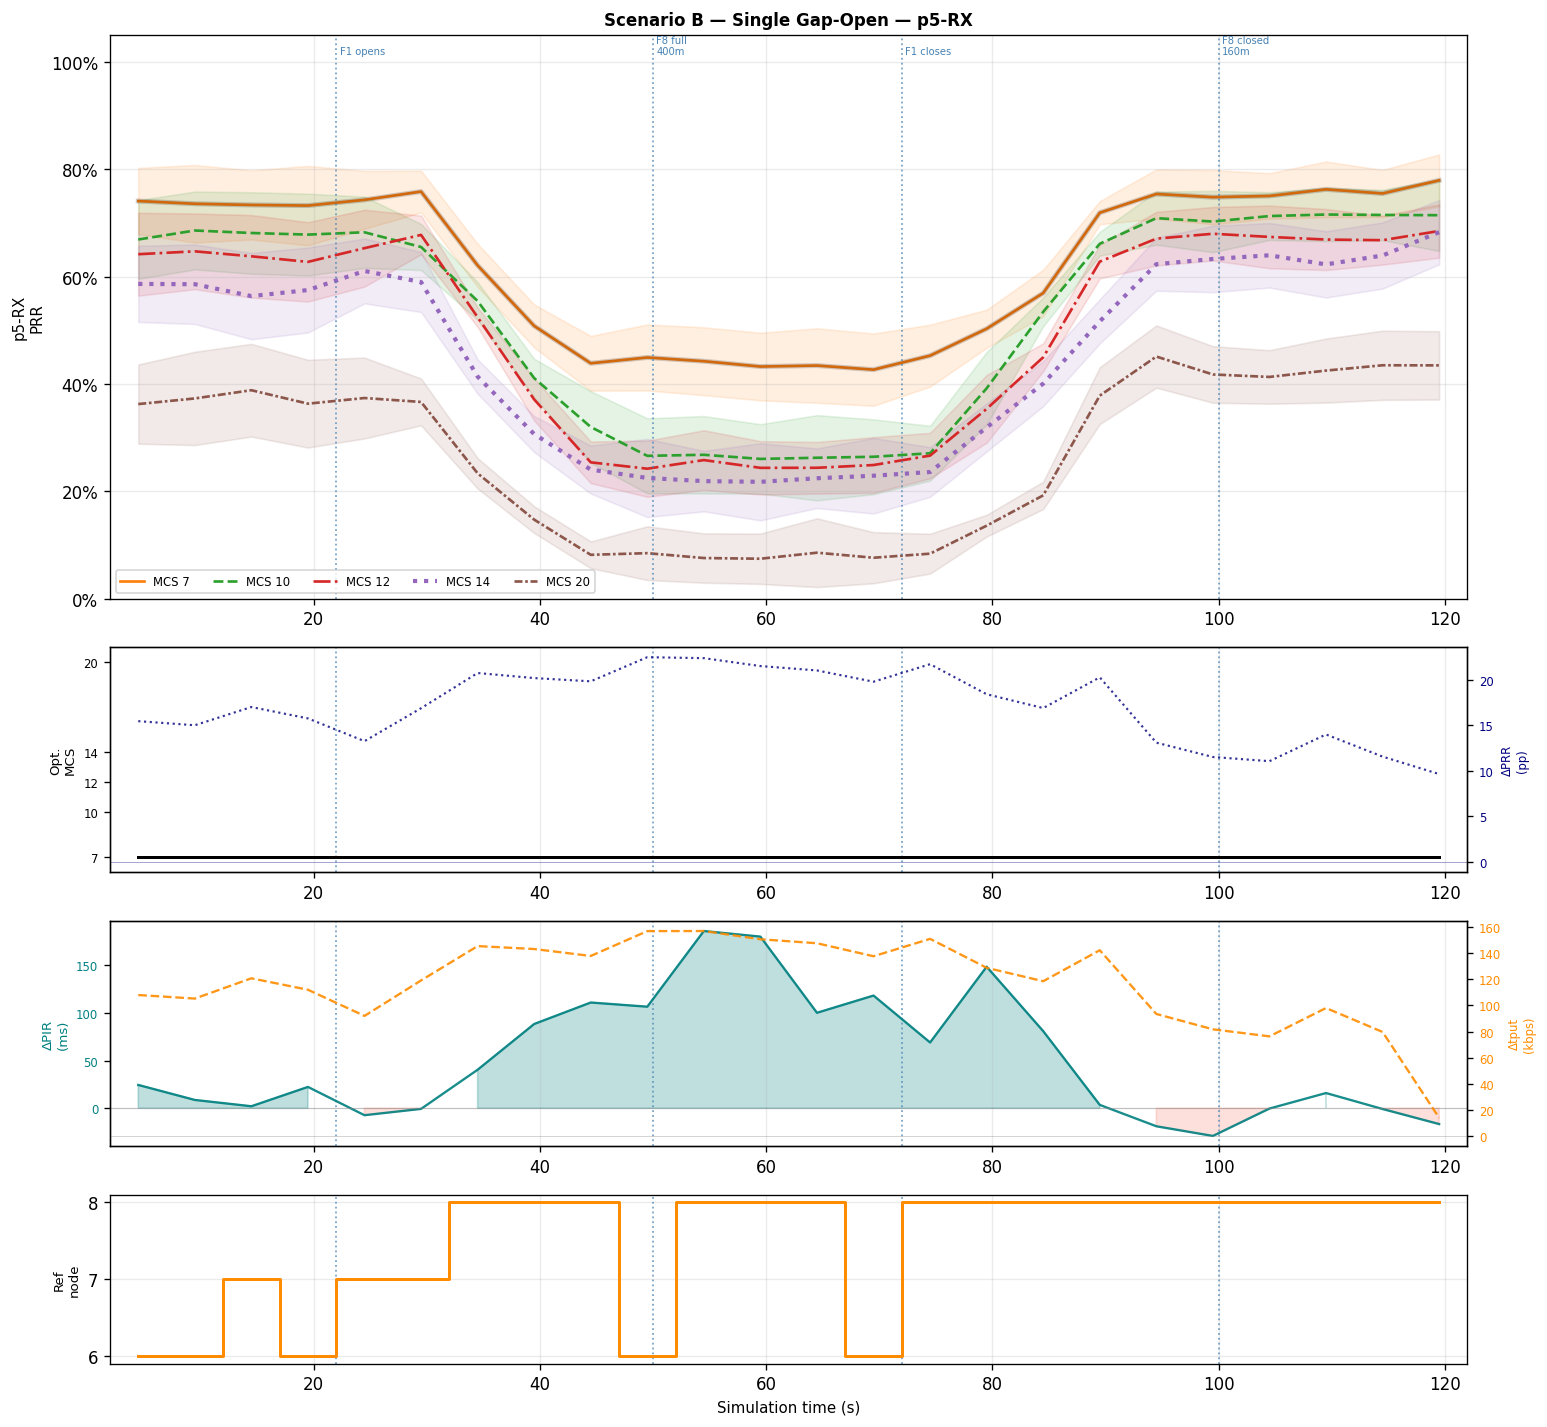

  saved → nb_p5_ccam_platoon_gap_open.png


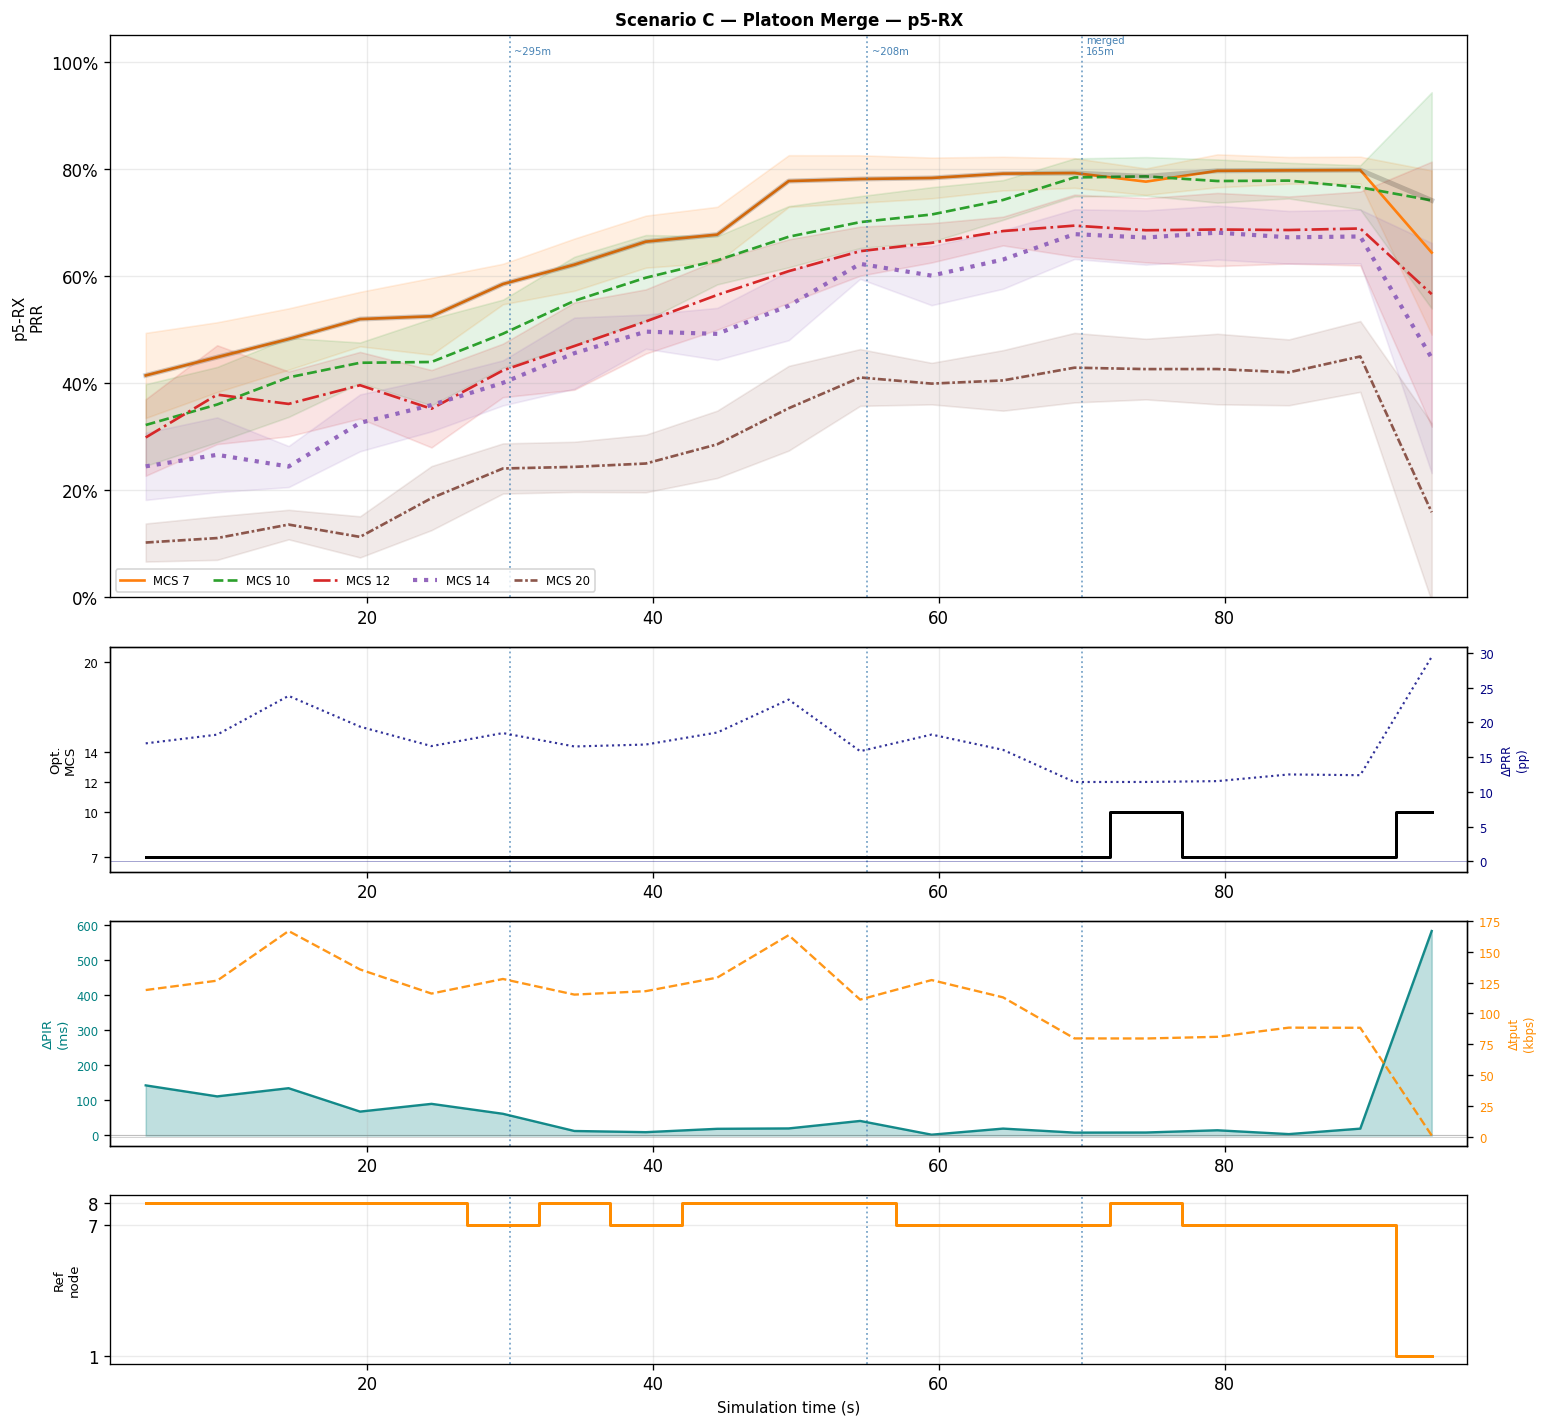

  saved → nb_p5_ccam_platoon_merge.png


In [ ]:
for scenario in RAW:
    ts  = TS[scenario]["p5"]
    opt = OPT[scenario]["p5"]

    fig, axes = plt.subplots(4, 1, figsize=(13, 12),
                              gridspec_kw={"height_ratios":[3,1.2,1.2,0.9]})
    plot_scenario_mode(scenario, "p5", ts, opt, *axes)
    plt.tight_layout()
    out = PLOT_DIR / f"nb_p5_{scenario}.png"
    fig.savefig(out, dpi=130, bbox_inches="tight")
    plt.show()
    print(f"  saved → {out.name}")

---
## 7. Side-by-Side Comparison: Worst-RX vs p5-RX

For each scenario, the two PRR curves (one per mode) are plotted together to visualise the gap between the absolute worst node and the p5 node.

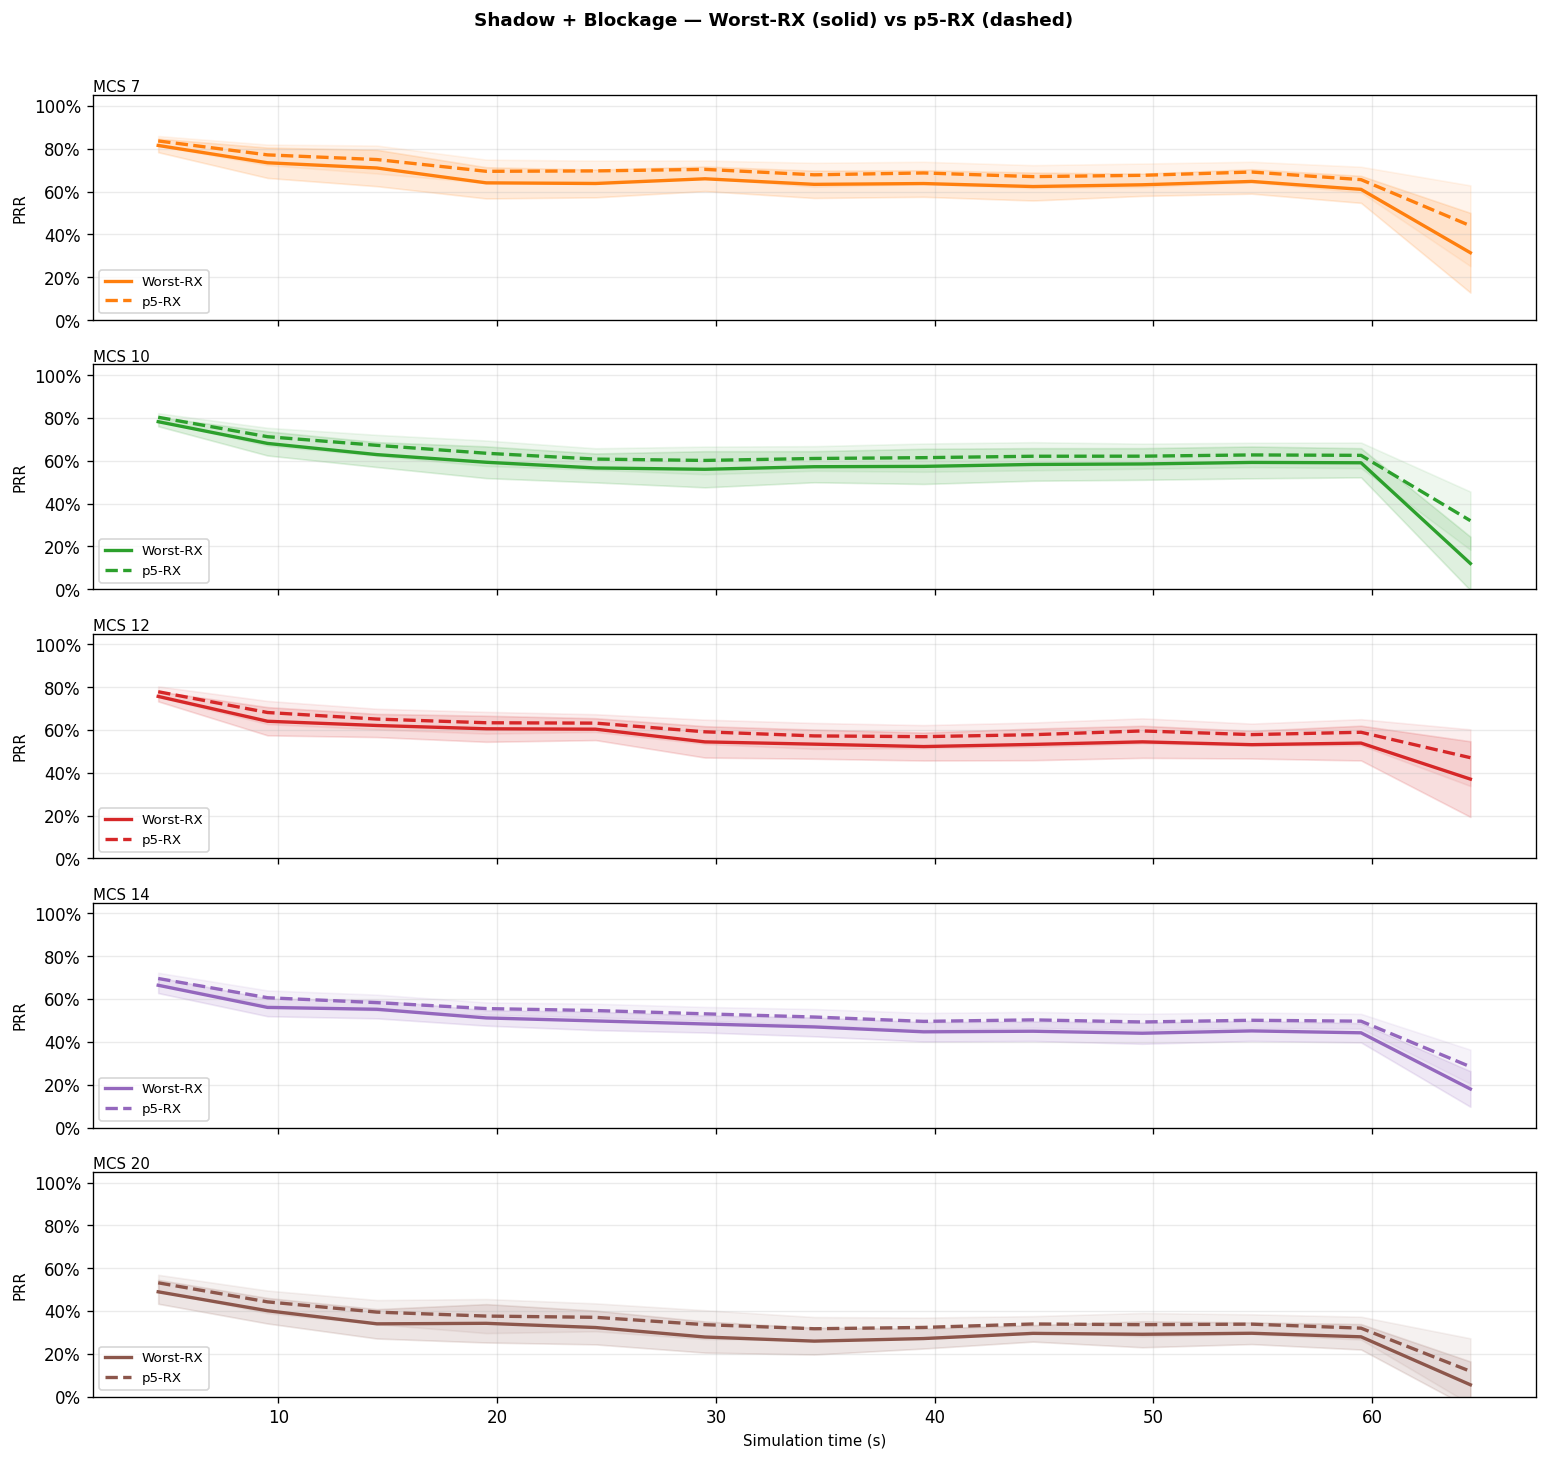

  saved → nb_worst_vs_p5_shadowing_blockage.png


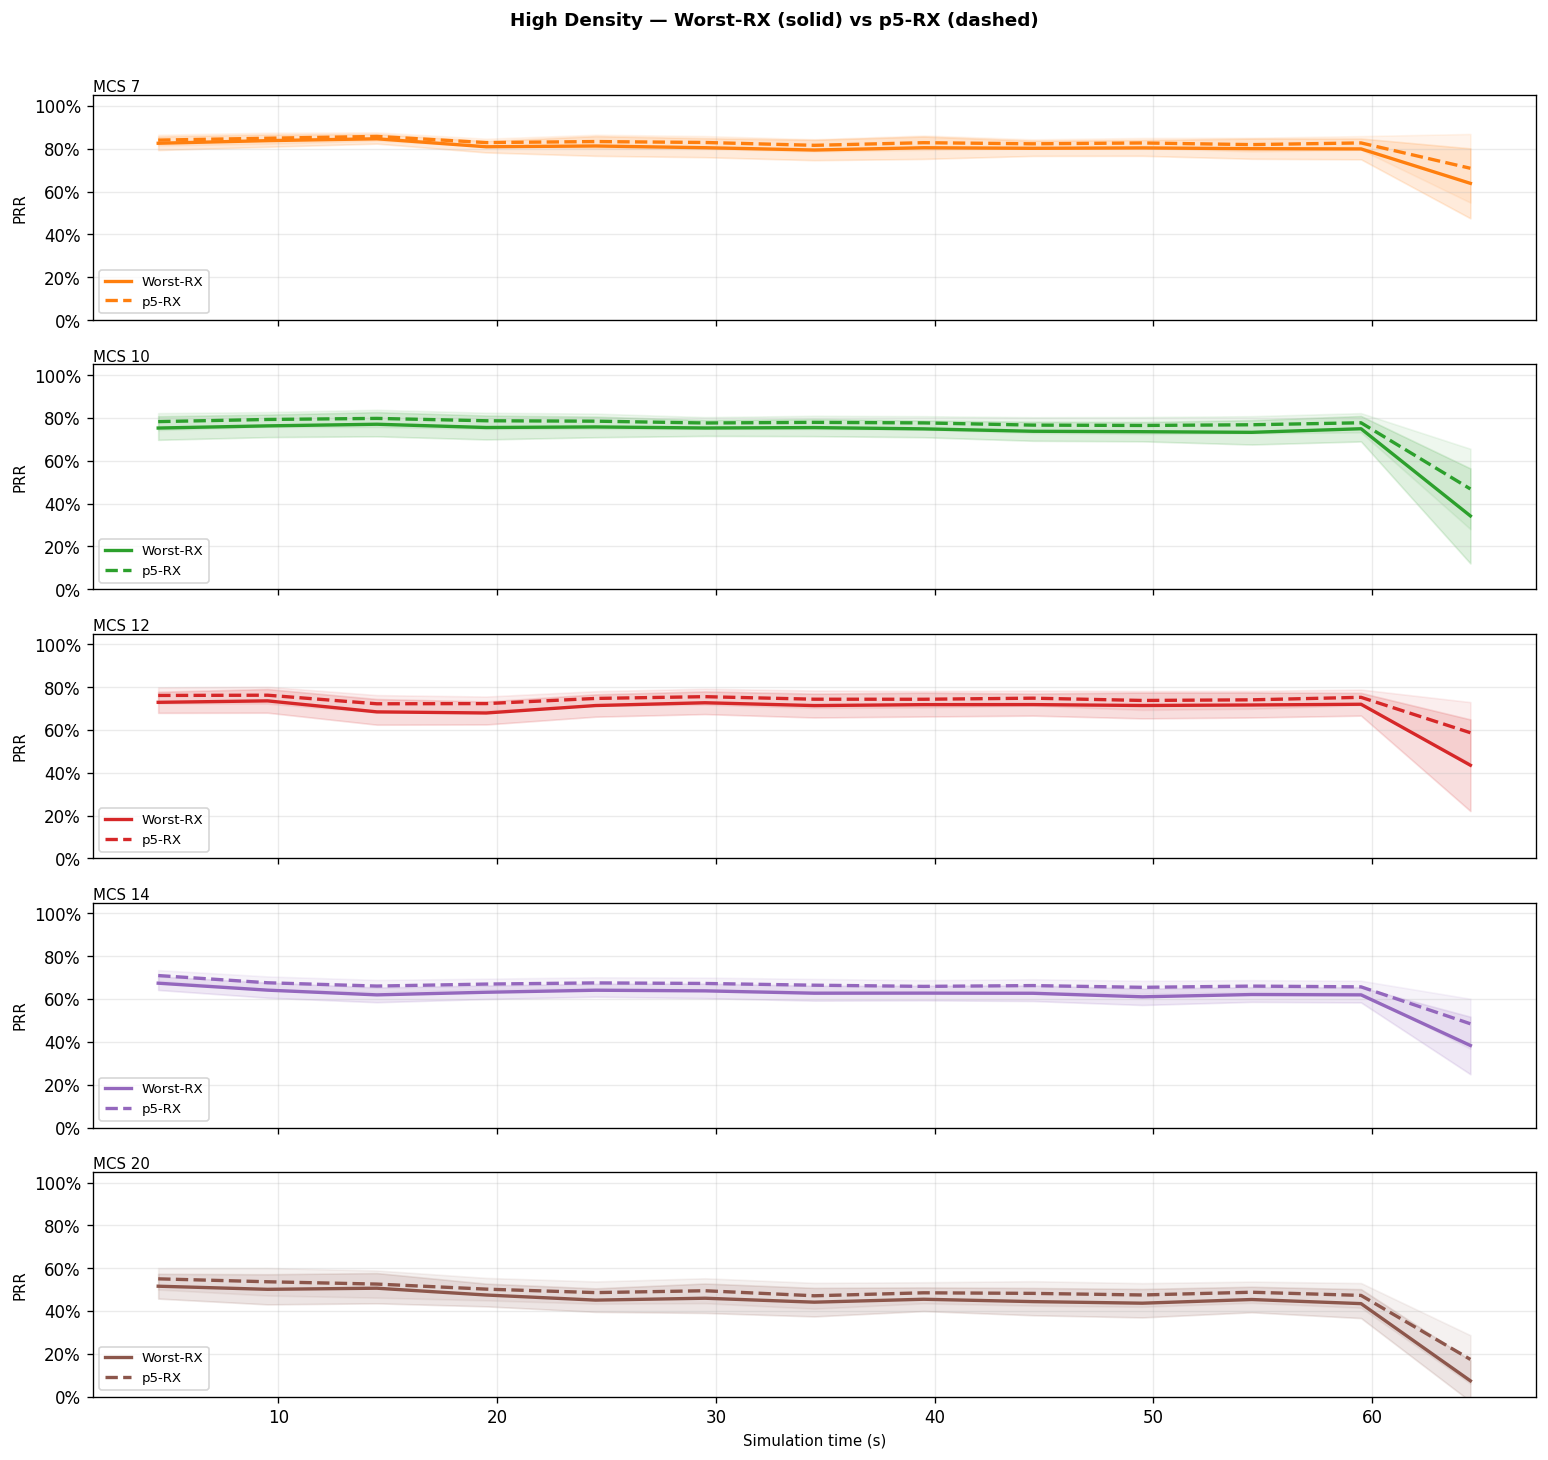

  saved → nb_worst_vs_p5_high_density.png


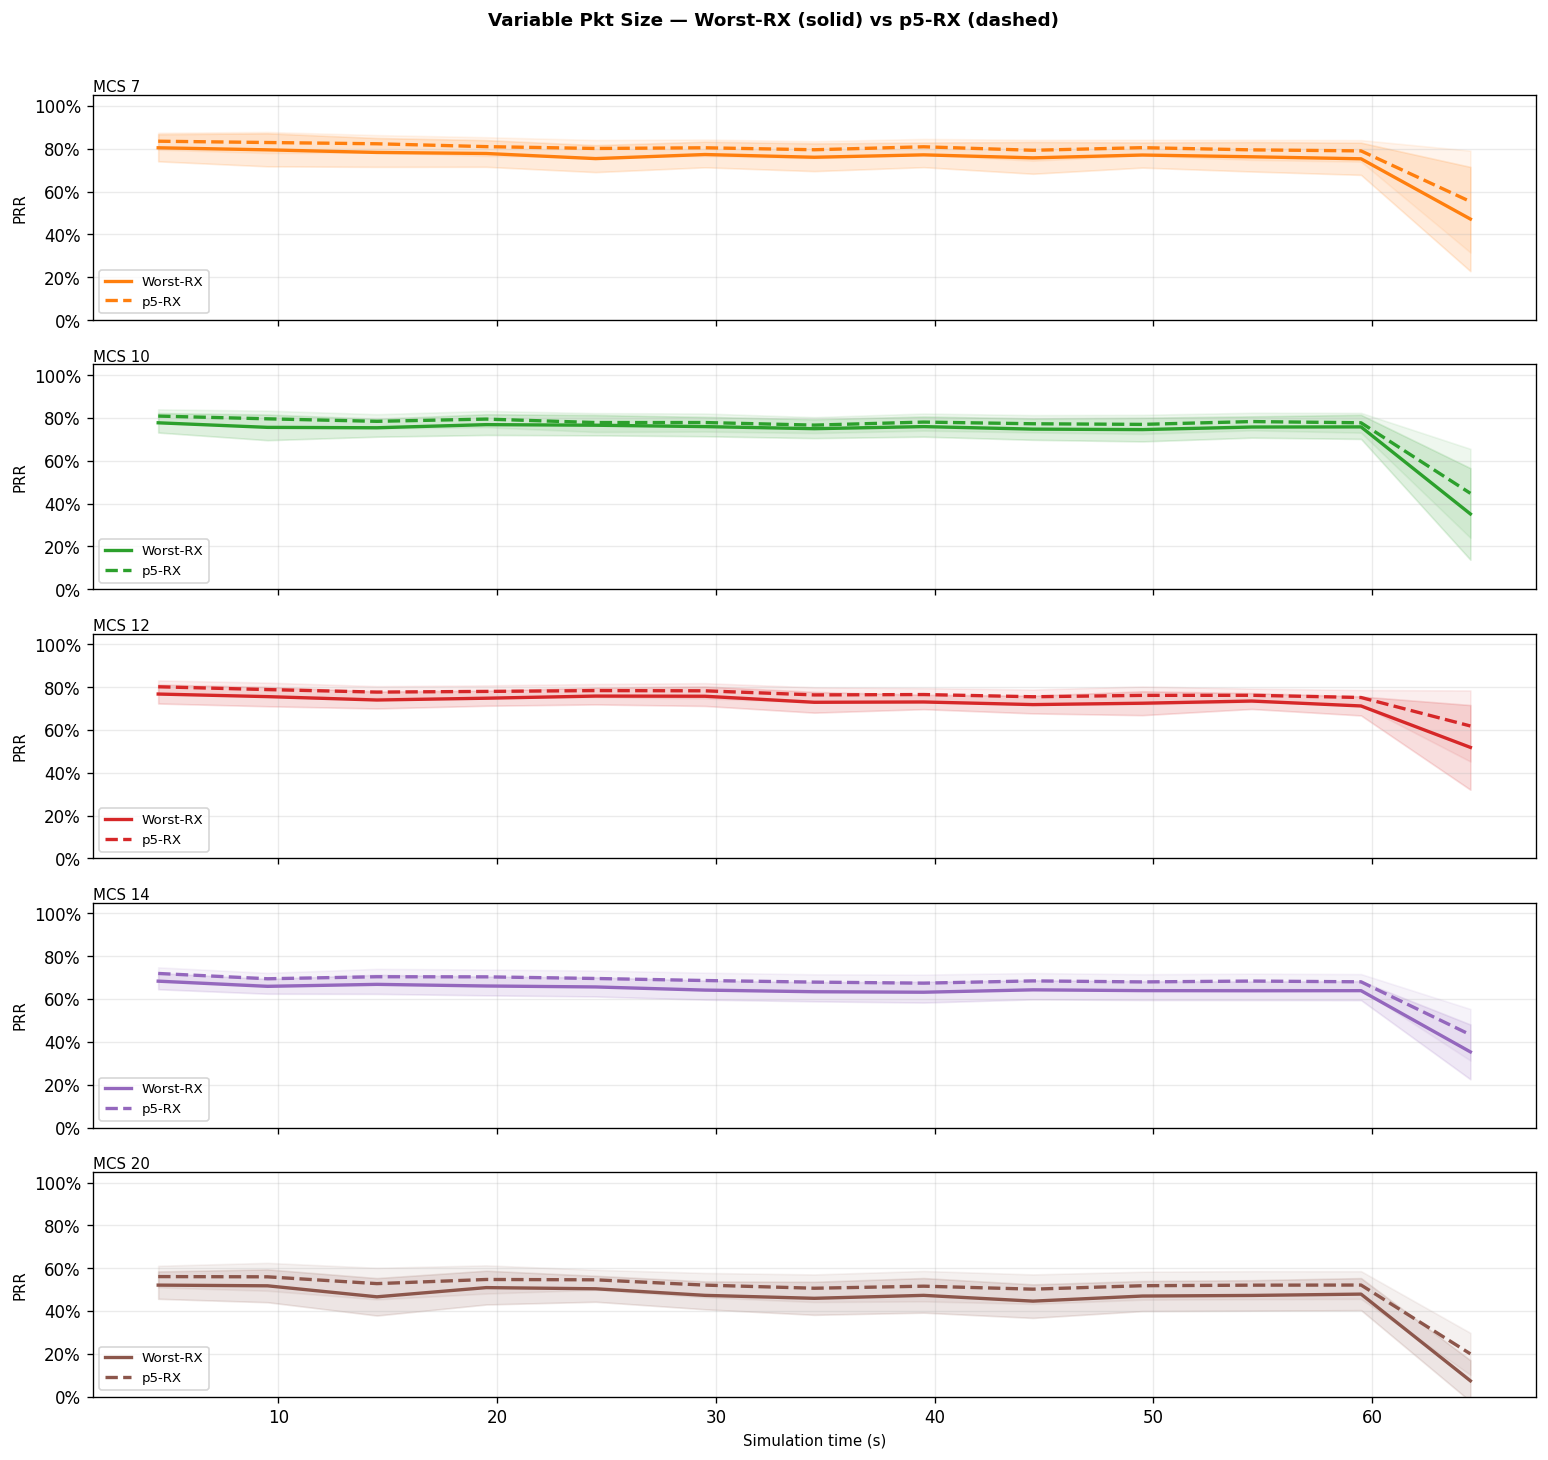

  saved → nb_worst_vs_p5_variable_packet_size.png


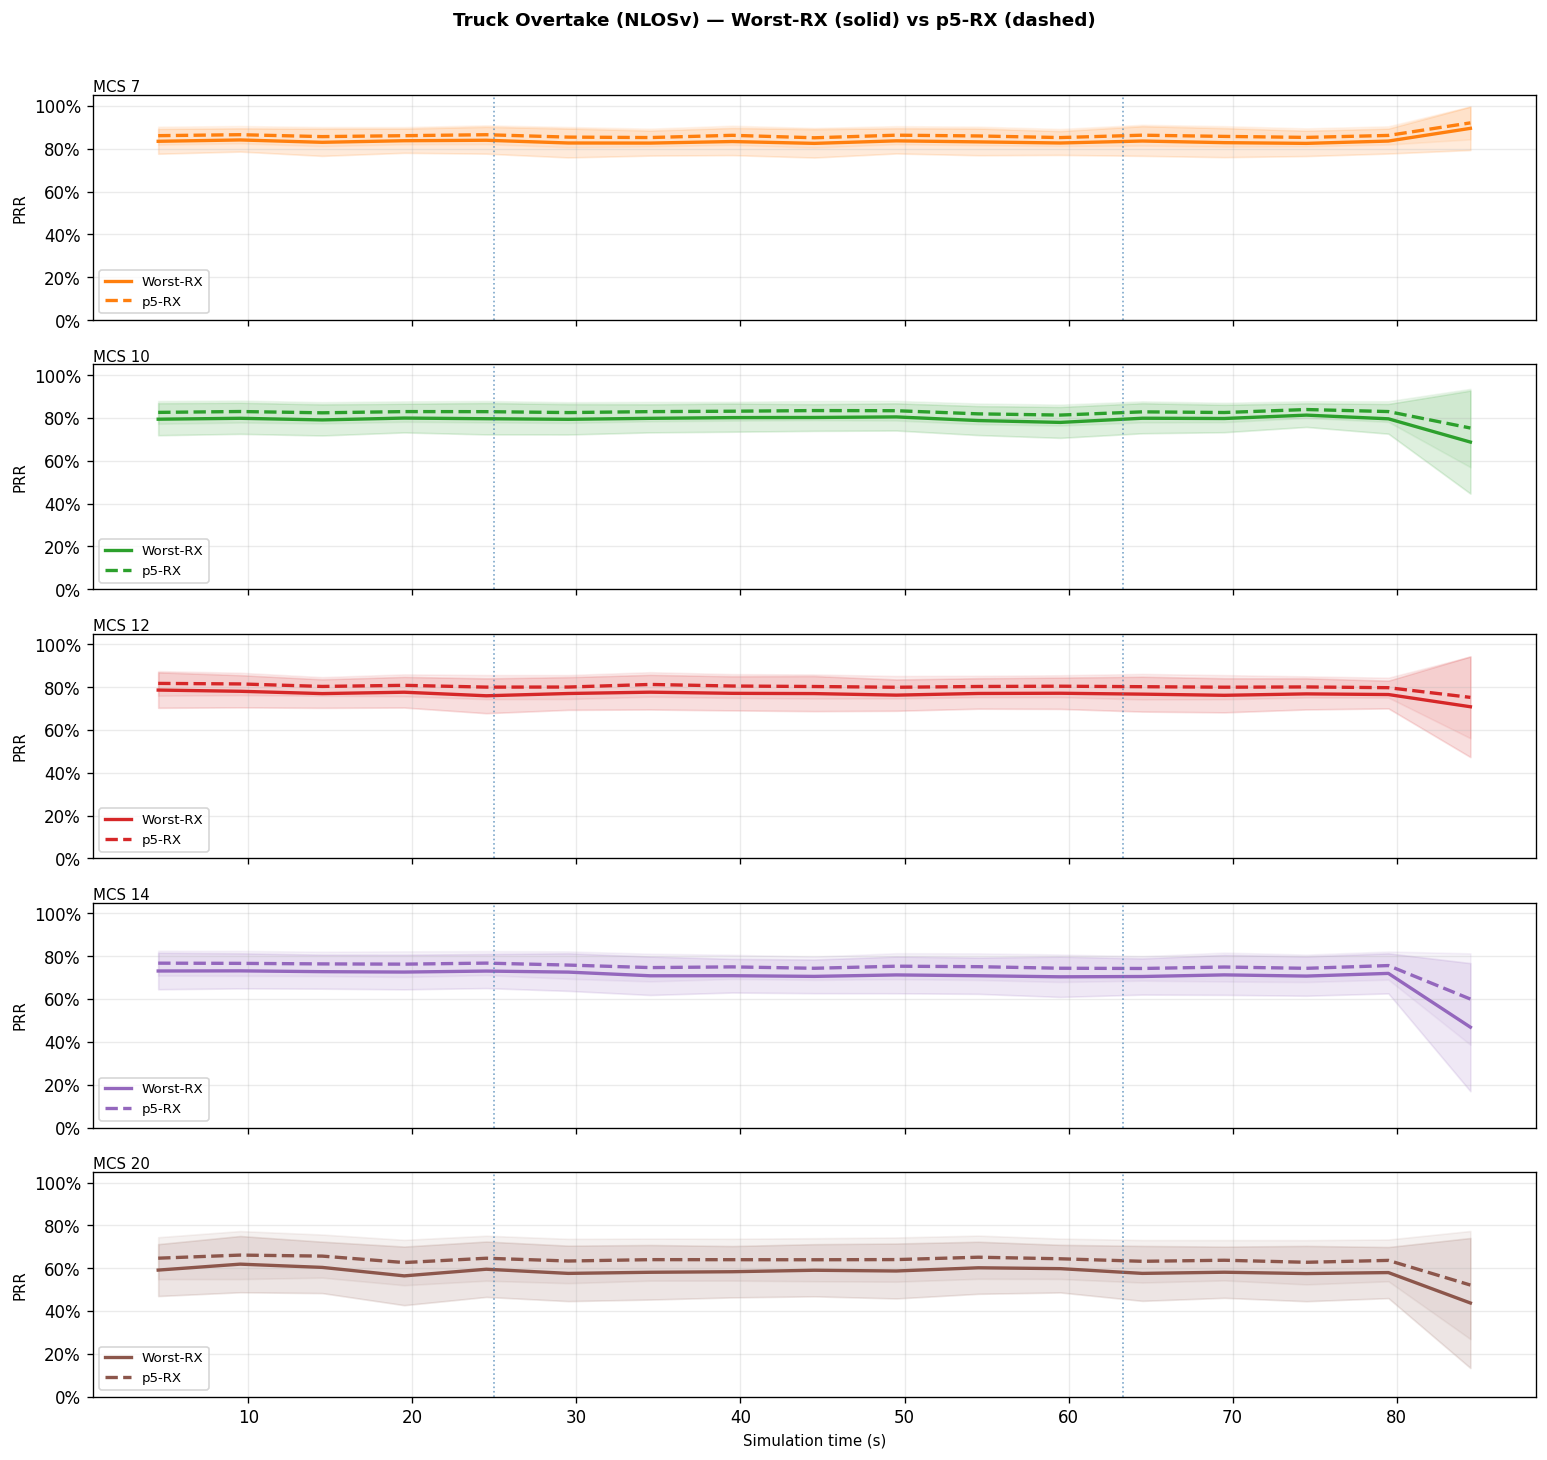

  saved → nb_worst_vs_p5_ccam_platoon_overtake.png


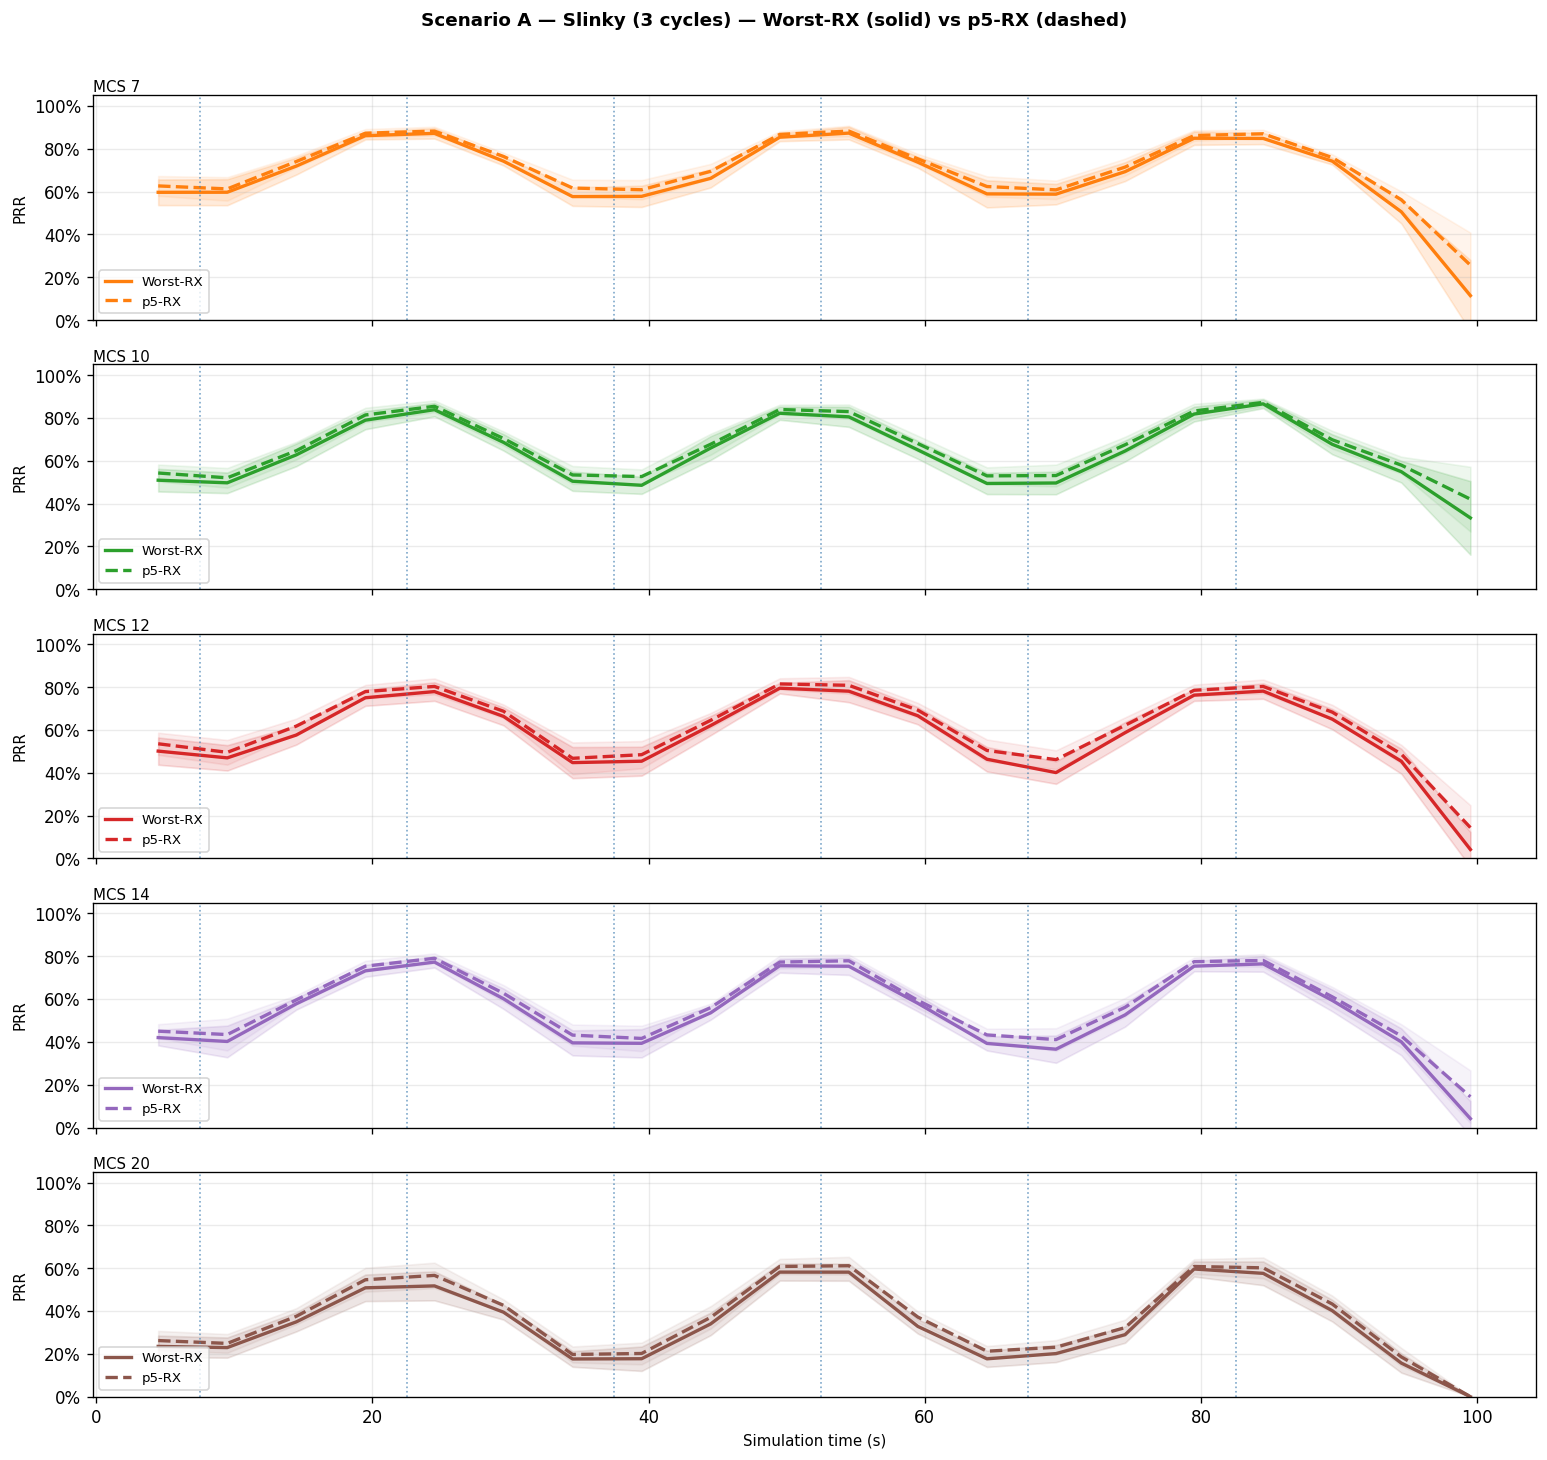

  saved → nb_worst_vs_p5_ccam_platoon_slinky.png


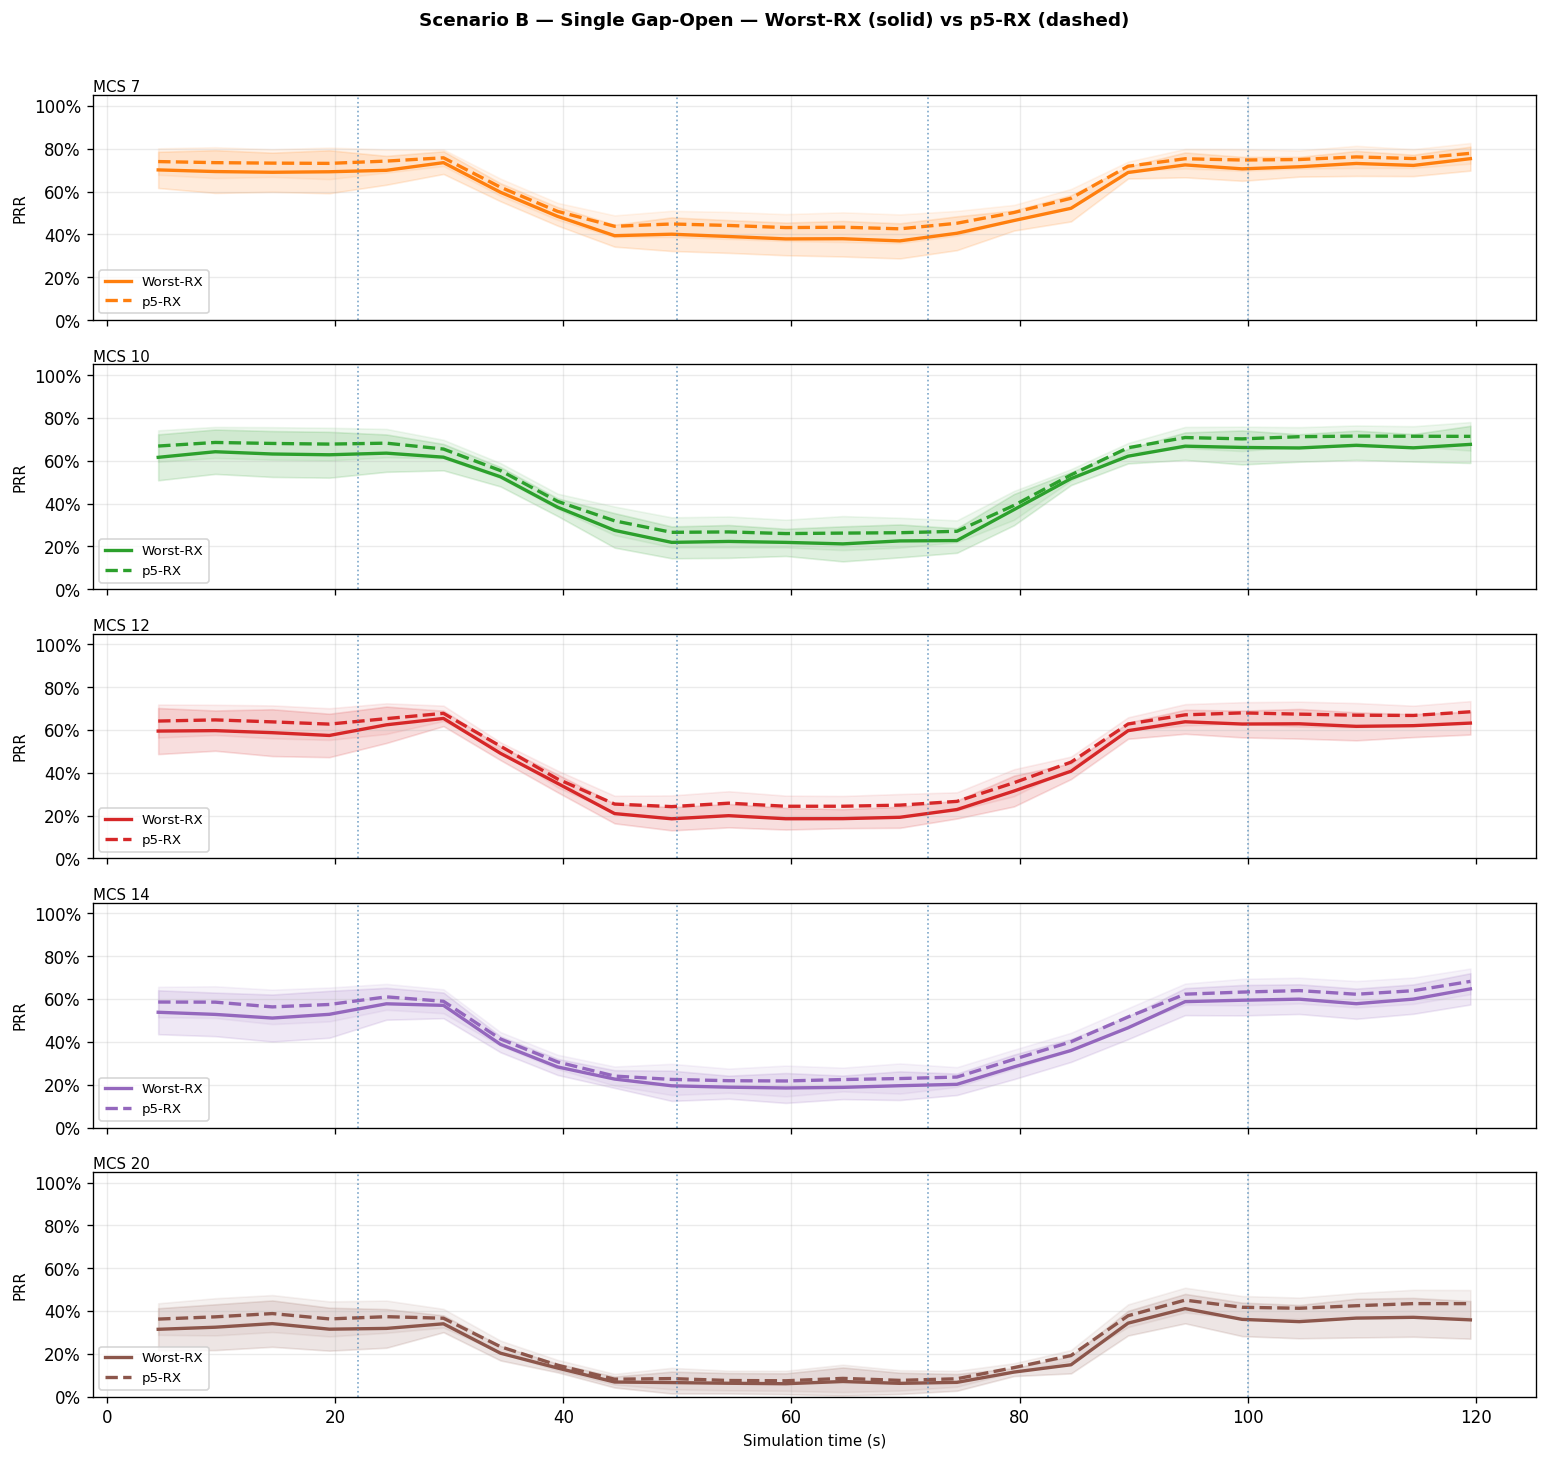

  saved → nb_worst_vs_p5_ccam_platoon_gap_open.png


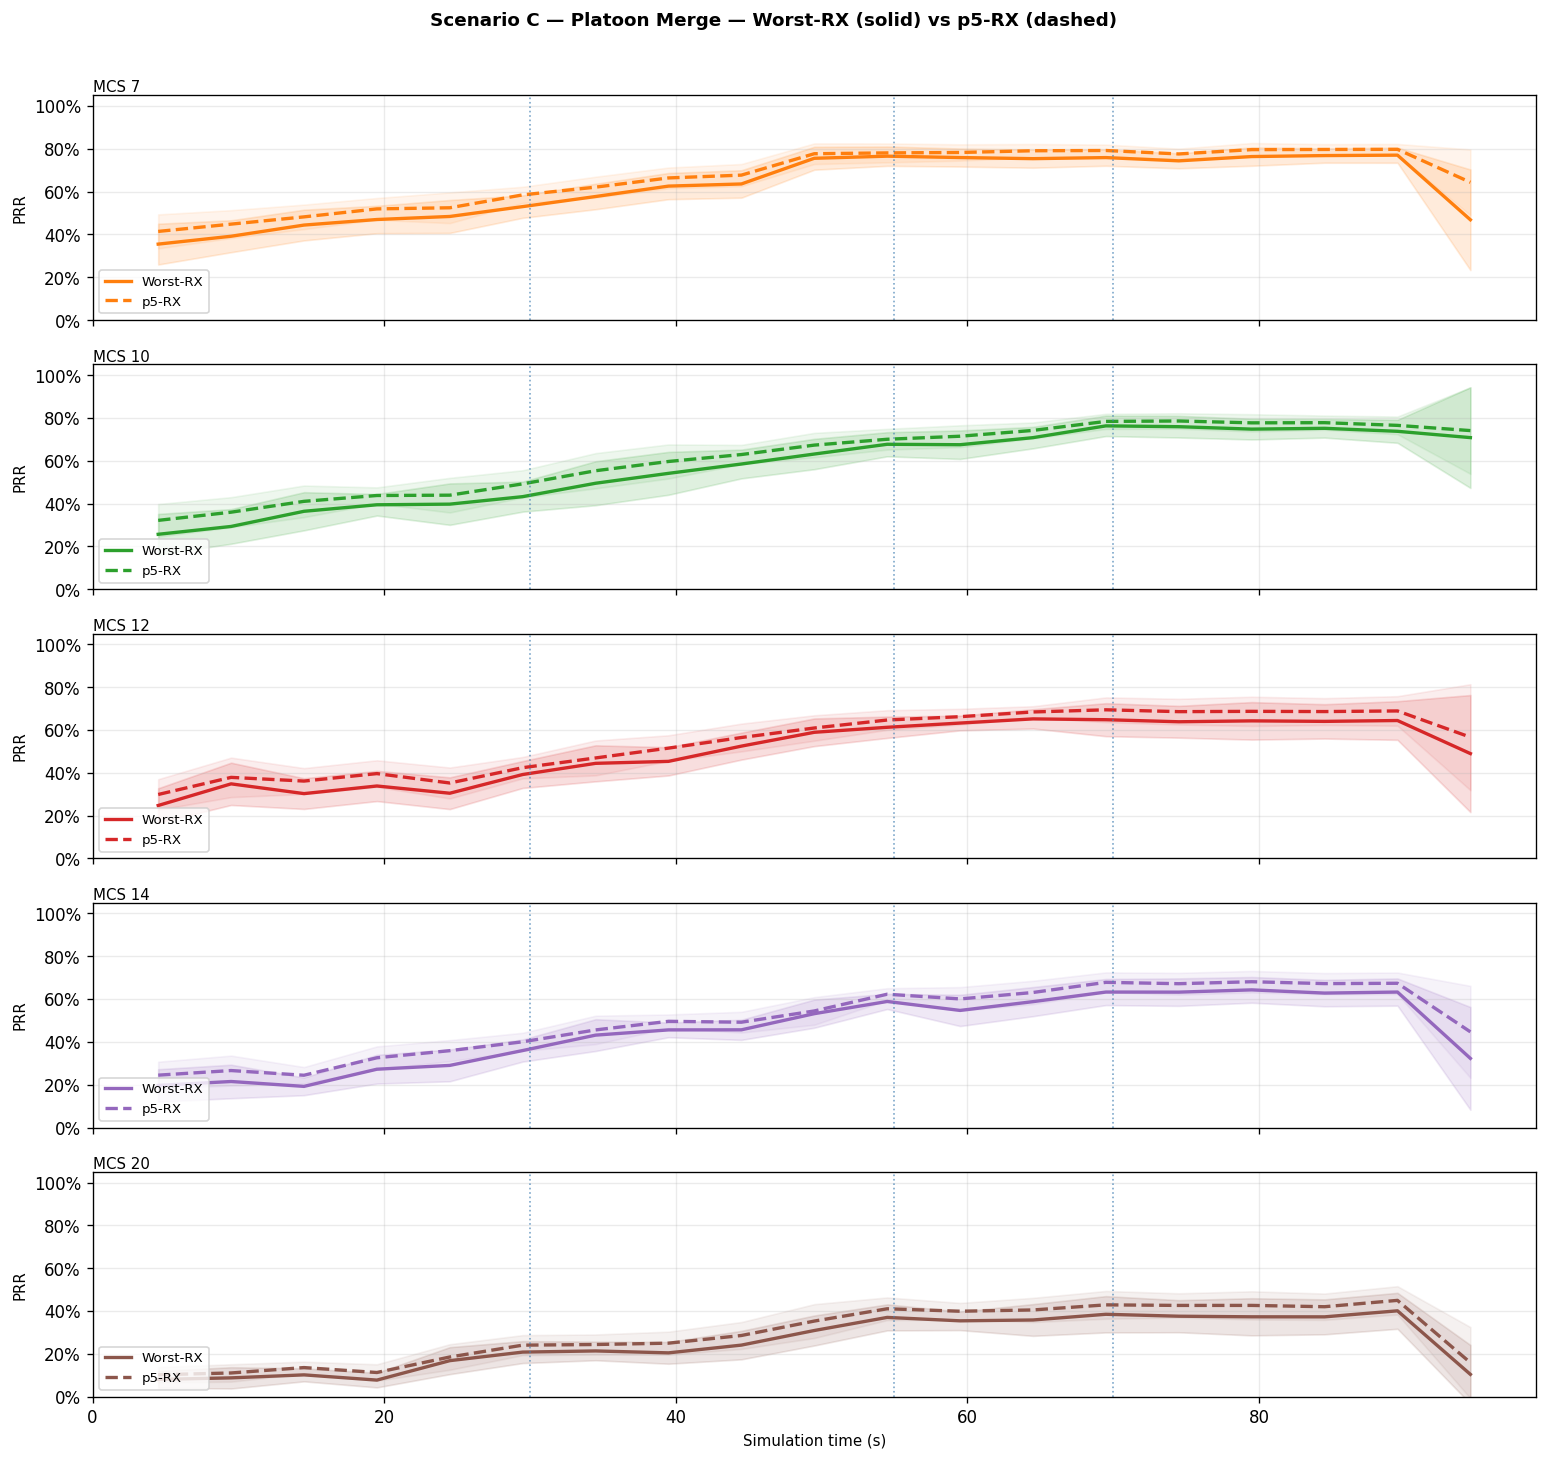

  saved → nb_worst_vs_p5_ccam_platoon_merge.png


In [ ]:
for scenario in RAW:
    ts_w   = TS[scenario]["worst"]
    ts_p5  = TS[scenario]["p5"]
    opt_w  = OPT[scenario]["worst"]
    opt_p5 = OPT[scenario]["p5"]
    mcs_vals = sorted(ts_w["mcs"].unique())

    fig, axes = plt.subplots(len(mcs_vals), 1,
                              figsize=(13, 2.4 * len(mcs_vals)),
                              sharex=True)
    if len(mcs_vals) == 1:
        axes = [axes]

    for ax, mcs in zip(axes, mcs_vals):
        sub_w  = ts_w [ts_w ["mcs"] == mcs].sort_values("win_start")
        sub_p5 = ts_p5[ts_p5["mcs"] == mcs].sort_values("win_start")

        ax.plot(sub_w["t_mid"],  sub_w["mean_prr"],
                color=MCS_COLORS[mcs], lw=2, label="Worst-RX")
        ax.fill_between(sub_w["t_mid"],
                         sub_w["mean_prr"] - sub_w["ci95"],
                         sub_w["mean_prr"] + sub_w["ci95"],
                         color=MCS_COLORS[mcs], alpha=0.15)

        ax.plot(sub_p5["t_mid"], sub_p5["mean_prr"],
                color=MCS_COLORS[mcs], lw=2, ls="--", label="p5-RX")
        ax.fill_between(sub_p5["t_mid"],
                         sub_p5["mean_prr"] - sub_p5["ci95"],
                         sub_p5["mean_prr"] + sub_p5["ci95"],
                         color=MCS_COLORS[mcs], alpha=0.08)

        ax.set_ylabel("PRR", fontsize=9)
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
        ax.set_ylim(0, 1.05)
        ax.set_title(f"MCS {mcs}", fontsize=9, loc="left", pad=2)
        ax.legend(fontsize=8, loc="lower left")
        ax.grid(True, alpha=0.25)

        for t_mark, _ in SCENARIO_PHASE_LINES.get(scenario, []):
            ax.axvline(t_mark, color="steelblue", ls=":", lw=1, alpha=0.7)

    axes[-1].set_xlabel("Simulation time (s)", fontsize=9)
    fig.suptitle(f"{SCENARIO_LABELS[scenario]} — Worst-RX (solid) vs p5-RX (dashed)",
                 fontsize=11, fontweight="bold", y=1.01)
    plt.tight_layout()
    out = PLOT_DIR / f"nb_worst_vs_p5_{scenario}.png"
    fig.savefig(out, dpi=130, bbox_inches="tight")
    plt.show()
    print(f"  saved → {out.name}")

---
## 8. Optimal-MCS Side-by-Side: Worst-RX vs p5-RX

Shows how the optimal MCS decision changes between the two receiver views.

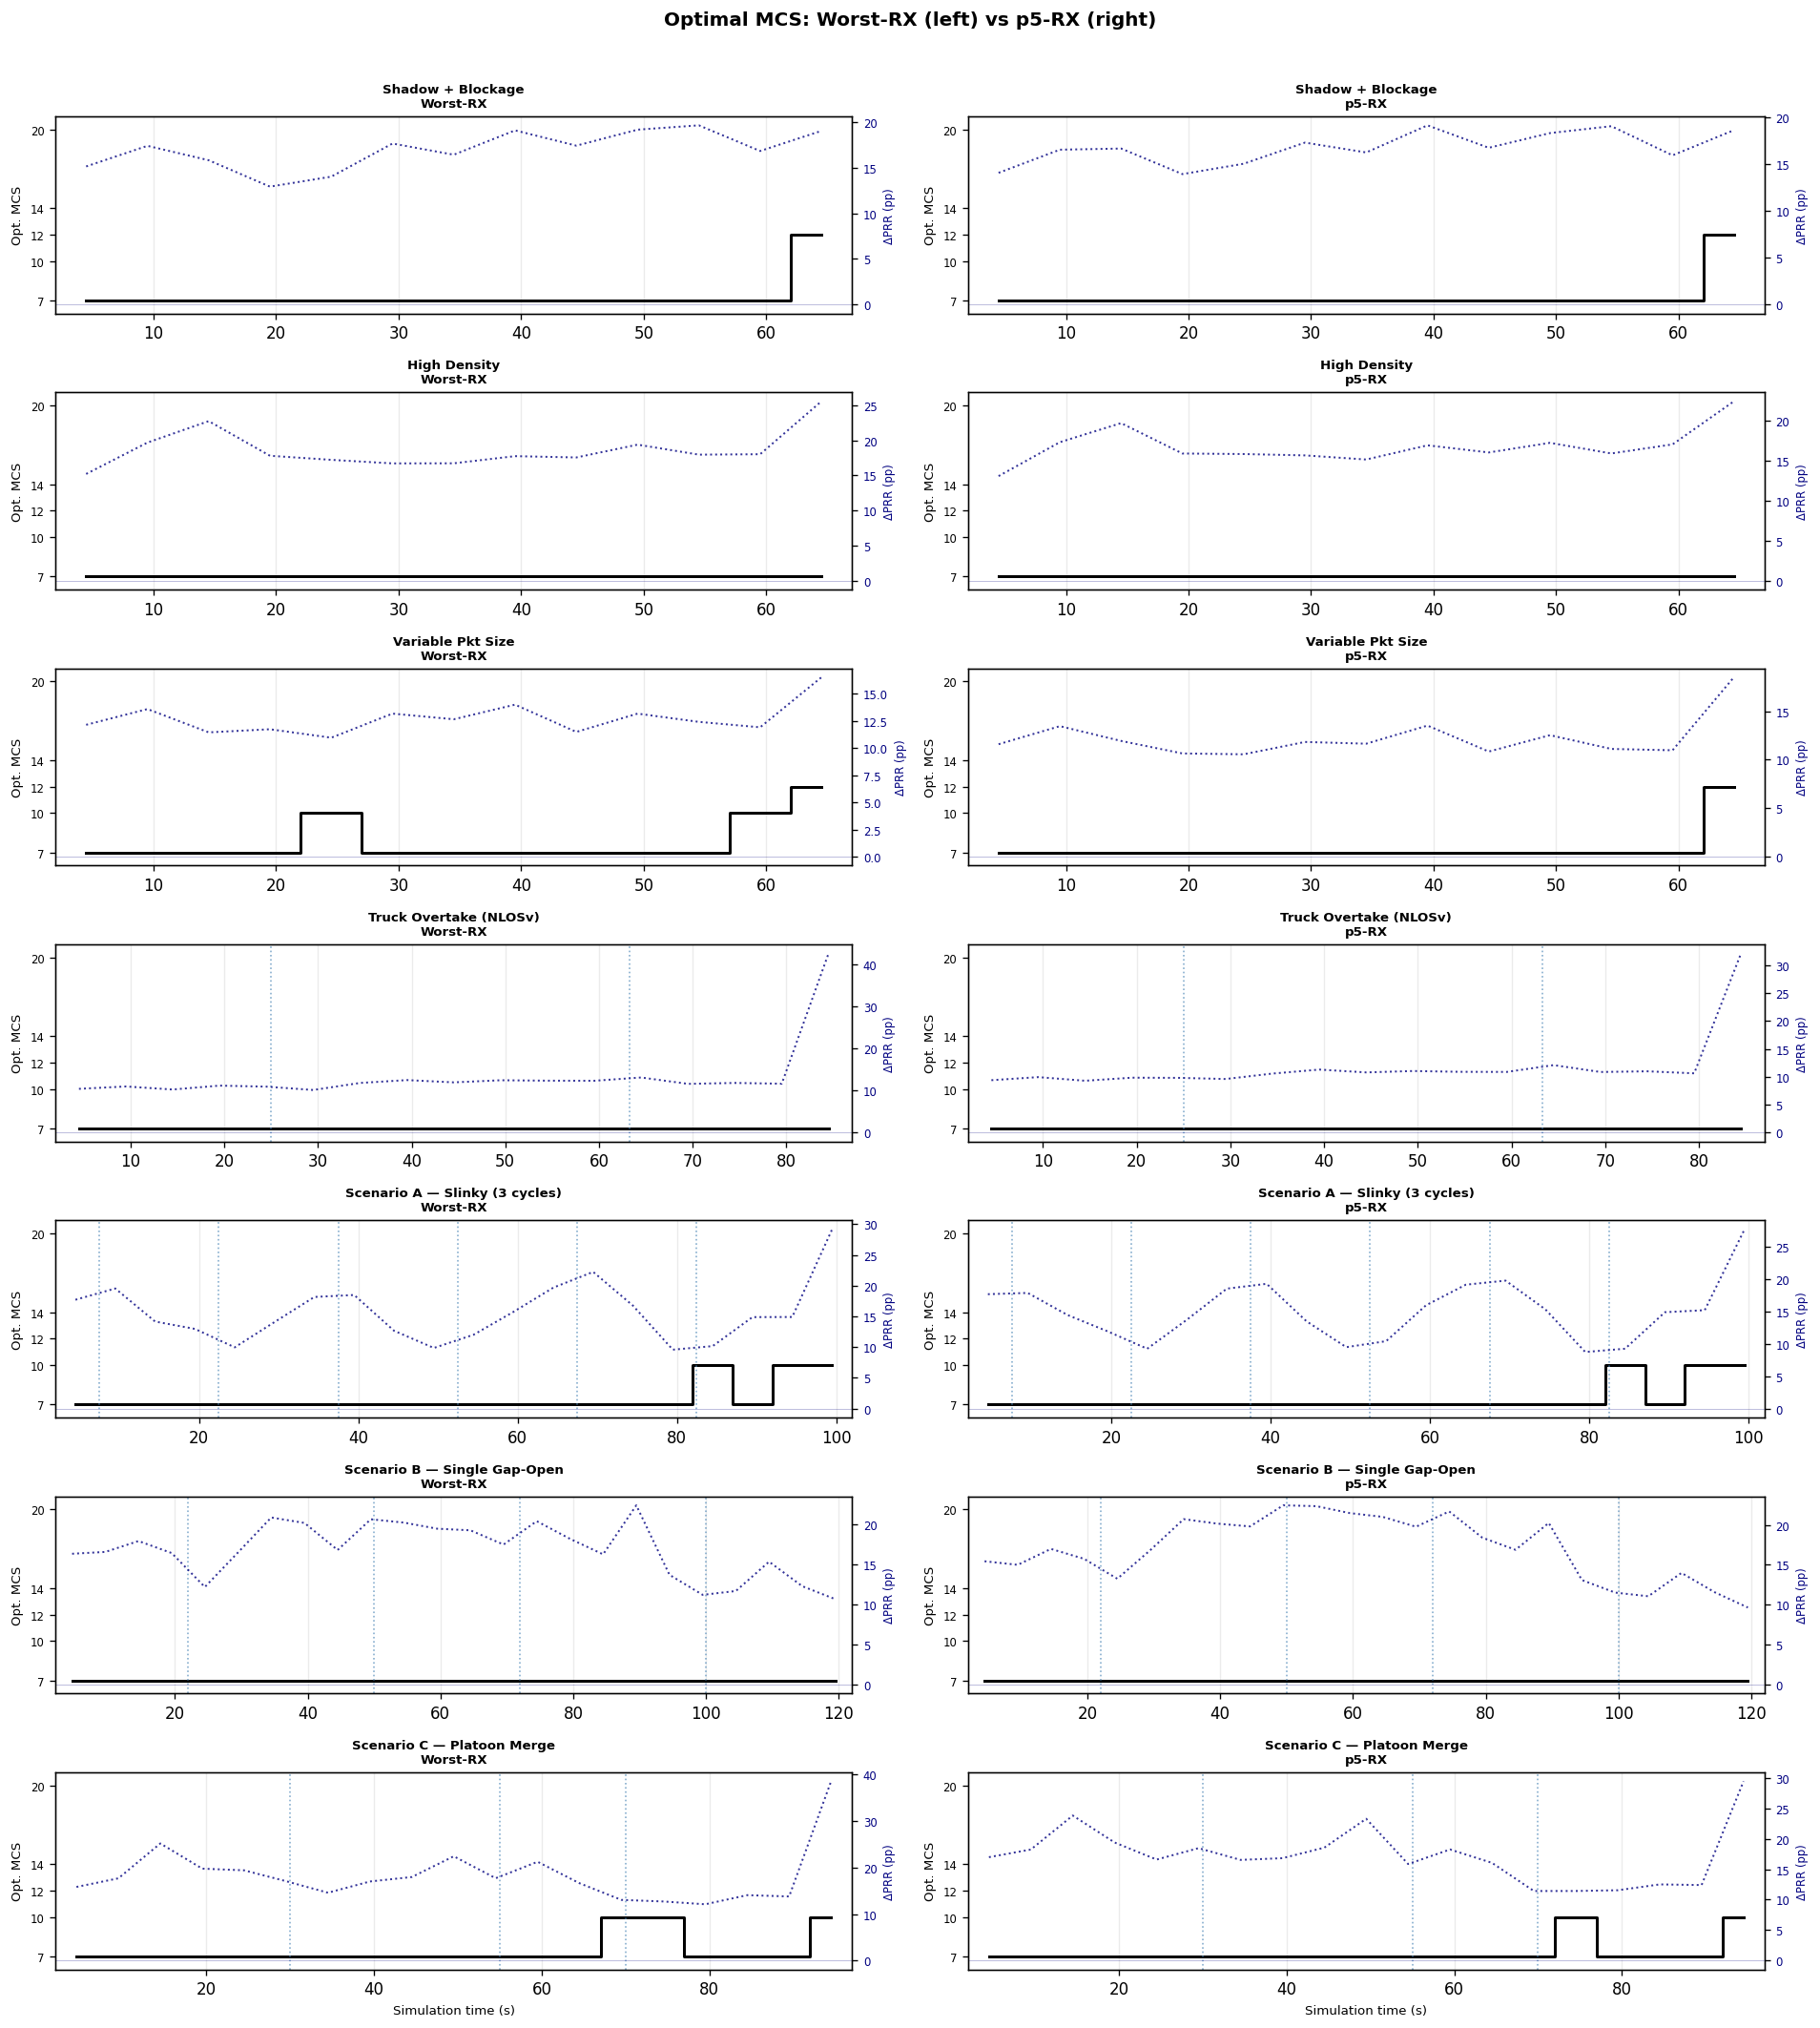

saved → nb_optimal_mcs_worst_vs_p5_all.png


In [ ]:
n_scen  = len(RAW)
fig, axes = plt.subplots(n_scen, 2, figsize=(16, 2.5 * n_scen), sharex=False)
if n_scen == 1:
    axes = [axes]

for row_idx, scenario in enumerate(RAW):
    for col_idx, mode in enumerate(("worst", "p5")):
        ts  = TS[scenario][mode]
        opt = OPT[scenario][mode]
        ax  = axes[row_idx][col_idx]
        mcs_vals = sorted(ts["mcs"].unique())
        t_min = ts["win_start"].min()
        t_max = ts["win_start"].max() + WINDOW_SEC

        for _, r in opt.iterrows():
            ax.fill_between([r["win_start"], r["win_start"] + WINDOW_SEC],
                             [0,0],[1,1],
                             color=MCS_COLORS.get(r["optimal_mcs"],"grey"), alpha=0.30)
        ax.step(opt["t_mid"], opt["optimal_mcs"], where="mid",
                color="black", lw=1.8)
        # ΔPRR twin
        ax2 = ax.twinx()
        ax2.plot(opt["t_mid"], opt["delta_prr_pp"],
                 color="navy", ls=":", lw=1.2, alpha=0.8)
        ax2.axhline(0, color="navy", lw=0.5, alpha=0.3)
        ax2.set_ylabel("ΔPRR (pp)", fontsize=7, color="navy")
        ax2.tick_params(axis="y", labelcolor="navy", labelsize=7)

        ax.set_yticks(mcs_vals)
        ax.set_yticklabels([str(m) for m in mcs_vals], fontsize=7)
        ax.set_ylim(min(mcs_vals)-1, max(mcs_vals)+1)
        ax.set_xlim(t_min, t_max)
        ax.grid(axis="x", alpha=0.25)
        mode_lbl = "Worst-RX" if mode=="worst" else "p5-RX"
        ax.set_title(f"{SCENARIO_LABELS[scenario]}\n{mode_lbl}", fontsize=8, fontweight="bold")
        ax.set_ylabel("Opt. MCS", fontsize=8)
        if row_idx == n_scen - 1:
            ax.set_xlabel("Simulation time (s)", fontsize=8)

        for t_mark, _ in SCENARIO_PHASE_LINES.get(scenario, []):
            ax.axvline(t_mark, color="steelblue", ls=":", lw=1, alpha=0.65)

plt.suptitle("Optimal MCS: Worst-RX (left) vs p5-RX (right)",
             fontsize=12, fontweight="bold", y=1.01)
plt.tight_layout()
out = PLOT_DIR / "nb_optimal_mcs_worst_vs_p5_all.png"
fig.savefig(out, dpi=130, bbox_inches="tight")
plt.show()
print(f"saved → {out.name}")

---
## 9. Gain Summary Tables

Mean gain of optimal (adaptive) MCS over fixed MCS=14, aggregated over all time windows.

In [ ]:
def build_summary(mode):
    rows = []
    for scenario in RAW:
        opt = OPT[scenario][mode]
        rows.append(dict(
            scenario              = SCENARIO_LABELS[scenario],
            n_windows             = len(opt),
            n_seeds               = int(RAW[scenario]["seed"].nunique()),
            mean_best_prr         = round(opt["best_prr"].mean(), 3),
            mean_prr_mcs14        = round(opt["prr14"].mean(), 3),
            mean_delta_prr_pp     = round(opt["delta_prr_pp"].mean(), 2),
            mean_delta_pir_ms     = round(opt["delta_pir_ms"].mean(), 1),
            mean_delta_tput_kbps  = round(opt["delta_tput_kbps"].mean(), 2),
            pct_windows_opt_beats = f"{(opt['delta_prr_pp'] > 0).mean():.0%}",
        ))
    return pd.DataFrame(rows)

sum_w  = build_summary("worst")
sum_p5 = build_summary("p5")

print("=" * 70)
print("WORST-RX — gain of optimal MCS vs fixed MCS=14")
print("=" * 70)
display(sum_w.set_index("scenario").rename(columns={
    "mean_delta_prr_pp":"ΔPRR(pp)",
    "mean_delta_pir_ms":"ΔPIR(ms)",
    "mean_delta_tput_kbps":"Δtput(kb)",
    "mean_best_prr":"best PRR",
    "mean_prr_mcs14":"PRR MCS14",
    "pct_windows_opt_beats":"wins>MCS14",
}))

print()
print("=" * 70)
print("p5-RX — gain of optimal MCS vs fixed MCS=14")
print("=" * 70)
display(sum_p5.set_index("scenario").rename(columns={
    "mean_delta_prr_pp":"ΔPRR(pp)",
    "mean_delta_pir_ms":"ΔPIR(ms)",
    "mean_delta_tput_kbps":"Δtput(kb)",
    "mean_best_prr":"best PRR",
    "mean_prr_mcs14":"PRR MCS14",
    "pct_windows_opt_beats":"wins>MCS14",
}))

# Save CSVs
sum_w .to_csv(TIDY_DIR / "nb_summary_worst_rx.csv",  index=False)
sum_p5.to_csv(TIDY_DIR / "nb_summary_p5_rx.csv",     index=False)
print("\nCSVs saved to tidy/.")

WORST-RX — gain of optimal MCS vs fixed MCS=14


,n_windows,n_seeds,best PRR,PRR MCS14,ΔPRR(pp),ΔPIR(ms),Δtput(kb),wins>MCS14
scenario,,,,,,,,
Shadow + Blockage,13,30,0.643,0.473,16.97,104.2,108.50,100%
High Density,13,30,0.799,0.613,18.63,122.2,117.24,100%
Variable Pkt Size,13,30,0.754,0.627,12.71,21.8,79.03,100%
Truck Overtake (NLOSv),17,10,0.837,0.702,13.43,117.9,76.71,100%
Scenario A — Slinky (3 cycles),20,10,0.694,0.538,15.63,51.8,99.62,100%
Scenario B — Single Gap-Open,24,10,0.586,0.418,16.79,64.2,115.23,100%
Scenario C — Platoon Merge,19,10,0.636,0.454,18.24,117.9,113.68,100%



p5-RX — gain of optimal MCS vs fixed MCS=14


,n_windows,n_seeds,best PRR,PRR MCS14,ΔPRR(pp),ΔPIR(ms),Δtput(kb),wins>MCS14
scenario,,,,,,,,
Shadow + Blockage,13,30,0.691,0.524,16.75,94.7,107.39,100%
High Density,13,30,0.823,0.655,16.81,99.2,105.91,100%
Variable Pkt Size,13,30,0.793,0.671,12.25,21.5,74.00,100%
Truck Overtake (NLOSv),17,10,0.863,0.745,11.76,96.0,69.39,100%
Scenario A — Slinky (3 cycles),20,10,0.718,0.567,15.11,58.1,96.47,100%
Scenario B — Single Gap-Open,24,10,0.624,0.454,17.04,51.3,117.40,100%
Scenario C — Platoon Merge,19,10,0.673,0.500,17.23,72.3,109.94,100%



CSVs saved to tidy/.


---
## 10. Cross-Scenario Gain Bar Charts (Worst-RX vs p5-RX)

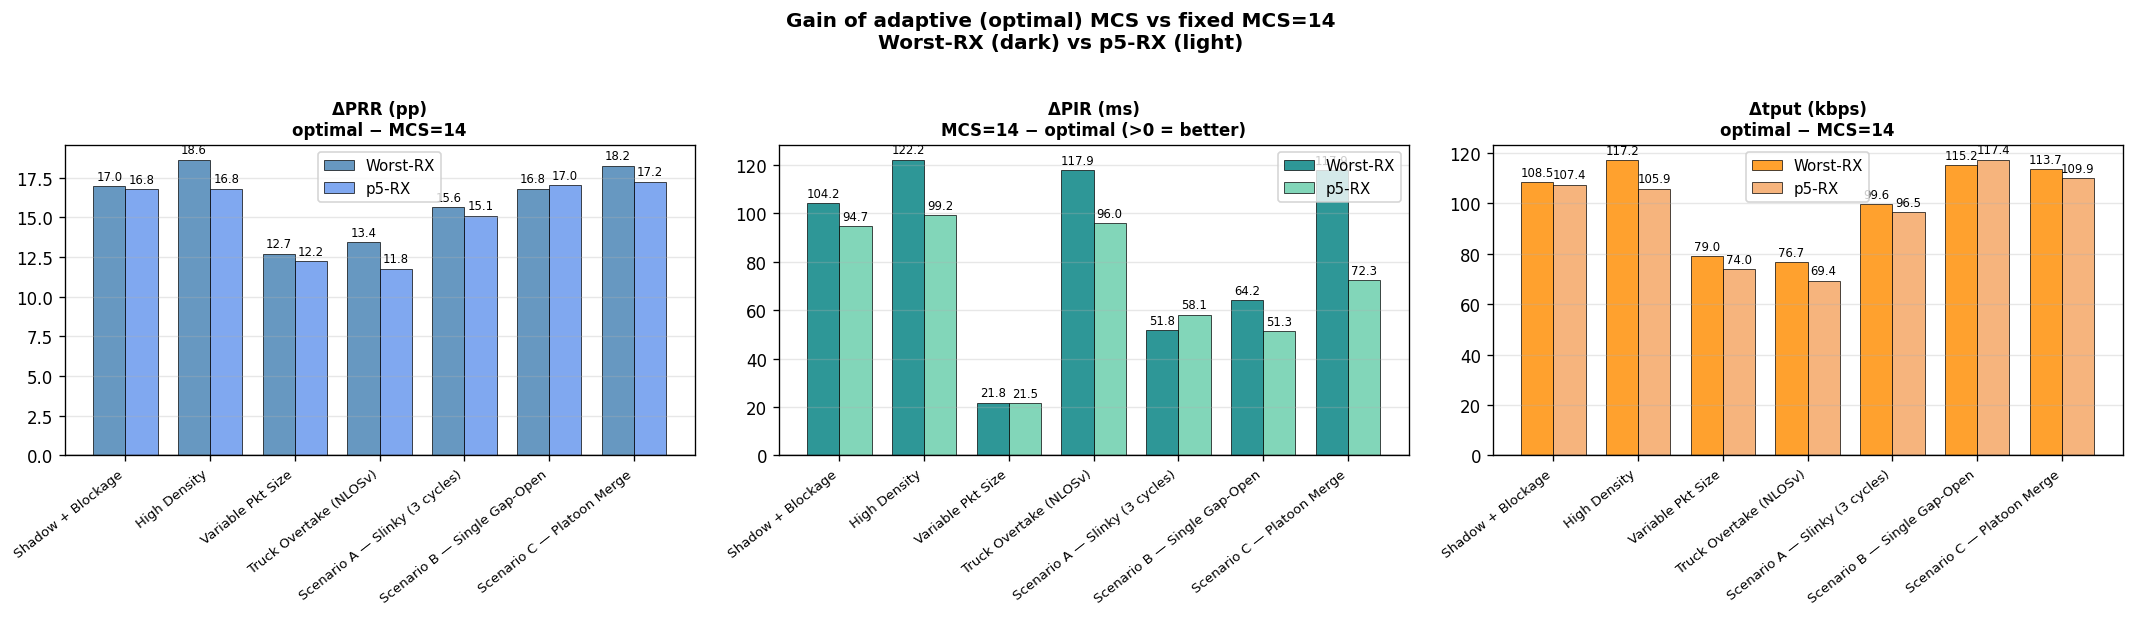

saved → nb_gain_worst_vs_p5_comparison.png


In [ ]:
metrics = [
    ("mean_delta_prr_pp",    "ΔPRR (pp)\noptimal − MCS=14",          ["steelblue","cornflowerblue"]),
    ("mean_delta_pir_ms",    "ΔPIR (ms)\nMCS=14 − optimal (>0 = better)", ["teal","mediumaquamarine"]),
    ("mean_delta_tput_kbps", "Δtput (kbps)\noptimal − MCS=14",        ["darkorange","sandybrown"]),
]

x       = np.arange(len(RAW))
labels  = [SCENARIO_LABELS[s] for s in RAW]
width   = 0.38

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (col, title, colors) in zip(axes, metrics):
    vals_w  = sum_w [col].values
    vals_p5 = sum_p5[col].values

    b1 = ax.bar(x - width/2, vals_w,  width, color=colors[0], alpha=0.82,
                edgecolor="black", lw=0.5, label="Worst-RX")
    b2 = ax.bar(x + width/2, vals_p5, width, color=colors[1], alpha=0.82,
                edgecolor="black", lw=0.5, label="p5-RX")
    ax.bar_label(b1, fmt="%.1f", fontsize=7, padding=2)
    ax.bar_label(b2, fmt="%.1f", fontsize=7, padding=2)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=38, ha="right", fontsize=8)
    ax.legend(fontsize=9)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Gain of adaptive (optimal) MCS vs fixed MCS=14\n"
             "Worst-RX (dark) vs p5-RX (light)",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
out = PLOT_DIR / "nb_gain_worst_vs_p5_comparison.png"
fig.savefig(out, dpi=130, bbox_inches="tight")
plt.show()
print(f"saved → {out.name}")

---
## 11. Worst-RX vs p5-RX Absolute PRR per Scenario

Scatter/line plot showing how much 'easier' the p5 metric is compared to worst-RX
(positive gap = p5-RX PRR > worst-RX PRR).

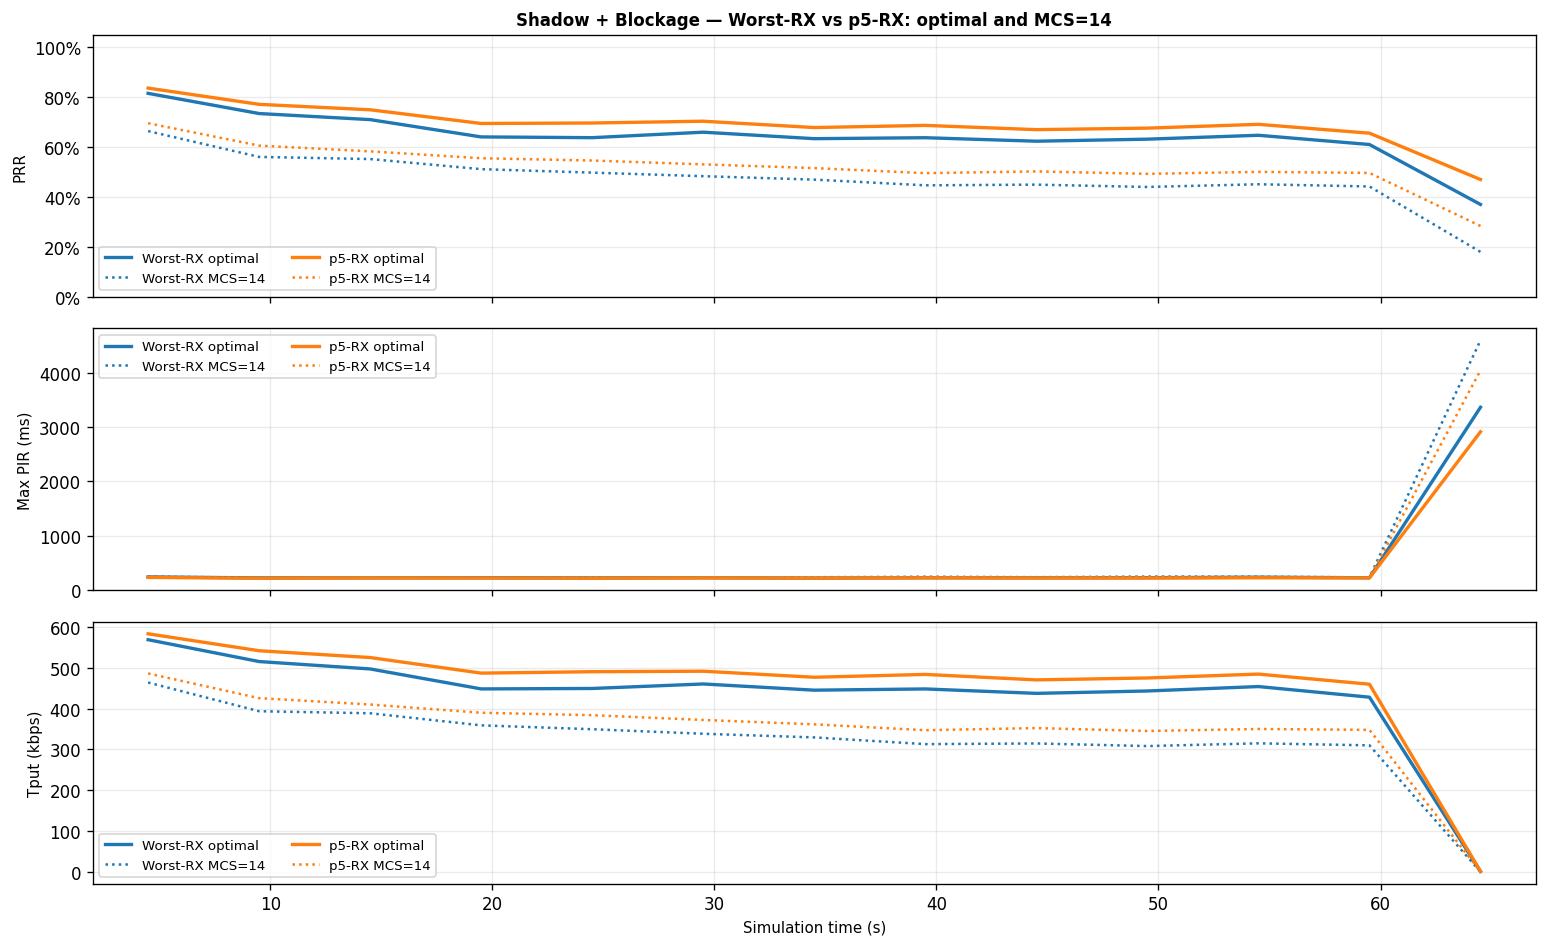

  saved → nb_abs_worst_vs_p5_shadowing_blockage.png


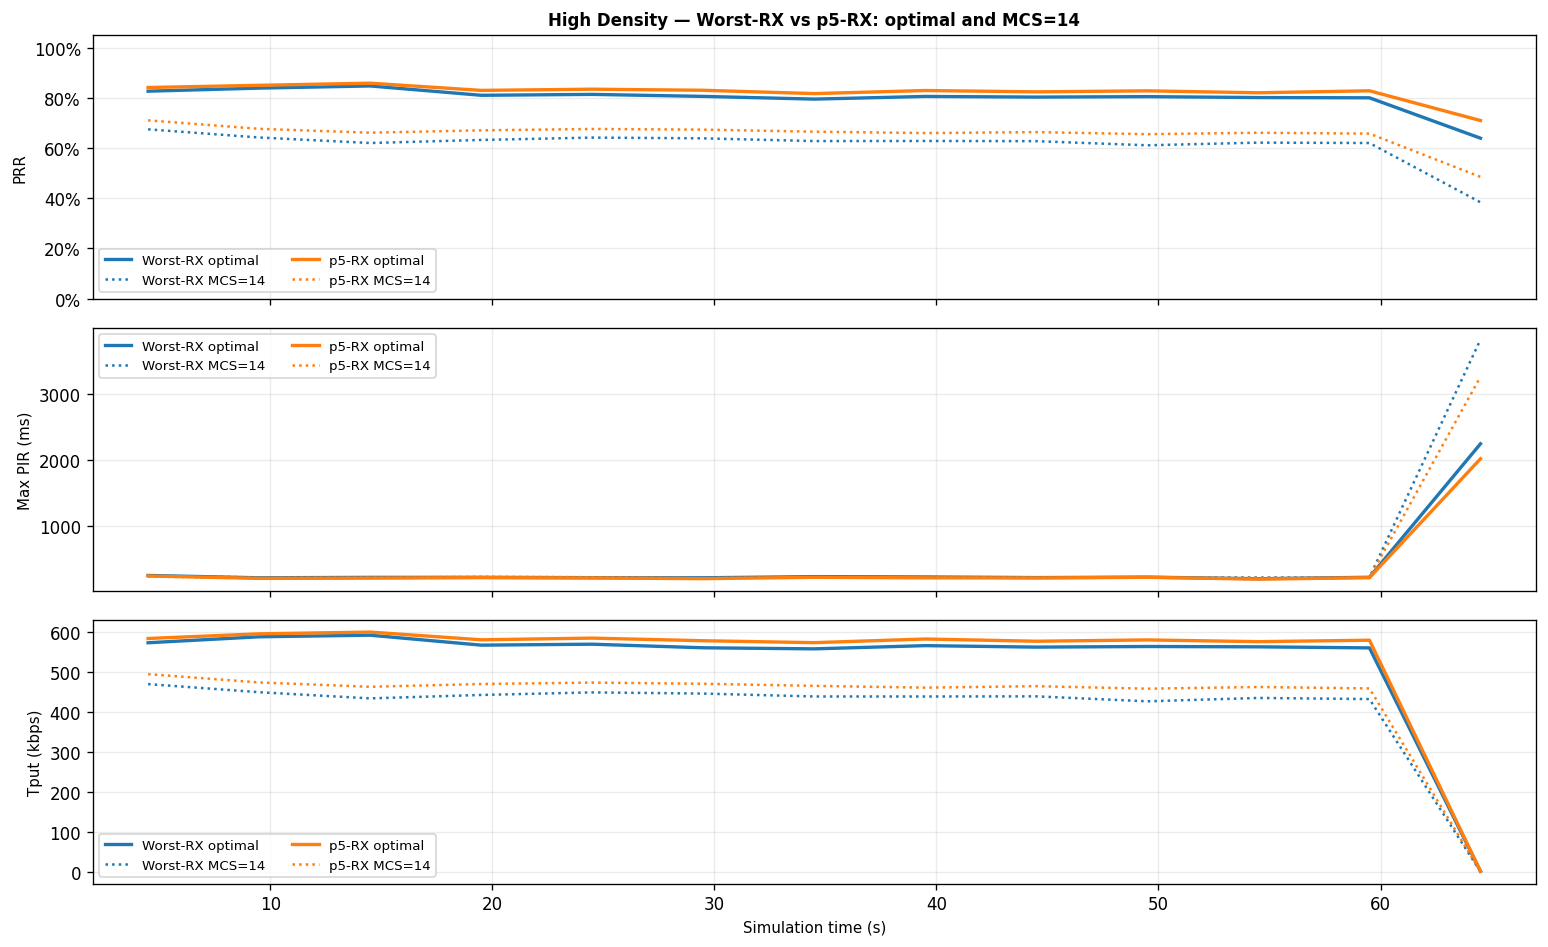

  saved → nb_abs_worst_vs_p5_high_density.png


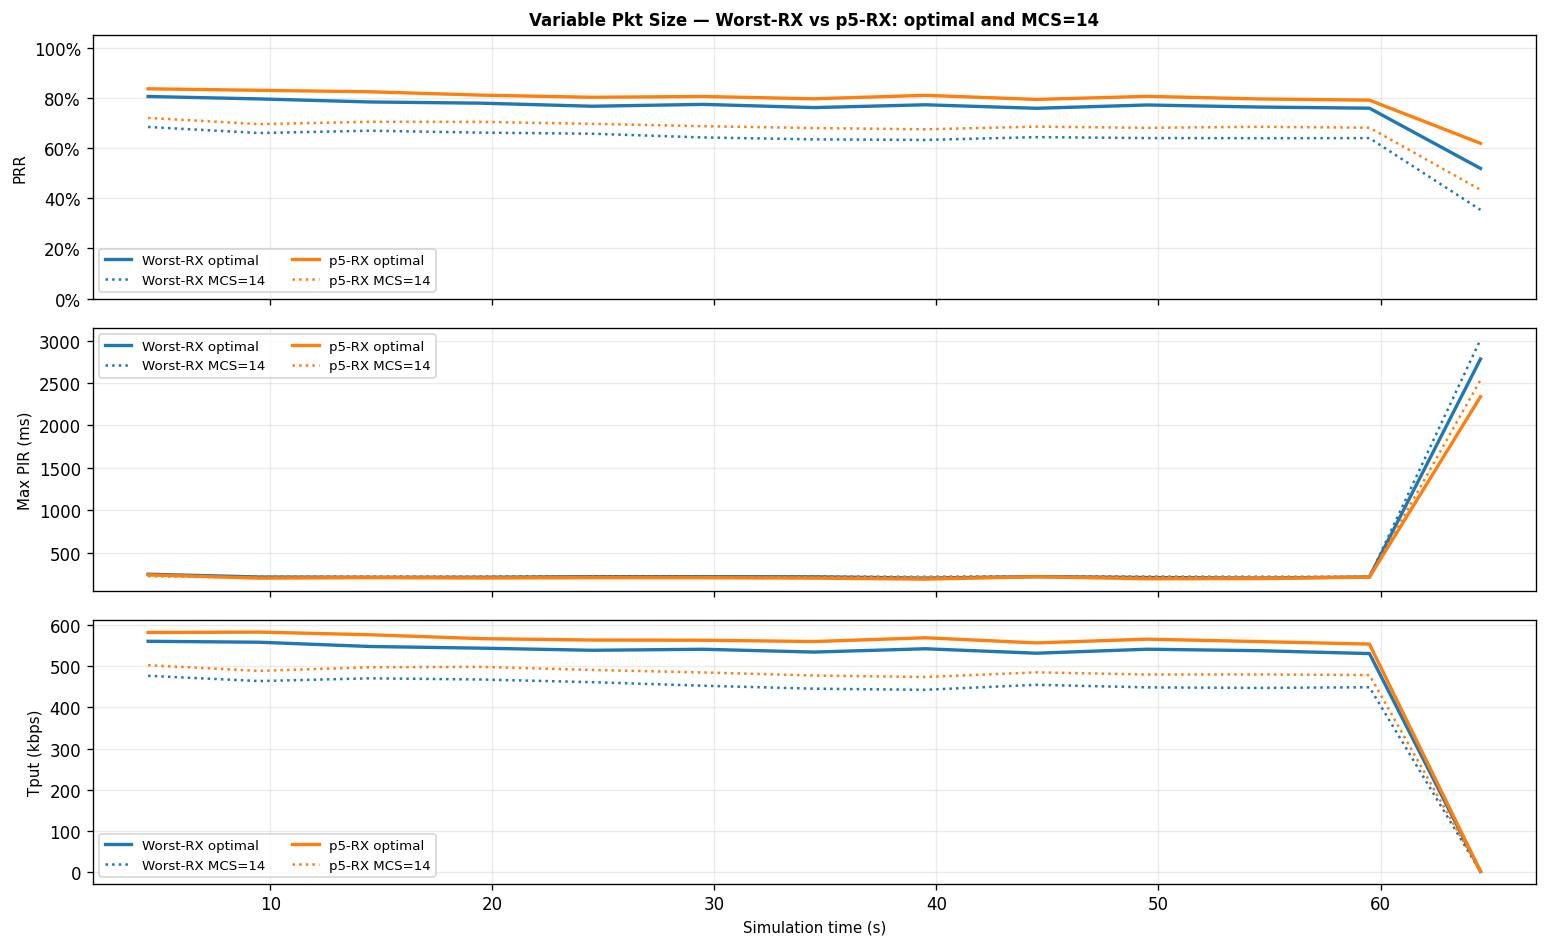

  saved → nb_abs_worst_vs_p5_variable_packet_size.png


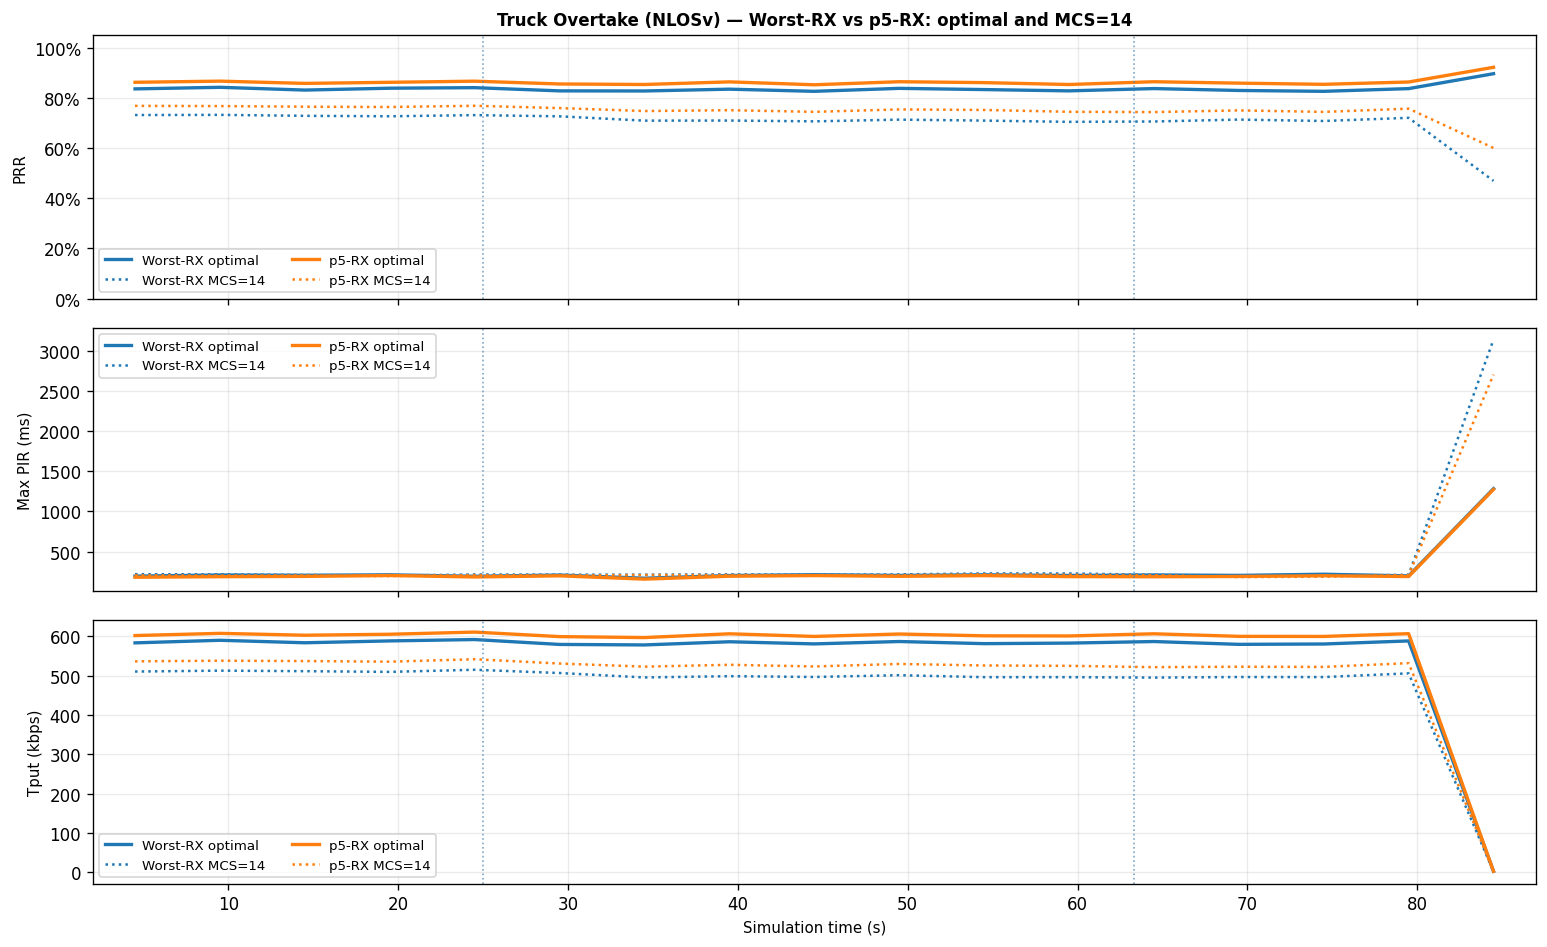

  saved → nb_abs_worst_vs_p5_ccam_platoon_overtake.png


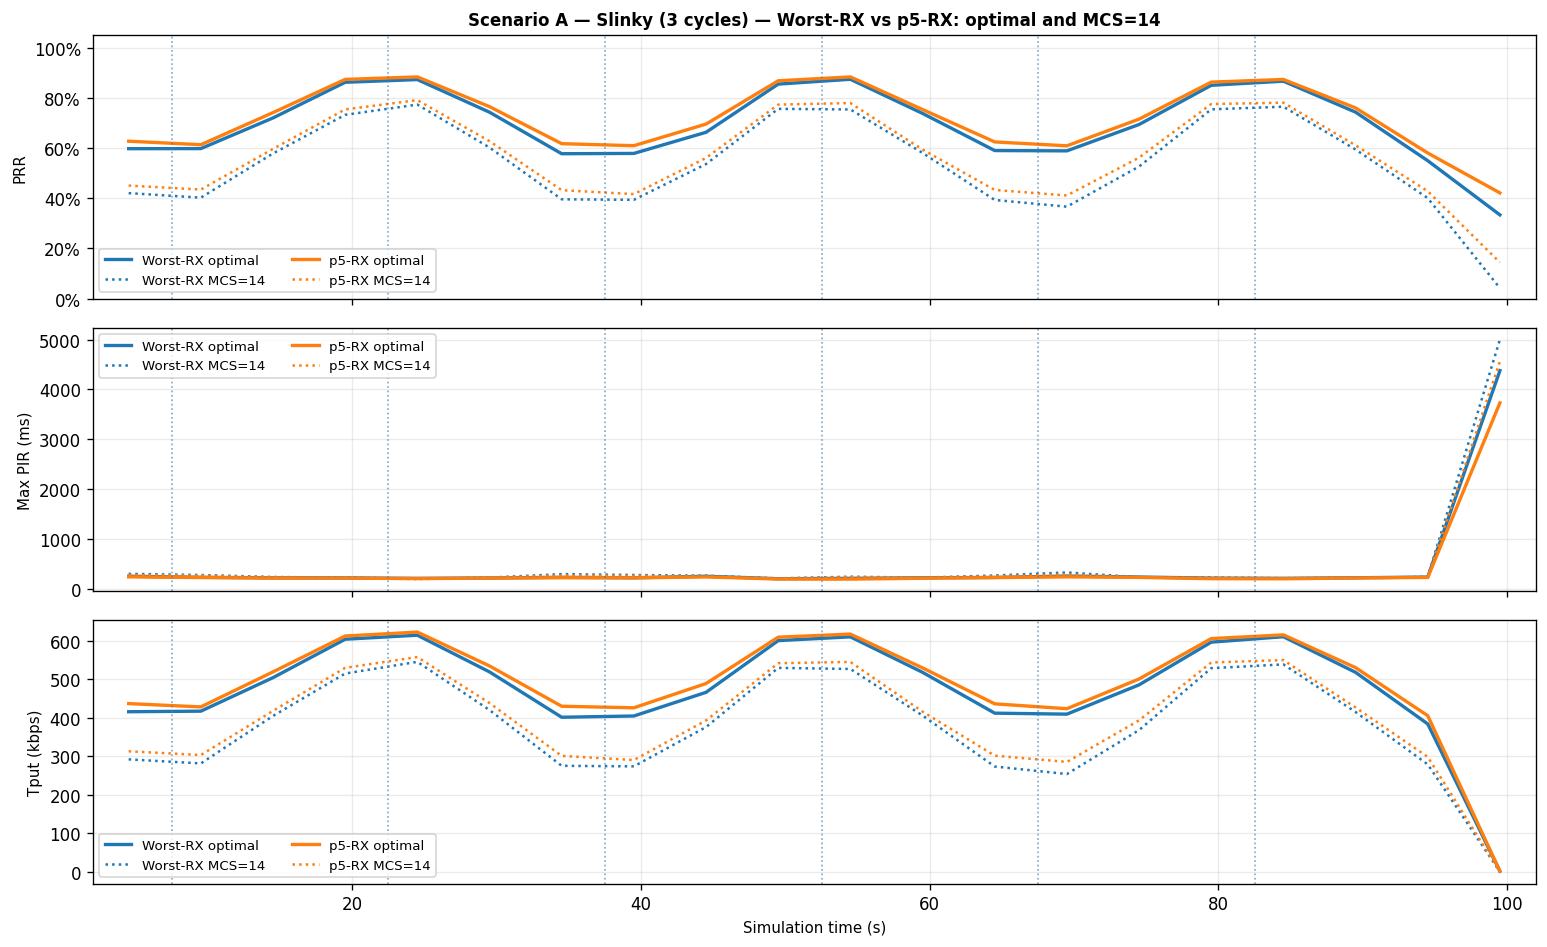

  saved → nb_abs_worst_vs_p5_ccam_platoon_slinky.png


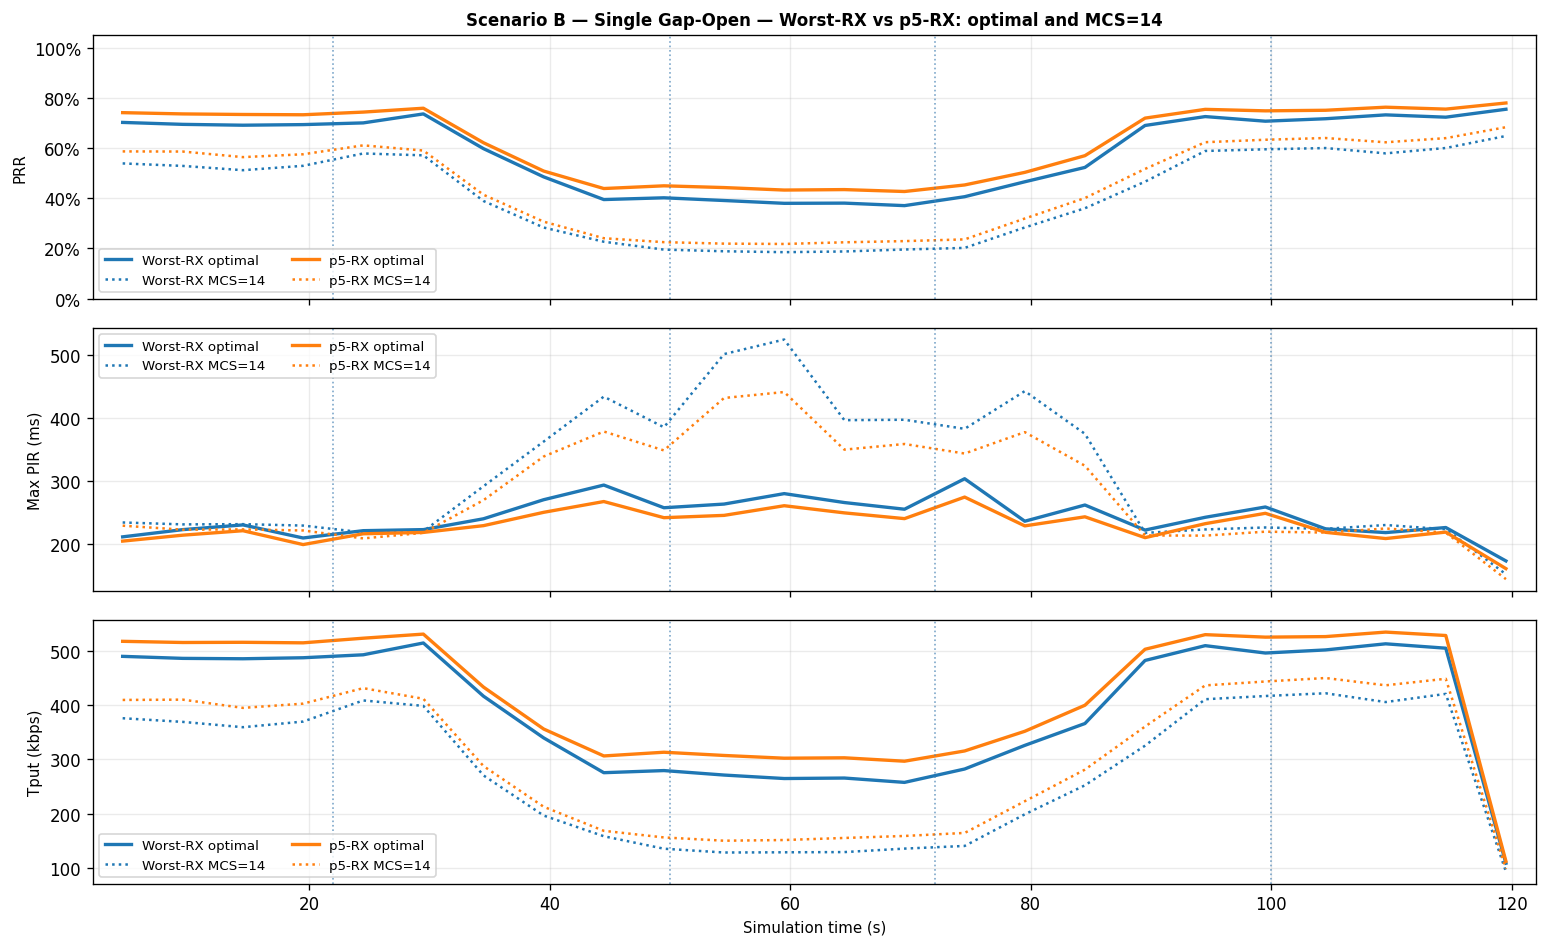

  saved → nb_abs_worst_vs_p5_ccam_platoon_gap_open.png


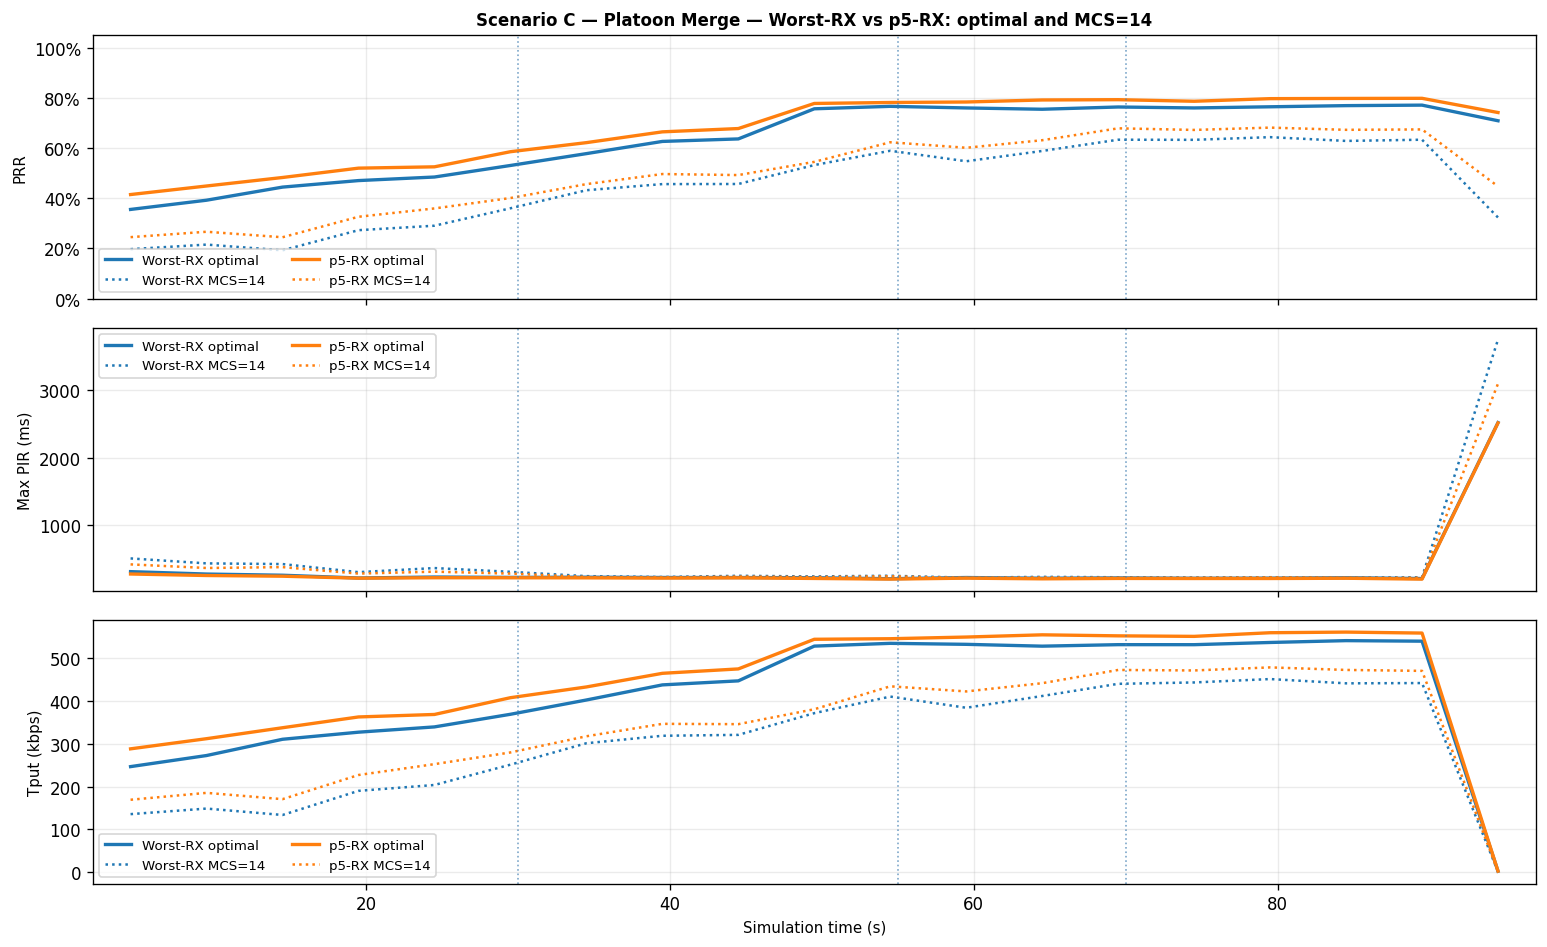

  saved → nb_abs_worst_vs_p5_ccam_platoon_merge.png


In [ ]:
for scenario in RAW:
    opt_w  = OPT[scenario]["worst"]
    opt_p5 = OPT[scenario]["p5"]

    fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
    ax_prr, ax_pir, ax_tput = axes

    # PRR
    ax_prr.plot(opt_w["t_mid"],  opt_w["best_prr"],  color="#1f77b4", lw=2,   label="Worst-RX optimal")
    ax_prr.plot(opt_w["t_mid"],  opt_w["prr14"],     color="#1f77b4", lw=1.5, ls=":", label="Worst-RX MCS=14")
    ax_prr.plot(opt_p5["t_mid"], opt_p5["best_prr"], color="#ff7f0e", lw=2,   label="p5-RX optimal")
    ax_prr.plot(opt_p5["t_mid"], opt_p5["prr14"],    color="#ff7f0e", lw=1.5, ls=":", label="p5-RX MCS=14")
    ax_prr.set_ylabel("PRR", fontsize=9)
    ax_prr.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
    ax_prr.set_ylim(0, 1.05)
    ax_prr.legend(fontsize=8, ncol=2, loc="lower left")
    ax_prr.grid(True, alpha=0.25)
    ax_prr.set_title(f"{SCENARIO_LABELS[scenario]} — Worst-RX vs p5-RX: optimal and MCS=14",
                     fontsize=10, fontweight="bold")

    # PIR
    ax_pir.plot(opt_w["t_mid"],  opt_w["best_pir"],  color="#1f77b4", lw=2,   label="Worst-RX optimal")
    ax_pir.plot(opt_w["t_mid"],  opt_w["pir14"],     color="#1f77b4", lw=1.5, ls=":", label="Worst-RX MCS=14")
    ax_pir.plot(opt_p5["t_mid"], opt_p5["best_pir"], color="#ff7f0e", lw=2,   label="p5-RX optimal")
    ax_pir.plot(opt_p5["t_mid"], opt_p5["pir14"],    color="#ff7f0e", lw=1.5, ls=":", label="p5-RX MCS=14")
    ax_pir.set_ylabel("Max PIR (ms)", fontsize=9)
    ax_pir.legend(fontsize=8, ncol=2, loc="upper left")
    ax_pir.grid(True, alpha=0.25)

    # Throughput
    ax_tput.plot(opt_w["t_mid"],  opt_w["best_tput"],  color="#1f77b4", lw=2,   label="Worst-RX optimal")
    ax_tput.plot(opt_w["t_mid"],  opt_w["tput14"],     color="#1f77b4", lw=1.5, ls=":", label="Worst-RX MCS=14")
    ax_tput.plot(opt_p5["t_mid"], opt_p5["best_tput"], color="#ff7f0e", lw=2,   label="p5-RX optimal")
    ax_tput.plot(opt_p5["t_mid"], opt_p5["tput14"],    color="#ff7f0e", lw=1.5, ls=":", label="p5-RX MCS=14")
    ax_tput.set_ylabel("Tput (kbps)", fontsize=9)
    ax_tput.set_xlabel("Simulation time (s)", fontsize=9)
    ax_tput.legend(fontsize=8, ncol=2, loc="lower left")
    ax_tput.grid(True, alpha=0.25)

    for ax in axes:
        ax.set_xlim(opt_w["t_mid"].min() - WINDOW_SEC/2,
                    opt_w["t_mid"].max() + WINDOW_SEC/2)
        for t_mark, _ in SCENARIO_PHASE_LINES.get(scenario, []):
            ax.axvline(t_mark, color="steelblue", ls=":", lw=1, alpha=0.7)

    plt.tight_layout()
    out = PLOT_DIR / f"nb_abs_worst_vs_p5_{scenario}.png"
    fig.savefig(out, dpi=130, bbox_inches="tight")
    plt.show()
    print(f"  saved → {out.name}")

---
## 12. Final Comparison Table: Worst-RX vs p5-RX side by side

In [ ]:
merged = sum_w.merge(sum_p5, on=["scenario","n_windows","n_seeds"],
                     suffixes=("_worst","_p5"))

cols_show = [
    "scenario",
    "mean_best_prr_worst", "mean_best_prr_p5",
    "mean_prr_mcs14_worst", "mean_prr_mcs14_p5",
    "mean_delta_prr_pp_worst", "mean_delta_prr_pp_p5",
    "mean_delta_pir_ms_worst", "mean_delta_pir_ms_p5",
    "mean_delta_tput_kbps_worst", "mean_delta_tput_kbps_p5",
    "pct_windows_opt_beats_worst", "n_seeds",
]
rename = {
    "mean_best_prr_worst":       "opt PRR\n(worst)",
    "mean_best_prr_p5":          "opt PRR\n(p5)",
    "mean_prr_mcs14_worst":      "MCS14 PRR\n(worst)",
    "mean_prr_mcs14_p5":         "MCS14 PRR\n(p5)",
    "mean_delta_prr_pp_worst":   "ΔPRR pp\n(worst)",
    "mean_delta_prr_pp_p5":      "ΔPRR pp\n(p5)",
    "mean_delta_pir_ms_worst":   "ΔPIR ms\n(worst)",
    "mean_delta_pir_ms_p5":      "ΔPIR ms\n(p5)",
    "mean_delta_tput_kbps_worst":"Δtput kb\n(worst)",
    "mean_delta_tput_kbps_p5":   "Δtput kb\n(p5)",
    "pct_windows_opt_beats_worst":"wins>14",
    "n_seeds":                   "seeds",
}
display(merged[cols_show].rename(columns=rename).set_index("scenario"))
merged.to_csv(TIDY_DIR / "nb_summary_combined.csv", index=False)
print("Combined CSV saved to tidy/nb_summary_combined.csv")

,opt PRR\n(worst),opt PRR\n(p5),MCS14 PRR\n(worst),MCS14 PRR\n(p5),ΔPRR pp\n(worst),ΔPRR pp\n(p5),ΔPIR ms\n(worst),ΔPIR ms\n(p5),Δtput kb\n(worst),Δtput kb\n(p5),wins>14,seeds
scenario,,,,,,,,,,,,
Shadow + Blockage,0.643,0.691,0.473,0.524,16.97,16.75,104.2,94.7,108.50,107.39,100%,30
High Density,0.799,0.823,0.613,0.655,18.63,16.81,122.2,99.2,117.24,105.91,100%,30
Variable Pkt Size,0.754,0.793,0.627,0.671,12.71,12.25,21.8,21.5,79.03,74.00,100%,30
Truck Overtake (NLOSv),0.837,0.863,0.702,0.745,13.43,11.76,117.9,96.0,76.71,69.39,100%,10
Scenario A — Slinky (3 cycles),0.694,0.718,0.538,0.567,15.63,15.11,51.8,58.1,99.62,96.47,100%,10
Scenario B — Single Gap-Open,0.586,0.624,0.418,0.454,16.79,17.04,64.2,51.3,115.23,117.40,100%,10
Scenario C — Platoon Merge,0.636,0.673,0.454,0.500,18.24,17.23,117.9,72.3,113.68,109.94,100%,10


Combined CSV saved to tidy/nb_summary_combined.csv
